# **Project Name**    - Ubuntu IT Support Bot: an Industry-Specific LLM Fine-Tuned on Ask Ubuntu

##### **Project Type**    - NLP / Generative AI (industry-specific chatbot: LLM fine-tuning with LoRA + retrieval-augmented generation)
##### **Contribution**    - Individual
##### **Team Member 1 -** Taha Saifee

# **Project Summary -**

This project builds an IT support bot for Ubuntu and Linux users by fine-tuning a pre-trained language model from Hugging Face on real support data, and it measures how much the fine-tuning changes the model.

**Data.** The main source is the official Ask Ubuntu data dump of April 2024: 414,451 questions, 523,728 answers and 221,126 links between questions, 42,035 of which mark a question as a duplicate of one of 13,750 earlier ones. Two more sources were collected with scripts in the repository: 2,000 newer questions (April 2024 to November 2026) and 1,200 off-topic questions from 12 non-IT sites through the Stack Exchange API, and 2,940 passages of the official Ubuntu Server, Desktop and release-note guides by web scraping. The exploration shows a community in decline: questions per month fell from a peak of 4,450 in April 2014 to 1,660 in 2022 and 516 in 2025, and the share of questions left without any answer rose from 1.8% (2012) to 53.3% (2023). A trusted answer takes a median of 3.3 hours, and three in ten questions wait over a day: the business case for a bot.

**Cleaning.** A funnel kept only open questions with a trusted answer (accepted, or 2+ up-votes) of sensible length: 137,049 clean pairs, a third of the dump. HTML became markdown, personal data was masked, and answers written by the asker or as a personal story were kept out of training. The 30,306 human rephrasings from duplicate links were used to tune the search and as extra training examples. The data was split by time (train before 2023, validation and test in 2023 and early 2024, a "future" set after the dump) so every test is a question the model could not have seen.

**Models.** Three systems were compared. (1) A search bot returns the trusted answer of the most similar solved thread; semantic search (bge-small embeddings) beat tuned BM25, TF-IDF and LSA, with MRR@10 0.227 against 0.135. (2) The pre-trained Qwen3-1.7B-Base as it comes, a model with no instruction tuning. (3) The same model fine-tuned with LoRA (17 million trainable weights, 1% of the model). The training answers were first rewritten by a larger teacher model (Qwen3-4B-Instruct) into clear help-desk replies that keep every command of the original; 3,329 rewrites passed the checks, so the model learns the community's fixes in the form of a clear support reply. A grid search chose rank 16 and learning rate 5e-4, and early stopping kept the best checkpoint after 0.9 epochs.

**Results.** On 300 unseen test questions the fine-tuned bot beats the pre-trained model on every measure, with 95% confidence intervals that do not overlap: command recall 0.177 to 0.279 (+58%), semantic similarity 0.700 to 0.776, BERTScore 0.787 to 0.829, ROUGE-L 0.096 to 0.144. It declines 100% of off-topic questions (the pre-trained model 1.3%) and wrongly refuses none of the IT questions. Two LLM judges from different model families prefer its answers in 65% to 73% of the comparisons, against the pre-trained model and against the search bot. The same gains hold on questions asked up to two and a half years after the training data. Answers take about five seconds and are 108 words long on average, close to a community answer.

**Limits.** The bot can still give outdated advice taken from old threads, it relies little on the retrieved threads, and it does not recognise policy questions (such as changing a school-managed laptop) that the community answered with "don't". These are the next steps, together with a human review of a sample of answers.

# **GitHub Link -**

https://github.com/Tahascommit/ubuntu-it-support-bot

# **Problem Statement**


**Can a small open language model become a reliable first-line IT support assistant for Ubuntu and Linux users?**

IT support is one of the biggest costs in the technology industry, and most tickets are repeats. Ask Ubuntu, the community support site for Ubuntu, shows this clearly: about 42,000 questions were closed as duplicates of 13,750 earlier ones. A general chatbot can answer some of these, but it often suggests commands for the wrong Ubuntu version, invents package names, gives long generic advice instead of the one command that fixes the problem, and cannot tell which solutions the community has actually confirmed. Companies are also reluctant to send internal support questions to an external AI service.

The task is to build an industry-specific LLM bot for **Technology and IT, IT support for Ubuntu and Linux**:
1. collect and clean a domain dataset: real user questions with answers the community trusted (the Ask Ubuntu data dump), newer questions through the Stack Exchange API, and the official Ubuntu guides by web scraping, then rewrite the trusted answers into clear help-desk replies with a larger teacher model;
2. fine-tune a pre-trained model from Hugging Face (Qwen3-1.7B-Base, the model before any instruction tuning) with LoRA, within the 25-epoch limit. The notebook runs on a free Google Colab T4; the run shown here was made on a rented RTX 6000 Ada;
3. let the bot look up similar solved threads and guide passages before it answers (retrieval-augmented generation), and decline questions that are not about IT;
4. test it on questions it has never seen, including questions asked after the data dump, and compare it with a search-only bot and with the same pre-trained model before fine-tuning, using two independent LLM judges;
5. deliver a chat app that can be used live.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required. 
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits. 
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule. 

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

### How this notebook covers the project objectives

| Objective in the brief | Where to find it |
|---|---|
| Industry selection | Technology and IT: an IT support bot for Ubuntu and Linux (problem statement) |
| Data collection: public datasets, APIs, web scraping | Section 1: Ask Ubuntu data dump (archive.org), Stack Exchange API, official Ubuntu guides (`scripts/` in the repo) |
| Data cleaning: duplicates, low-quality answers, personal data | Section 3 (cleaning funnel) and `itbot.clean_qa` |
| Pre-processing: tokenization, normalization, stemming | Section 6.4, steps 1 to 10 |
| Data augmentation: paraphrasing, combining datasets | Section 6.4 step 6 (human rephrasings from duplicate links), teacher-refined answers (`scripts/refine_answers.py`), ML Model 3 (rephrased questions and off-topic refusals in the training set) |
| Data validation and EDA | Sections 1 to 5: 15 charts and 3 hypothesis tests |
| Model selection from Hugging Face | ML Model 2 (Qwen3-1.7B-Base: why a pre-trained base model, and why it fits a T4) |
| Fine-tuning on Colab T4, at most 25 epochs | ML Model 3 (LoRA, fp16, early stopping, at most 3 epochs, time budget) |
| Bot development | `itbot.SupportBot` and the Gradio app (`app/app.py`), last section |
| Testing on industry questions | Final comparison: test questions, questions after the dump, off-topic questions, two LLM judges from different model families |
| Innovative techniques | teacher-refined training answers (distillation from a 4B model that keeps the community's commands), retrieval-augmented fine-tuning, hybrid search (BM25 + embeddings), human paraphrases as augmentation, command recall metric, two pairwise LLM judges from different families, leave-one-out explanations |

### Before you run: a GPU and about 3 hours

- In Colab choose **Runtime > Change runtime type > T4 GPU**, then **Runtime > Run all**.
- The notebook downloads everything itself: the Ask Ubuntu data dump from archive.org (1.07 GB, checked against its MD5) and the smaller files collected with the scripts in the GitHub repo.
- A full run takes about 3 hours on a free T4: about 25 minutes for data and search, 70 minutes of fine-tuning (the run is sized to that budget), and the rest for answering and scoring the test questions.
- At the end, the trained adapter, the library, the charts and the result tables are downloaded as one zip file, and the chat app starts with a public link.
- `QUICK = True` in the settings cell runs everything with tiny sizes and a 0.6B model, which is useful to check that every cell works.
- The outputs shown here come from a rented NVIDIA RTX 6000 Ada (48 GB) on vast.ai, which runs the same notebook in about 70 minutes. On a GPU with 40 GB or more, a second judge (Phi-4) is added automatically.

In [1]:
# Install the libraries this machine does not have, in the versions this notebook was tested with.
# Works on Colab, on a rented GPU machine (e.g. vast.ai with a PyTorch image) and on a laptop; PyTorch itself comes with the machine.
import sys, subprocess
import importlib.metadata as md
IN_COLAB = "google.colab" in sys.modules
PINNED = {"transformers": "5.20.2", "peft": "0.21.2", "accelerate": "1.15.0", "sentence-transformers": "6.1.0",
          "rouge-score": "0.1.2", "contractions": "0.1.73", "markdownify": "1.2.3", "nltk": "3.10.3", "gradio": "6.30.0",
          "wordcloud": "1.9.6"}
COMMON = ["numpy", "pandas", "pyarrow", "scipy", "scikit-learn", "matplotlib", "seaborn", "lxml"]   # Colab has these already


def installed(name):
    try:
        return md.version(name)
    except md.PackageNotFoundError:
        return None


need = [f"{p}=={v}" for p, v in PINNED.items() if installed(p) != v] + [p for p in COMMON if installed(p) is None]
# transformers 5 needs PyTorch 2.6 or newer; some GPU images still come with an older one
if tuple(int(x) for x in installed("torch").split("+")[0].split(".")[:2]) < (2, 6):
    need.append("torch==2.14.1")
if need:
    print("installing:", " ".join(need))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *need], check=True)
    # the kernel may already hold an older typing_extensions in memory; gradio's anyio needs the new one
    import importlib, typing_extensions
    importlib.reload(typing_extensions)
# Colab ships an old torchao that peft refuses to work next to; we do not use it, so remove it
if installed("torchao") and tuple(int(x) for x in installed("torchao").split(".")[:2]) < (0, 16):
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"], check=False)
# NLTK 3.10 refuses to download its word lists through a proxy unless told the proxy is trusted (Colab uses one)
import os
os.environ.setdefault("NLTK_ALLOW_PROXIED_URLOPEN", "1")
print("running on Colab" if IN_COLAB else "running outside Colab", "| all libraries ready")

running outside Colab | all libraries ready


In [2]:
# Settings for the whole notebook.
# QUICK = True runs every cell with tiny sizes and a 0.6B model: a fast check that the notebook works end to end.
QUICK = False

GITHUB_USER, GITHUB_REPO = "Tahascommit", "ubuntu-it-support-bot"
RAW_URL = f"https://raw.githubusercontent.com/{GITHUB_USER}/{GITHUB_REPO}/main"
DUMP_URL = "https://archive.org/download/stackexchange/askubuntu.com.7z"
DUMP_MD5 = "eb73b916968b8580e10f208941991eb3"          # published by archive.org for this file

# the pre-trained model we fine-tune: the base model, before any instruction tuning, so the effect of fine-tuning is clear
BASE_MODEL = "Qwen/Qwen3-0.6B-Base" if QUICK else "Qwen/Qwen3-1.7B-Base"
JUDGE_MODEL = "Qwen/Qwen3-0.6B" if QUICK else "Qwen/Qwen3-4B-Instruct-2507"       # a bigger model that grades answers
SECOND_JUDGE = "microsoft/phi-4"     # an independent judge from another model family (used when the GPU has 40+ GB)
EMBED_MODEL = "BAAI/bge-small-en-v1.5"                                            # sentence embeddings for search
BERT_MODEL, BERT_LAYER = ("distilroberta-base", 5) if QUICK else ("roberta-large", 17)

# how many questions each experiment uses. train_max is only a ceiling: the final fine-tune takes as many threads
# as fit in TRAIN_MINUTES at the measured speed (a T4 manages fewer, a faster GPU gets closer to the ceiling)
N = dict(test=300, future=200, off_topic_test=150, tune=60, val_loss=200, sweep=600, train_max=20000,
         paraphrase_share=0.12, refusals=400, library_quick=None, judge=150)
if QUICK:
    N = dict(test=8, future=6, off_topic_test=6, tune=4, val_loss=12, sweep=24, train_max=40,
             paraphrase_share=0.12, refusals=6, library_quick=6000, judge=4)
TRAIN_MINUTES = 2 if QUICK else 70      # time budget for the final fine-tuning run
EPOCHS = 3                              # the brief allows up to 25; early stopping keeps the best epoch
print("QUICK test run" if QUICK else "full run", "| base model:", BASE_MODEL)

full run | base model: Qwen/Qwen3-1.7B-Base


### The project's code: `itbot.py`

All reusable code lives in one module, written to disk by the next cell so the notebook stays self-contained. The same file is used by the chat app (`app/app.py`) and by the data collection scripts in the repo. It has seven parts:

| Part | What it does |
|---|---|
| Parsing and cleaning | reads the Stack Exchange XML dump, picks one trusted answer per question, converts HTML to text, removes personal details |
| Classic NLP pre-processing | the template's text steps (contractions, lower case, punctuation, stop words, lemmas) for the keyword search |
| Library and search | TF-IDF, BM25, semantic (embedding) search and a hybrid of the two |
| Prompts | the system prompt, the off-topic reply and how library items are placed in front of the question |
| Language model | loading Qwen3, adding LoRA adapters, the training loop (mixed precision, early stopping, time limit), batched answers |
| Evaluation | ROUGE-L, BERTScore, semantic similarity, command recall, an LLM judge, and a leave-one-out explanation |
| The bot | `SupportBot`: search the library, build the prompt, stream the answer |

In [3]:
%%writefile itbot.py
# itbot: shared code for the Ubuntu IT support bot (data cleaning, retrieval, fine-tuning, evaluation, chat).
import html
import math
import re
import time
from functools import lru_cache

import numpy as np
import pandas as pd
from markdownify import markdownify

URL_RE = re.compile(r"https?://\S+|www\.\S+")


def parse_posts(xml_path):
    """Read Posts.xml of a Stack Exchange data dump into two tables: questions and answers (bodies still HTML)."""
    from lxml import etree
    q_rows, a_rows = [], []
    for _, el in etree.iterparse(str(xml_path), events=("end",), tag="row"):
        g = el.attrib.get
        kind = g("PostTypeId")
        if kind == "1":
            q_rows.append((int(g("Id")), g("CreationDate"), int(g("Score", 0)), int(g("ViewCount", 0) or 0),
                           g("Title", ""), g("Body", ""), g("Tags", ""), int(g("AnswerCount", 0) or 0),
                           int(g("CommentCount", 0) or 0), g("AcceptedAnswerId"), g("ClosedDate"), g("LastActivityDate"),
                           g("OwnerUserId")))
        elif kind == "2":
            a_rows.append((int(g("Id")), int(g("ParentId")), g("CreationDate"), int(g("Score", 0)), g("Body", ""),
                           int(g("CommentCount", 0) or 0), g("OwnerUserId")))
        el.clear()
        while el.getprevious() is not None:          # free the memory of rows already read
            del el.getparent()[0]
    q = pd.DataFrame(q_rows, columns=["question_id", "created", "score", "view_count", "title", "body_html", "tags",
                                      "answer_count", "comment_count", "accepted_answer_id", "closed_date", "last_activity",
                                      "owner_id"])
    a = pd.DataFrame(a_rows, columns=["answer_id", "question_id", "created", "score", "body_html", "comment_count", "owner_id"])
    for df, cols in ((q, ["created", "closed_date", "last_activity"]), (a, ["created"])):
        for c in cols:
            df[c] = pd.to_datetime(df[c], errors="coerce")
    q["accepted_answer_id"] = pd.to_numeric(q["accepted_answer_id"], errors="coerce").astype("Int64")
    q["tags"] = q["tags"].fillna("").str.strip("|").str.split(r"\|").apply(lambda t: [x for x in t if x])
    return q, a


def parse_links(xml_path):
    """PostLinks.xml -> table of (question, related question, type). Type 3 = closed as a duplicate of."""
    from lxml import etree
    rows = []
    for _, el in etree.iterparse(str(xml_path), events=("end",), tag="row"):
        g = el.attrib.get
        rows.append((int(g("PostId")), int(g("RelatedPostId")), int(g("LinkTypeId"))))
        el.clear()
    return pd.DataFrame(rows, columns=["question_id", "related_id", "link_type"])


def html_to_text(raw):
    """Stack Exchange / docs HTML -> plain markdown text. Code blocks and inline code are kept,
    links keep only their text (no URLs) and images are dropped."""
    if not raw:
        return ""
    raw = re.sub(r"</?kbd>", "", raw)                             # <kbd>Ctrl</kbd>+<kbd>T</kbd> -> Ctrl+T
    text = markdownify(raw, heading_style="ATX", strip=["a", "img"], bullets="-")
    text = html.unescape(text)
    text = re.sub(r"[ \t]+\n", "\n", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


# ---------------------------------------------------------------- cleaning
EMAIL_RE = re.compile(r"\b[\w.+-]+@[\w-]+(\.[\w-]+)+\b")
PROMPT_RE = re.compile(r"\b[a-z_][\w.-]*@[\w.-]+:(?=[~/])")       # john@john-laptop:~$  ->  user@host:~$
HOME_RE = re.compile(r"/home/(?!user\b)[A-Za-z0-9._-]+")
MENTION_RE = re.compile(r"(?<![\w`])@[A-Za-z][\w.-]{1,30}")
CODE_SPLIT_RE = re.compile(r"(```.*?```|`[^`\n]+`)", re.S)
CLOSING_RE = re.compile(r"(?im)^\s*(thanks|thank you|thx|any help|cheers|regards|best regards|help me please)\b[^\n]{0,60}$")
VERSION_TAG_RE = re.compile(r"^\d{2}\.\d{2}$")
FIRST_PERSON_RE = (r"(?i)^\s*(i (had|have had|found|solved|fixed|figured|got it|managed|ended|finally|think i|was able|resolved|did)"
                   r"|update\b|edit\b|solved\b|thanks\b|ok,? (i|so)|so i )")


def _outside_code(text, fn):
    """Apply fn only to the parts of text that are not code, so commands are never changed."""
    parts = CODE_SPLIT_RE.split(text)
    return "".join(p if p.startswith("`") else fn(p) for p in parts)


def _domain(url):
    m = re.match(r"(?:https?://)?(?:www\.)?([^/\s)\]]+)", url)
    return f"[link: {m.group(1)}]" if m else "[link]"


def tidy(text):
    """Privacy and noise clean-up of converted text: e-mails, user names in paths and prompts, @mentions,
    bare URLs (kept as their domain) and thank-you lines. Code is only touched for the privacy rules."""
    text = EMAIL_RE.sub("[email]", text)
    text = PROMPT_RE.sub("user@host:", text)
    text = HOME_RE.sub("/home/user", text)
    text = _outside_code(text, lambda p: MENTION_RE.sub("", URL_RE.sub(lambda m: _domain(m.group(0)), p)))
    text = _outside_code(text, lambda p: CLOSING_RE.sub("", p))
    return re.sub(r"\n{3,}", "\n\n", text).strip()


def text_stats(text):
    """Simple numbers about a post, used for the charts and the filters."""
    blocks = re.findall(r"```.*?```", text, re.S)
    inline = re.findall(r"`[^`\n]+`", re.sub(r"```.*?```", " ", text, flags=re.S))
    return {"words": len(text.split()), "code_blocks": len(blocks), "inline_code": len(inline),
            "has_code": bool(blocks or inline)}


def pick_reference(q, a):
    """The answer the bot should learn from: the accepted answer if the community did not vote it down
    (score >= 1), otherwise the best-voted answer if at least two people up-voted it."""
    a = a.merge(q[["question_id", "accepted_answer_id"]], on="question_id", how="inner")
    acc = a[(a.answer_id == a.accepted_answer_id) & (a.score >= 1)].assign(ref_type="accepted")
    top = (a[~a.question_id.isin(acc.question_id) & (a.score >= 2)]
           .sort_values(["question_id", "score", "created"], ascending=[True, False, True])
           .drop_duplicates("question_id").assign(ref_type="top_voted"))
    return pd.concat([acc, top]).drop(columns="accepted_answer_id")


def clean_qa(q, a, links, max_answer_words=800, max_question_words=600):
    """Raw dump tables -> one clean question/answer pair per question, plus the cleaning funnel."""
    funnel = {"all questions in the dump": len(q)}
    q = q[q.closed_date.isna()]
    funnel["not closed (closed, duplicate or off-topic removed)"] = len(q)
    q = q[q.score >= 0]
    funnel["not voted down (score >= 0)"] = len(q)
    ref = pick_reference(q, a)
    q = q.merge(ref[["question_id", "answer_id", "created", "score", "body_html", "ref_type", "owner_id"]]
                .rename(columns={"created": "answer_created", "score": "a_score", "body_html": "answer_html", "owner_id": "a_owner"}),
                on="question_id", how="inner")
    funnel["has a trusted answer (accepted, or 2+ up-votes)"] = len(q)
    # the asker answered their own question: often written as "I found the fix ...". Only this flag is kept,
    # the user ids themselves are dropped
    q["self_answer"] = q.owner_id.notna() & (q.owner_id == q.a_owner)
    q = q.drop(columns=["owner_id", "a_owner"])

    q = q.rename(columns={"score": "q_score"})
    q["title"] = q.title.map(html.unescape).str.strip()
    q["question"] = [tidy(html_to_text(h)) for h in q.body_html]
    q["answer"] = [tidy(html_to_text(h)) for h in q.answer_html]
    q["answer_had_image"] = q.answer_html.str.contains("<img", regex=False)
    q = q.drop(columns=["body_html", "answer_html"])
    for side, col in (("q", "question"), ("a", "answer")):
        st = pd.DataFrame([text_stats(t) for t in q[col]], index=q.index)
        for c in st.columns:
            q[f"{side}_{c}"] = st[c]

    short = (q.a_words < 15) | (q.answer_had_image & (q.a_words < 40))
    q = q[~short]
    funnel["answer is more than a link or a screenshot (15+ words)"] = len(q)
    q = q[(q.a_words <= max_answer_words) & (q.q_words <= max_question_words) & (q.q_words >= 3)]
    funnel[f"lengths in range (question 3-{max_question_words} words, answer up to {max_answer_words})"] = len(q)
    q = q.sort_values("a_score", ascending=False)
    key = (q.title.str.lower().str.replace(r"\W+", " ", regex=True).str.strip() + "|" +
           q.question.str.lower().str.replace(r"\W+", " ", regex=True).str[:300])
    q = q[~key.duplicated()].sort_values("question_id")
    funnel["no exact duplicate questions"] = len(q)

    q["year"] = q.created.dt.year
    q["hours_to_answer"] = (q.answer_created - q.created).dt.total_seconds() / 3600
    q.loc[q.hours_to_answer < 0, "hours_to_answer"] = np.nan      # answer older than the question: merged posts
    q["versions"] = q.tags.apply(lambda t: [x for x in t if VERSION_TAG_RE.match(x)])
    n_dup = links[links.link_type == 3].groupby("related_id").size()
    q["n_duplicates"] = q.question_id.map(n_dup).fillna(0).astype(int)
    q["first_person"] = q.answer.str.match(FIRST_PERSON_RE)
    q["url"] = "https://askubuntu.com/q/" + q.question_id.astype(str)
    q["source"] = "dump"
    return q.reset_index(drop=True), funnel


def paraphrases(q_raw, links, qa):
    """Questions closed as duplicates are real re-wordings of an original question. Returns one row per
    duplicate whose original is in the clean data: (duplicate title + body, original question id)."""
    d = links[links.link_type == 3].rename(columns={"question_id": "dup_id", "related_id": "question_id"})
    d = d[d.question_id.isin(qa.question_id)]
    raw = q_raw.set_index("question_id")
    d = d[d.dup_id.isin(raw.index)].drop_duplicates("dup_id")
    d["dup_title"] = [html.unescape(raw.at[i, "title"]).strip() for i in d.dup_id]
    d["dup_question"] = [tidy(html_to_text(raw.at[i, "body_html"])) for i in d.dup_id]
    d["dup_created"] = [raw.at[i, "created"] for i in d.dup_id]
    return d.reset_index(drop=True)


def clean_api(rows):
    """Recent questions from the Stack Exchange API -> same columns as clean_qa (same answer rule)."""
    out = []
    for r in rows:
        if r.get("closed_reason") or r["score"] < 0:
            continue
        ans = r["answers"]
        acc = [x for x in ans if x["is_accepted"] and x["score"] >= 1]
        top = sorted([x for x in ans if x["score"] >= 2], key=lambda x: -x["score"])
        ref, kind = (acc[0], "accepted") if acc else ((top[0], "top_voted") if top else (None, None))
        if ref is None:
            continue
        answer, question = tidy(ref["body"]), tidy(r["body"])
        sa, sq = text_stats(answer), text_stats(question)
        if sa["words"] < 15 or sa["words"] > 800 or sq["words"] > 600:
            continue
        created = pd.to_datetime(r["creation_date"], unit="s")
        out.append({"question_id": r["question_id"], "created": created, "q_score": r["score"], "view_count": r["view_count"],
                    "title": html.unescape(r["title"]), "tags": r["tags"], "answer_count": r["answer_count"],
                    "answer_id": ref["answer_id"], "a_score": ref["score"], "ref_type": kind, "question": question,
                    "answer": answer, "q_words": sq["words"], "a_words": sa["words"], "a_has_code": sa["has_code"],
                    "q_has_code": sq["has_code"], "year": created.year,
                    "hours_to_answer": max(ref["creation_date"] - r["creation_date"], 0) / 3600,
                    "versions": [x for x in r["tags"] if VERSION_TAG_RE.match(x)],
                    "self_answer": False, "first_person": bool(re.match(FIRST_PERSON_RE, answer)),
                    "url": f"https://askubuntu.com/q/{r['question_id']}", "source": "api"})
    return pd.DataFrame(out)


# ---------------------------------------------------------------- classic NLP pre-processing (for the keyword search)
_STOP, _LEMMA = None, None
KEEP_WORDS = {"not", "no", "can", "cannot", "won", "doesn", "isn", "how", "why", "what", "where", "up", "down", "off", "on", "out"}


def _nltk_ready():
    global _STOP, _LEMMA
    if _STOP is None:
        import os
        # NLTK 3.10 refuses downloads through a proxy unless told the proxy is trusted; Colab's egress proxy is
        os.environ.setdefault("NLTK_ALLOW_PROXIED_URLOPEN", "1")
        import nltk
        for pkg in ("stopwords", "wordnet", "omw-1.4"):
            nltk.download(pkg, quiet=True)
        from nltk.corpus import stopwords
        from nltk.stem import WordNetLemmatizer
        _STOP = set(stopwords.words("english")) - KEEP_WORDS
        _LEMMA = WordNetLemmatizer()


LEMMA_FIX = {"instal": "install", "installing": "install", "installed": "install", "windows": "windows",
             "doe": "do", "os": "os", "gnome": "gnome", "ubuntu": "ubuntu", "lts": "lts"}


@lru_cache(maxsize=500_000)
def _lemma(w):
    """WordNet lemma: verb form first ('does' -> 'do'), otherwise noun form. WordNet maps 'installing' to the
    British 'instal' and 'Windows' to 'window', so a small list of IT words is fixed by hand."""
    if w in LEMMA_FIX:
        return LEMMA_FIX[w]
    v = _LEMMA.lemmatize(w, "v")
    out = v if v != w else _LEMMA.lemmatize(w)
    return LEMMA_FIX.get(out, out)


def classic_preprocess(text, expand=True, lower=True, drop_urls=True, drop_digit_words=False, drop_stop=True, lemmatize=True):
    """The template's text pre-processing chain. Each step can be switched off, because some of them hurt in
    this domain (version numbers such as 22.04 or package names such as python3 contain digits)."""
    import contractions
    _nltk_ready()
    if expand:
        text = contractions.fix(text)
    if lower:
        text = text.lower()
    if drop_urls:
        text = URL_RE.sub(" ", re.sub(r"\[link: [^\]]+\]", " ", text))
    text = re.sub(r"[^\w.]+|(?<!\d)\.|\.(?!\d)", " ", text)            # punctuation out, keep dots inside 22.04
    words = text.split()
    if drop_digit_words:
        words = [w for w in words if not any(c.isdigit() for c in w)]
    if drop_stop:
        words = [w for w in words if w not in _STOP]
    if lemmatize:
        words = [_lemma(w) for w in words]
    return " ".join(words)


# ---------------------------------------------------------------- the bot's library and the search engines
def thread_items(qa, max_answer_words=90):
    """Solved threads -> library items. Searching uses the question side, the prompt shows the answer."""
    return pd.DataFrame({
        "item_id": "t" + qa.question_id.astype(str), "kind": "thread", "question_id": qa.question_id.values,
        "title": qa.title.values, "year": qa.year.values, "score": qa.a_score.values, "url": qa.url.values,
        "search_text": (qa.title + "\n" + qa.question.map(lambda t: " ".join(t.split()[:150]))).values,
        "show_text": qa.answer.map(lambda t: shorten(t, max_answer_words)).values})


def doc_items(docs, max_words=90):
    return pd.DataFrame({
        "item_id": "d" + docs.doc_id.astype(str), "kind": "doc", "question_id": -1, "title": docs.title.values,
        "year": 2026, "score": 0, "url": docs.url.values,
        "search_text": (docs.title + " - " + docs.section + "\n" + docs.text).values,
        "show_text": (docs.section.where(docs.section != docs.title, "") + "\n" + docs.text.map(lambda t: shorten(t, max_words))).str.strip().values})


def shorten(text, max_words):
    """Cut a text after max_words words without breaking a code block in the middle."""
    words = text.split(" ")
    if len(text.split()) <= max_words:
        return text
    out, n = [], 0
    for w in words:
        out.append(w)
        n += len(w.split())
        if n >= max_words:
            break
    cut = " ".join(out)
    if cut.count("```") % 2:
        cut += "\n```"
    return cut + " ..."


def topk(scores, k):
    """Row-wise top-k of a dense score matrix -> (indices, scores), best first."""
    k = min(k, scores.shape[1])
    idx = np.argpartition(-scores, k - 1, axis=1)[:, :k]
    part = np.take_along_axis(scores, idx, axis=1)
    order = np.argsort(-part, axis=1)
    return np.take_along_axis(idx, order, axis=1), np.take_along_axis(part, order, axis=1)


class TfidfSearch:
    """Keyword search: TF-IDF vectors of the pre-processed text, cosine similarity."""
    def __init__(self, prep=None, **tfidf):
        from sklearn.feature_extraction.text import TfidfVectorizer
        self.prep = prep or {}
        self.vec = TfidfVectorizer(token_pattern=r"(?u)\b[\w.]+\b", dtype=np.float32, **tfidf)

    def _p(self, texts):
        return [classic_preprocess(t, **self.prep) for t in texts]

    def fit(self, texts):
        self.X = self.vec.fit_transform(self._p(texts))
        return self

    def search(self, queries, k=10, chunk=512):
        Q = self.vec.transform(self._p(queries))
        out_i, out_s = [], []
        for s in range(0, Q.shape[0], chunk):
            S = (Q[s:s + chunk] @ self.X.T).toarray()
            i, v = topk(S, k)
            out_i.append(i)
            out_s.append(v)
        return np.vstack(out_i), np.vstack(out_s)


class BM25Search(TfidfSearch):
    """Okapi BM25 on the same pre-processed text, computed as one sparse matrix so a search is a matrix product.
    fit() counts the words once; set_params() only recomputes the weights, which makes a grid search fast."""
    def __init__(self, prep=None, k1=1.2, b=0.75, **count):
        from sklearn.feature_extraction.text import CountVectorizer
        self.prep, self.k1, self.b = prep or {}, k1, b
        self.vec = CountVectorizer(token_pattern=r"(?u)\b[\w.]+\b", dtype=np.float32, **count)

    def fit(self, texts=None, prepped=None):
        self.C = self.vec.fit_transform(prepped if prepped is not None else self._p(texts)).tocsr().astype(np.float32)
        return self.set_params(self.k1, self.b)

    def set_params(self, k1, b):
        self.k1, self.b = k1, b
        X = self.C.copy()
        n = X.shape[0]
        df = np.bincount(X.indices, minlength=X.shape[1])
        idf = np.log1p((n - df + 0.5) / (df + 0.5)).astype(np.float32)
        dl = np.asarray(X.sum(1)).ravel()
        rows = np.repeat(np.arange(n), np.diff(X.indptr))
        tf = X.data
        X.data = idf[X.indices] * tf * (k1 + 1) / (tf + k1 * (1 - b + b * dl[rows] / dl.mean()))
        self.X = X
        return self

    def search(self, queries, k=10, chunk=512, prepped=None):
        Q = self.vec.transform(prepped if prepped is not None else self._p(queries))
        Q.data[:] = 1.0                                   # each query word counts once
        out_i, out_s = [], []
        for s in range(0, Q.shape[0], chunk):
            S = (Q[s:s + chunk] @ self.X.T).toarray()
            i, v = topk(S, k)
            out_i.append(i)
            out_s.append(v)
        return np.vstack(out_i), np.vstack(out_s)


class DenseSearch:
    """Semantic search: sentence embeddings (bge-small by default) and cosine similarity."""
    def __init__(self, model_name="BAAI/bge-small-en-v1.5", device=None, batch_size=256, max_length=256):
        from sentence_transformers import SentenceTransformer
        self.model = SentenceTransformer(model_name, device=device)
        self.model.max_seq_length = max_length
        self.batch_size = batch_size

    def encode(self, texts, show=False):
        return self.model.encode(list(texts), batch_size=self.batch_size, normalize_embeddings=True,
                                 convert_to_numpy=True, show_progress_bar=show).astype(np.float32)

    def fit(self, texts=None, emb=None, show=False):
        self.E = emb if emb is not None else self.encode(texts, show)
        return self

    def search(self, queries, k=10, chunk=1024, q_emb=None):
        Q = q_emb if q_emb is not None else self.encode(queries)
        out_i, out_s = [], []
        for s in range(0, len(Q), chunk):
            i, v = topk(Q[s:s + chunk] @ self.E.T, k)
            out_i.append(i)
            out_s.append(v)
        out_s = np.vstack(out_s)
        self.last_dense_sim = out_s[:, 0]
        return np.vstack(out_i), out_s


class HybridSearch:
    """Reciprocal rank fusion of keyword search (BM25) and semantic search: an item ranked high by either wins."""
    def __init__(self, lexical, dense, k_rrf=60, depth=50, dense_weight=1.0):
        self.lexical, self.dense, self.k_rrf, self.depth, self.w = lexical, dense, k_rrf, depth, dense_weight

    def search(self, queries, k=10, q_emb=None):
        li, _ = self.lexical.search(queries, self.depth)
        di, ds = self.dense.search(queries, self.depth, q_emb=q_emb)
        out_i, out_s, best_sim = [], [], []
        for r in range(len(queries)):
            sc = {}
            for rank, j in enumerate(li[r]):
                sc[j] = sc.get(j, 0) + 1 / (self.k_rrf + rank + 1)
            for rank, j in enumerate(di[r]):
                sc[j] = sc.get(j, 0) + self.w / (self.k_rrf + rank + 1)
            top = sorted(sc.items(), key=lambda x: -x[1])[:k]
            out_i.append([j for j, _ in top])
            out_s.append([s for _, s in top])
            best_sim.append(ds[r, 0])
        self.last_dense_sim = np.array(best_sim)              # used by the bot to say "not sure"
        return np.array(out_i), np.array(out_s)


def retrieval_scores(found_ids, true_ids, ks=(1, 5, 10)):
    """found_ids: list of ranked id lists; true_ids: the right id per query. Recall@k and mean reciprocal rank."""
    res = {}
    ranks = []
    for f, t in zip(found_ids, true_ids):
        f = list(f)
        ranks.append(f.index(t) + 1 if t in f else np.inf)
    ranks = np.array(ranks)
    for k in ks:
        res[f"recall@{k}"] = float(np.mean(ranks <= k))
    res["MRR@10"] = float(np.mean(np.where(ranks <= 10, 1 / ranks, 0)))
    return res


# ---------------------------------------------------------------- prompts
SYSTEM_PROMPT = ("You are an IT support assistant for Ubuntu and Linux. Help the user like an experienced Ask Ubuntu "
                 "member: get to the point, give the exact commands in code blocks and briefly explain what they do. "
                 "If the question is not about Ubuntu, Linux or computers, say that you can only help with Ubuntu "
                 "and Linux questions.")
REFUSAL = ("Sorry, I can only help with Ubuntu and Linux questions, for example installing software, drivers, "
           "networking, the terminal or system errors.")
REFUSAL_RE = re.compile(r"(?i)(only help with (ubuntu|linux|questions about)|can only (help|assist|answer)[^.]{0,40}(ubuntu|linux)|"
                        r"not (related to|about) (ubuntu|linux)|outside (of )?(my|the) (scope|expertise)|i can'?t help with that)")


def is_refusal(text):
    return bool(REFUSAL_RE.search(text[:400]))


# Teacher rewrite of a trusted answer into a clear help-desk reply (scripts/refine_answers.py). The rewrite keeps the
# answer's fix and commands; refine_ok() rejects rewrites that lost them or slipped into the asker's voice.
REFINE_SYSTEM = "You are a senior Ubuntu support engineer. You write the replies an IT help desk sends to its users."
REFINE_TASK = """A user asked this question:

<question>
{question}
</question>

This answer from an experienced Ask Ubuntu member solved the problem:

<trusted_answer>
{answer}
</trusted_answer>

Write the reply the help desk should send to the user. Rules:
1. Use the trusted answer's solution. Keep every command, package name, file path and setting it relies on, exactly as written there.
2. Do not add other commands, packages or claims. A one-line check that the fix worked is fine.
3. Start with one or two sentences that say what to do (and why, if the trusted answer explains it). Then give numbered steps, with commands in ``` code blocks.
4. Speak to the user as "you". Never write as the person who asked. No greeting, no thanks, no sign-off, no links.
5. Keep it under 220 words."""
_FIRST_PERSON_START = re.compile(r"^\s*(I|I'm|I've|I'd|My|We)\b")


def refine_prompt(tok, question, answer):
    return tok.apply_chat_template([{"role": "system", "content": REFINE_SYSTEM},
                                    {"role": "user", "content": REFINE_TASK.format(question=question, answer=answer)}],
                                   add_generation_prompt=True, tokenize=False)


def refine_ok(rewrite, answer):
    """Keep a rewrite only if it has a sensible length, speaks to the user, and keeps 60%+ of the answer's commands."""
    w = len(rewrite.split())
    if w < 25 or w > 320 or _FIRST_PERSON_START.search(rewrite) or is_refusal(rewrite) or "trusted answer" in rewrite.lower():
        return False
    return command_recall(rewrite, answer) >= 0.6 if command_words(answer) else True


def format_question(title, body, max_words=200):
    body = shorten(body, max_words) if body else ""
    return f"{title.strip()}\n\n{body}".strip()


def format_context(items):
    """Library rows -> the text block placed before the question."""
    lines = ["Related solved threads and documentation (use them only if they fit the problem):"]
    for n, r in enumerate(items.itertuples(), 1):
        src = f"Ask Ubuntu thread ({r.year})" if r.kind == "thread" else "Ubuntu documentation"
        lines.append(f"[{n}] {src}: {r.title}\n{r.show_text}")
    return "\n\n".join(lines)


def build_messages(question, context=None, history=None):
    """question: text of the user's question (already formatted); context: library rows or None;
    history: earlier (user, assistant) turns of the chat."""
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}]
    for u, a in (history or [])[-2:]:
        msgs += [{"role": "user", "content": u}, {"role": "assistant", "content": a}]
    user = question if context is None or len(context) == 0 else format_context(context) + "\n\nQuestion:\n" + question
    msgs.append({"role": "user", "content": user})
    return msgs


def chat_prompt(tok, msgs):
    return tok.apply_chat_template(msgs, add_generation_prompt=True, enable_thinking=False, tokenize=False)


# ---------------------------------------------------------------- the language model: loading, LoRA training, answers
def get_device():
    import torch
    if torch.cuda.is_available():
        return "cuda"
    return "cpu"


def load_llm(name="Qwen/Qwen3-1.7B-Base", device=None, dtype=None, adapter=None):
    """Load the chat model (and optionally a LoRA adapter). fp16 on an NVIDIA GPU, fp32 on the CPU.
    The weights go straight to the device, so a model never takes up the machine's RAM on the way to the GPU."""
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer
    device = device or get_device()
    dtype = dtype or (torch.float16 if device == "cuda" else torch.float32)
    tok = AutoTokenizer.from_pretrained(name)
    tok.padding_side = "left"
    model = AutoModelForCausalLM.from_pretrained(name, dtype=dtype, attn_implementation="sdpa", device_map=device)
    if adapter:
        from peft import PeftModel
        model = PeftModel.from_pretrained(model, adapter)
    model.eval()
    return model, tok


def add_lora(model, r=16, alpha=32, dropout=0.05, targets=("q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj")):
    """Wrap the model with LoRA adapters on all attention and MLP projections. Only the adapters train;
    they are kept in fp32 so mixed precision training is stable."""
    import torch
    from peft import LoraConfig, get_peft_model
    cfg = LoraConfig(r=r, lora_alpha=alpha, lora_dropout=dropout, target_modules=list(targets), task_type="CAUSAL_LM")
    model = get_peft_model(model, cfg)
    for p in model.parameters():
        if p.requires_grad:
            p.data = p.data.float()
    return model


def encode_example(tok, msgs, answer=None, max_len=1024):
    """Chat messages (+ the answer to learn) -> token ids of the prompt and of the completion. The answer ends with
    the tokenizer's own end token: <|im_end|> for an instruction-tuned Qwen, <|endoftext|> for a base model, which never
    learned <|im_end|> in pre-training (its output weights for that token are tiny, so it would not learn to stop)."""
    p = tok(chat_prompt(tok, msgs), add_special_tokens=False)["input_ids"]
    c = [] if answer is None else tok(answer, add_special_tokens=False)["input_ids"] + [tok.eos_token_id]
    if len(p) + len(c) > max_len:
        return None
    return {"prompt": p, "completion": c}


def make_batches(examples, batch_size, shuffle=True, seed=0):
    """Group examples of similar length into batches (less padding = faster training)."""
    rng = np.random.default_rng(seed)
    order = np.argsort([len(e["prompt"]) + len(e["completion"]) for e in examples], kind="stable")
    batches = [order[i:i + batch_size] for i in range(0, len(order), batch_size)]
    if shuffle:
        rng.shuffle(batches)
    return batches


def collate(examples, idx, pad_id, device):
    """Left-pad a batch. Returns ids, mask, position ids and the completion mask of the last K positions."""
    import torch
    seqs = [examples[i]["prompt"] + examples[i]["completion"] for i in idx]
    comp = [len(examples[i]["completion"]) for i in idx]
    L, K = max(map(len, seqs)), max(comp)
    ids = torch.full((len(seqs), L), pad_id, dtype=torch.long)
    mask = torch.zeros((len(seqs), L), dtype=torch.long)
    cmask = torch.zeros((len(seqs), K), dtype=torch.bool)
    for r, (s, c) in enumerate(zip(seqs, comp)):
        ids[r, L - len(s):] = torch.tensor(s)
        mask[r, L - len(s):] = 1
        cmask[r, K - c:] = True
    pos = (mask.cumsum(-1) - 1).clamp(min=0)
    return ids.to(device), mask.to(device), pos.to(device), cmask.to(device), K


def completion_loss(model, ids, mask, pos, cmask, K, reduce=True):
    """Cross-entropy on the answer tokens only. Logits are computed for the last K+1 positions only,
    which saves a lot of memory with a 152k-word vocabulary."""
    import torch
    import torch.nn.functional as F
    out = model(input_ids=ids, attention_mask=mask, position_ids=pos, logits_to_keep=K + 1, use_cache=False)
    logits = out.logits[:, :-1].float()
    target = ids[:, -K:]
    nll = F.cross_entropy(logits.reshape(-1, logits.size(-1)), target.reshape(-1), reduction="none").view(target.shape)
    nll = nll * cmask
    if reduce:
        return nll.sum() / cmask.sum()
    return nll.sum(1), cmask.sum(1)


def train_lora(model, tok, train_ex, val_ex, lr=2e-4, epochs=2, batch_size=4, grad_accum=4, warmup=0.05,
               eval_every=50, patience=4, max_minutes=None, max_steps=None, log=print, seed=0):
    """Fine-tune the LoRA adapters with AdamW, a cosine schedule, fp16 mixed precision (on CUDA), early stopping
    on the validation loss and an optional time limit. Keeps the best adapter weights. Returns the history."""
    import torch
    from transformers import get_cosine_schedule_with_warmup
    device = next(model.parameters()).device
    cuda = device.type == "cuda"
    torch.manual_seed(seed)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.0, betas=(0.9, 0.999))
    n_batches = len(make_batches(train_ex, batch_size))
    steps_per_epoch = math.ceil(n_batches / grad_accum)
    total = steps_per_epoch * epochs if max_steps is None else min(max_steps, steps_per_epoch * epochs)
    sched = get_cosine_schedule_with_warmup(opt, max(1, int(warmup * total)), total)
    scaler = torch.amp.GradScaler("cuda", enabled=cuda)
    best, best_state, bad, step, hist = np.inf, None, 0, 0, []
    t0, tokens, run_loss, run_n = time.time(), 0, 0.0, 0
    stop = False
    for ep in range(epochs):
        model.train()
        for b_i, idx in enumerate(make_batches(train_ex, batch_size, seed=seed + ep)):
            ids, mask, pos, cmask, K = collate(train_ex, idx, tok.pad_token_id, device)
            with torch.autocast("cuda", dtype=torch.float16, enabled=cuda):
                loss = completion_loss(model, ids, mask, pos, cmask, K)
            scaler.scale(loss / grad_accum).backward()
            run_loss, run_n, tokens = run_loss + loss.item(), run_n + 1, tokens + int(mask.sum())
            if (b_i + 1) % grad_accum:
                continue
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt)
            scaler.update()
            opt.zero_grad(set_to_none=True)
            sched.step()
            step += 1
            if step % eval_every == 0 or step == total:
                vl = evaluate_loss(model, tok, val_ex, batch_size * 2)
                el = (time.time() - t0) / 60
                hist.append({"step": step, "epoch": ep + (b_i + 1) / n_batches,
                             "train_loss": run_loss / run_n, "val_loss": vl, "lr": sched.get_last_lr()[0],
                             "minutes": el, "tokens_per_s": tokens / (time.time() - t0)})
                log(f"step {step}/{total}  epoch {hist[-1]['epoch']:.2f}  train {run_loss / run_n:.4f}  val {vl:.4f}  "
                    f"{tokens / (time.time() - t0):.0f} tok/s  {el:.1f} min")
                run_loss, run_n = 0.0, 0
                if vl < best - 1e-4:
                    best, bad = vl, 0
                    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items() if "lora_" in k}
                else:
                    bad += 1
                    if bad >= patience:
                        log("early stopping: the validation loss stopped improving")
                        stop = True
                model.train()
            if (max_minutes and (time.time() - t0) / 60 > max_minutes) or step >= total:
                if max_minutes and (time.time() - t0) / 60 > max_minutes:
                    log(f"time limit of {max_minutes} min reached")
                stop = True
            if stop:
                break
        if stop:
            break
    if best_state is not None:
        model.load_state_dict(best_state, strict=False)
    model.eval()
    return pd.DataFrame(hist)


def evaluate_loss(model, tok, examples, batch_size=8):
    """Mean cross-entropy per answer token on a set of examples."""
    import torch
    device = next(model.parameters()).device
    model.eval()
    tot, n = 0.0, 0
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda"):
        for idx in make_batches(examples, batch_size, shuffle=False):
            ids, mask, pos, cmask, K = collate(examples, idx, tok.pad_token_id, device)
            s, c = completion_loss(model, ids, mask, pos, cmask, K, reduce=False)
            tot, n = tot + float(s.sum()), n + int(c.sum())
    return tot / n


def answer_nll(model, tok, examples, batch_size=8):
    """Per-example mean negative log-likelihood of the reference answer (perplexity = exp of it)."""
    import torch
    device = next(model.parameters()).device
    out = np.zeros(len(examples))
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda"):
        for idx in make_batches(examples, batch_size, shuffle=False):
            ids, mask, pos, cmask, K = collate(examples, idx, tok.pad_token_id, device)
            s, c = completion_loss(model, ids, mask, pos, cmask, K, reduce=False)
            out[idx] = (s / c).float().cpu().numpy()
    return out


def generate(model, tok, prompts, max_new_tokens=384, batch_size=16, do_sample=False, temperature=0.7, top_p=0.8,
             top_k=20, repetition_penalty=1.05, log=None):
    """Batched answers for chat-formatted prompts. Long prompts go first so memory peaks early."""
    import torch
    device = next(model.parameters()).device
    tok.padding_side = "left"
    order = np.argsort([-len(p) for p in prompts], kind="stable")
    out = [None] * len(prompts)
    stop_ids = [tok.convert_tokens_to_ids("<|im_end|>"), tok.convert_tokens_to_ids("<|endoftext|>")]
    t0 = time.time()
    for s in range(0, len(order), batch_size):
        idx = order[s:s + batch_size]
        enc = tok([prompts[i] for i in idx], return_tensors="pt", padding=True, add_special_tokens=False).to(device)
        kw = dict(do_sample=True, temperature=temperature, top_p=top_p, top_k=top_k) if do_sample else dict(do_sample=False)
        with torch.no_grad():
            gen = model.generate(**enc, max_new_tokens=max_new_tokens, repetition_penalty=repetition_penalty,
                                 eos_token_id=stop_ids, pad_token_id=tok.pad_token_id, **kw)
        for j, i in enumerate(idx):
            text = tok.decode(gen[j, enc["input_ids"].shape[1]:], skip_special_tokens=True)
            out[i] = re.sub(r"(?s)<think>.*?</think>", "", text).strip()
        if log and (s // batch_size) % 5 == 0:
            log(f"  {min(s + batch_size, len(order))}/{len(order)} answers, {time.time() - t0:.0f} s")
    return out


# ---------------------------------------------------------------- evaluation
CMD_RE = re.compile(r"[A-Za-z][\w.+/-]{1,60}")
COMMON = {"sudo", "the", "to", "a", "and", "your", "you", "file", "then", "run", "this", "is", "in", "of", "for", "it",
          "or", "with", "be", "if", "on", "that", "can", "use", "will", "from", "as", "by", "are", "an", "at", "not"}


def command_words(text, code_only=True):
    """Commands, package names, options and paths: the words inside code blocks and inline code."""
    if code_only:
        text = " ".join(re.findall(r"```(.*?)```", text, re.S) + re.findall(r"`([^`\n]+)`", text))
    return {w.lower().strip("./") for w in CMD_RE.findall(text)} - COMMON - {""}


def command_recall(pred, ref):
    """Share of the reference answer's commands and package names that the bot's answer also mentions."""
    want = command_words(ref)
    if not want:
        return np.nan
    return len(want & command_words(pred, code_only=False)) / len(want)


def rouge_l(preds, refs):
    from rouge_score import rouge_scorer
    sc = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)
    return np.array([sc.score(r, p)["rougeL"].fmeasure for p, r in zip(preds, refs)])


class BertScorer:
    """BERTScore F1 (Zhang et al. 2020): token embeddings from roberta-large layer 17, greedy matching of
    each token to its most similar token in the other text. Same settings as the bert-score package default."""
    def __init__(self, name="roberta-large", layer=17, device=None):
        import torch
        from transformers import AutoModel, AutoTokenizer
        self.device = device or get_device()
        self.tok = AutoTokenizer.from_pretrained(name)
        self.model = AutoModel.from_pretrained(name).to(self.device).eval()
        if self.device == "cuda":
            self.model = self.model.half()
        self.layer, self.torch = layer, torch

    def _emb(self, texts):
        torch = self.torch
        enc = self.tok(texts, return_tensors="pt", padding=True, truncation=True, max_length=510).to(self.device)
        with torch.no_grad():
            h = self.model(**enc, output_hidden_states=True).hidden_states[self.layer].float()
        h = torch.nn.functional.normalize(h, dim=-1)
        m = enc["attention_mask"].clone()
        m[:, 0] = 0                                                      # drop <s>
        m[torch.arange(len(texts)), enc["attention_mask"].sum(1) - 1] = 0  # drop </s>
        return h, m.bool()

    def score(self, preds, refs, batch_size=32):
        out = []
        for s in range(0, len(preds), batch_size):
            hp, mp = self._emb([p or "." for p in preds[s:s + batch_size]])
            hr, mr = self._emb([r or "." for r in refs[s:s + batch_size]])
            sim = hp @ hr.transpose(1, 2)
            sim = sim.masked_fill(~mr[:, None, :], -2).masked_fill(~mp[:, :, None], -2)
            P = (sim.max(2).values * mp).sum(1) / mp.sum(1)
            R = (sim.max(1).values * mr).sum(1) / mr.sum(1)
            out += (2 * P * R / (P + R)).cpu().tolist()
        return np.array(out)


def answer_scores(preds, refs, dense=None, bert=None):
    """One row per answer: ROUGE-L, BERTScore F1, semantic similarity, command recall, length, refusal."""
    df = pd.DataFrame({"rougeL": rouge_l(preds, refs),
                       "command_recall": [command_recall(p, r) for p, r in zip(preds, refs)],
                       "words": [len(p.split()) for p in preds], "refused": [is_refusal(p) for p in preds]})
    if bert is not None:
        df["bertscore"] = bert.score(preds, refs)
    if dense is not None:
        df["semantic"] = (dense.encode(preds) * dense.encode(refs)).sum(1)
    return df


JUDGE_PROMPT = """You are checking answers given by an Ubuntu IT support bot.

User question:
{question}

Reference answer (accepted by the community on Ask Ubuntu):
{reference}

Answer A:
{a}

Answer B:
{b}

Which answer would solve the user's problem better? Judge correctness against the reference first, then whether the steps are clear and safe. Reply with a single letter: A, B, or T if they are equally good."""


def judge_pairs(model, tok, items, batch_size=4, max_chars=2500):
    """Pairwise LLM judge. items: dicts with question, reference, x, y. Each pair is judged twice with the
    order swapped (judges tend to favour the first answer); returns P(x better) from the A/B/T logits."""
    import torch
    device = next(model.parameters()).device
    letters = [tok.encode(l, add_special_tokens=False)[0] for l in ("A", "B", "T")]
    prompts, meta = [], []
    for n, it in enumerate(items):
        for swap in (False, True):
            a, b = (it["y"], it["x"]) if swap else (it["x"], it["y"])
            text = JUDGE_PROMPT.format(question=it["question"][:max_chars], reference=it["reference"][:max_chars],
                                       a=a[:max_chars], b=b[:max_chars])
            prompts.append(tok.apply_chat_template([{"role": "user", "content": text}], add_generation_prompt=True, tokenize=False))
            meta.append((n, swap))
    probs = np.zeros((len(prompts), 3))
    tok.padding_side = "left"
    for s in range(0, len(prompts), batch_size):
        enc = tok(prompts[s:s + batch_size], return_tensors="pt", padding=True, add_special_tokens=False).to(device)
        with torch.no_grad():
            logits = model(**enc, logits_to_keep=1).logits[:, -1, letters].float()
        probs[s:s + batch_size] = torch.softmax(logits, -1).cpu().numpy()
    res = np.zeros((len(items), 3))                     # x wins, y wins, tie, averaged over both orders
    for (n, swap), p in zip(meta, probs):
        x_win, y_win = (p[1], p[0]) if swap else (p[0], p[1])
        res[n] += np.array([x_win, y_win, p[2]]) / 2
    return pd.DataFrame(res, columns=["x_better", "y_better", "tie"])


def context_attribution(model, tok, question, context_rows, answer):
    """Leave-one-out explanation: how much less likely the bot's answer becomes when each library item is
    removed from the prompt. A big drop means the answer relied on that item."""
    full = encode_example(tok, build_messages(question, context_rows), answer, max_len=4096)
    base = answer_nll(model, tok, [full], 1)[0]
    rows = []
    for k in range(len(context_rows)):
        rest = context_rows.drop(context_rows.index[k])
        ex = encode_example(tok, build_messages(question, rest), answer, max_len=4096)
        rows.append({"item": k + 1, "title": context_rows.iloc[k].title,
                     "nll_increase": answer_nll(model, tok, [ex], 1)[0] - base})
    ex = encode_example(tok, build_messages(question, None), answer, max_len=4096)
    rows.append({"item": "none", "title": "(no library items at all)", "nll_increase": answer_nll(model, tok, [ex], 1)[0] - base})
    return pd.DataFrame(rows)


# ---------------------------------------------------------------- the chat bot
class SupportBot:
    """Chat bot = language model (+ LoRA) + library search. respond() returns the answer and the sources used."""
    def __init__(self, model, tok, library=None, search=None, k=3, min_similarity=0.55):
        self.model, self.tok, self.library, self.search, self.k, self.min_sim = model, tok, library, search, k, min_similarity

    def find(self, query):
        if self.library is None or self.search is None:
            return None, None
        idx, _ = self.search.search([query], self.k)
        sim = float(getattr(self.search, "last_dense_sim", [1.0])[0])
        return self.library.iloc[idx[0]], sim

    def prompt(self, message, history=None, use_library=True):
        query = message if not history else history[-1][0] + "\n" + message      # follow-ups keep the topic
        rows, sim = self.find(query) if use_library else (None, None)
        return chat_prompt(self.tok, build_messages(message, rows, history)), rows, sim

    def respond(self, message, history=None, use_library=True, max_new_tokens=450, stream=False, **gen):
        import threading
        from transformers import TextIteratorStreamer
        prompt, rows, sim = self.prompt(message, history, use_library)
        if not stream:
            return generate(self.model, self.tok, [prompt], max_new_tokens, 1, **gen)[0], rows, sim
        device = next(self.model.parameters()).device
        enc = self.tok([prompt], return_tensors="pt", add_special_tokens=False).to(device)
        streamer = TextIteratorStreamer(self.tok, skip_prompt=True, skip_special_tokens=True)
        stop_ids = [self.tok.convert_tokens_to_ids("<|im_end|>"), self.tok.convert_tokens_to_ids("<|endoftext|>")]
        kw = dict(max_new_tokens=max_new_tokens, streamer=streamer, eos_token_id=stop_ids, pad_token_id=self.tok.pad_token_id,
                  repetition_penalty=gen.get("repetition_penalty", 1.05), do_sample=False)
        threading.Thread(target=self.model.generate, kwargs={**enc, **kw}, daemon=True).start()
        return streamer, rows, sim


def build_search(cfg, lib, emb, device=None):
    """Rebuild the search chosen in the notebook from the model card: 'bm25', 'semantic' or 'hybrid'."""
    dense = DenseSearch(cfg["embedding_model"], device=device).fit(emb=emb)
    if cfg["type"] == "semantic":
        return dense
    b = cfg["bm25"]
    bm25 = BM25Search(b["preprocessing"], k1=b["k1"], b=b["b"], min_df=2).fit(prepped=lib.prepped.tolist())
    if cfg["type"] == "bm25":
        return bm25
    return HybridSearch(bm25, dense, dense_weight=cfg["semantic_weight"])


def save_library(lib, emb, folder):
    """Library items + int8-quantised embeddings (4x smaller than float32, same ranking in practice)."""
    from pathlib import Path
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    lib.to_parquet(folder / "library.parquet", compression="zstd")
    scale = np.abs(emb).max(1, keepdims=True) / 127
    np.save(folder / "embeddings_int8.npy", np.round(emb / scale).astype(np.int8))
    np.save(folder / "embeddings_scale.npy", scale.astype(np.float32))


def load_library(folder):
    from pathlib import Path
    folder = Path(folder)
    lib = pd.read_parquet(folder / "library.parquet")
    emb = np.load(folder / "embeddings_int8.npy").astype(np.float32) * np.load(folder / "embeddings_scale.npy")
    emb /= np.linalg.norm(emb, axis=1, keepdims=True)
    return lib, emb.astype(np.float32)


# ---------------------------------------------------------------- downloads
def download(url, path, chunk=1 << 20):
    """Download a file with a progress line every 10%."""
    import urllib.request
    from pathlib import Path
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".part")
    with urllib.request.urlopen(urllib.request.Request(url, headers={"User-Agent": "it-support-bot"}), timeout=120) as r, open(tmp, "wb") as f:
        total, done, mark, t0 = int(r.headers.get("Content-Length", 0)), 0, 0.1, time.time()
        while True:
            b = r.read(chunk)
            if not b:
                break
            f.write(b)
            done += len(b)
            if total and done / total >= mark:
                print(f"  {done / 1e6:,.0f} / {total / 1e6:,.0f} MB ({done / 1e6 / (time.time() - t0):.1f} MB/s)", flush=True)
                mark += 0.1
    tmp.rename(path)
    return path


def md5(path, chunk=1 << 22):
    import hashlib
    h = hashlib.md5()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()


def extract_7z(archive, names, out):
    """Extract a few files from a .7z archive with 7z (Linux/Colab) or bsdtar (macOS)."""
    import shutil
    import subprocess
    if shutil.which("7z") is None and shutil.which("apt-get"):
        subprocess.run("(apt-get -qq update && apt-get -qq install -y p7zip-full) > /dev/null", shell=True, check=False)
    if shutil.which("7z"):
        subprocess.run(["7z", "x", str(archive), f"-o{out}", "-y", *names], check=True, stdout=subprocess.DEVNULL)
    else:
        subprocess.run(["tar", "-xf", str(archive), "-C", str(out), *names], check=True)

Overwriting itbot.py


## ***1. Know Your Data***

### Import Libraries

In [4]:
# Import Libraries
import os
import re
import gc
import sys
import json
import ctypes
import gzip
import time
import math
import shutil
import random
import warnings
import importlib
import urllib.request
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import torch

import itbot
importlib.reload(itbot)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

FIG = Path("outputs/figures")
FIG.mkdir(parents=True, exist_ok=True)
Path("models").mkdir(exist_ok=True)
DEVICE = itbot.get_device()
print("torch", torch.__version__, "| device:", DEVICE, end="")
if DEVICE == "cuda":
    print(" |", torch.cuda.get_device_name(0), f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.0f} GB")
else:
    print()


def save(name):
    """Save the current chart to outputs/figures and show it."""
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=110, bbox_inches="tight")
    plt.show()


def free_gpu():
    """Release memory after a model is deleted: GPU memory, and on Linux (Colab) the freed RAM as well."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    if sys.platform.startswith("linux"):
        ctypes.CDLL("libc.so.6").malloc_trim(0)

torch 2.14.1+cu130 | device: cuda | NVIDIA RTX 6000 Ada Generation 47 GB


### Dataset Loading

#### Data selection and collection

**Why these sources.** An IT support bot has to learn from real problems and from answers that are known to work. I chose **Ask Ubuntu**, the official community Q&A site for Ubuntu (part of Stack Exchange), as the main source because it gives exactly that, in a form that can be checked and measured:

- **Real support questions at scale:** 414,451 questions and 523,728 answers from 2010 to 2024, written by users with real problems, in English.
- **Built-in quality labels:** every answer has a vote score, and the asker can accept one. "Accepted, or 2+ up-votes" marks a trusted answer without any manual labelling.
- **Exact fixes:** most trusted answers contain the commands, package names and file paths that solved the problem, so a bot's answer can be checked against them (command recall).
- **Dates on every post:** the data can be split by time, so the bot is always tested on questions asked after the ones it learned from.
- **Human rephrasings for free:** 42,035 questions are linked as duplicates of 13,750 originals. These are the same problem in other words, used to test the search and as extra training examples.
- **An open licence (CC BY-SA)**, so the data can be used and shared with attribution.

The dump alone has three gaps, so three more sources were collected:

| Source | How it was collected | What it gives the bot | Licence |
|---|---|---|---|
| Ask Ubuntu data dump, April 2024 | public dataset on archive.org (`askubuntu.com.7z`, 1.07 GB) | 414,451 questions and 523,728 answers with votes, accepted answers, tags, dates and duplicate links | CC BY-SA |
| Ask Ubuntu after the dump | Stack Exchange API (script 1 below) | 2,000 top questions from April 2024 to November 2026 with answers (freshness, and a test set from the "future"), monthly question counts | CC BY-SA |
| Off-topic questions | Stack Exchange API (script 1) | 1,200 questions from 12 non-IT sites, to teach and test polite refusals | CC BY-SA |
| Official Ubuntu guides | web scraping of the Server guide, Desktop guide and LTS release notes (script 2 below) | 2,959 passages from 347 pages (383 fetched), up to Ubuntu 26.04: official, current instructions | Desktop guide CC BY-SA 4.0; the Server guide states no licence, so every passage keeps its source link and is used for this non-commercial project only |
| Refined answers | a teacher model rewrites trusted answers (script 3, *Feature Manipulation & Selection* in section 6) | 3,329 clear help-desk replies that keep the community's fix: the fine-tuning targets | derived from CC BY-SA answers |

**How each source was collected, step by step**

1. **The data dump** (in the *Load Dataset* cell below): the notebook downloads `askubuntu.com.7z` from archive.org, checks it against the MD5 published there, extracts `Posts.xml`, `PostLinks.xml` and `Tags.xml` with 7-Zip, and reads the 1.4 GB `Posts.xml` with a streaming XML parser (`itbot.parse_posts`) into a question table and an answer table.
2. **The Stack Exchange API** (script 1): no API key is needed, with a quota of 300 requests a day. One custom filter returns each question with its body and all its answers in a single request, and leaves out the owner fields, so no user names are collected. The script asks for the 2,000 top-voted questions created after the dump (from 8 April 2024, 20 pages of 100), the 100 top-voted titles of 12 non-IT sites, and the number of new questions per month (a "total" filter returns only the count). It waits whenever the API asks it to slow down. All of it took 65 requests, and the raw API pages are kept for traceability.
3. **The official guides** (script 2): the page list comes from each site's sitemap, and robots.txt allows crawling. Contribution pages, tag pages, indexes and search pages are skipped, and of the release notes only the long-term-support versions (20.04, 22.04, 24.04, 26.04) are kept. The script waits 1.2 seconds between pages (the sites ask for one second) and identifies itself as a student project. From each page it keeps only the main article, drops navigation, footers and buttons, turns the HTML into markdown with code blocks kept, and cuts the text into passages at every heading and at about 260 words. Each passage keeps its page title, section and URL. Of the 383 pages fetched (none failed), 347 gave 2,959 passages; the other 36 had no section of 25 words or more.
4. **The refined answers** (script 3) are described in *Feature Manipulation & Selection* (section 6), because they are made from the cleaned and selected pairs.

The scripts were run once, on 4 November 2026, and their output is saved in `data/` in the GitHub repository. The notebook loads those files, so every result can be reproduced exactly. To collect fresh data, run `!python scripts/fetch_stackexchange_api.py` (about one minute) and `!python scripts/scrape_ubuntu_docs.py` (about eight minutes).

In [5]:
# The collection scripts are saved to scripts/ so they can be run again. They are not run here: the notebook
# uses the files they collected (data/ in the GitHub repo), which keeps every result reproducible.
Path("scripts").mkdir(exist_ok=True)
print("scripts/ ready")

scripts/ ready


**Script 1: recent questions, off-topic questions and monthly counts from the Stack Exchange API**

In [6]:
%%writefile scripts/fetch_stackexchange_api.py
# Collect three extra sets through the Stack Exchange API (no key needed, 300 requests per day):
#   1. Ask Ubuntu questions asked after the April 2024 data dump, with their answers: a test set from
#      the "future" that no model has seen, and fresh knowledge for the bot's library;
#   2. top questions of non-IT Stack Exchange sites (cooking, travel, ...): examples of off-topic questions
#      the bot should politely decline;
#   3. the number of new Ask Ubuntu questions per month after the dump, to extend the activity chart.
# Run from the project folder:  python scripts/fetch_stackexchange_api.py
import gzip
import json
import sys
import time
import urllib.error
import urllib.parse
import urllib.request
from datetime import datetime, timezone
from pathlib import Path

ROOT = Path(__file__).resolve().parent.parent
sys.path.insert(0, str(ROOT))
from itbot import html_to_text  # noqa: E402

API = "https://api.stackexchange.com/2.3"
RAW = ROOT / "raw" / "api"
OUT = ROOT / "data"
SINCE = datetime(2024, 4, 8, tzinfo=timezone.utc)      # the dump ends on 7 April 2024
QUESTION_PAGES = 20                                     # 100 questions per page, sorted by votes
OFF_TOPIC_SITES = ["cooking", "travel", "gardening", "bicycles", "pets", "fitness", "parenting",
                   "music", "money", "law", "history", "outdoors"]
used = 0


def call(path, **params):
    """One API request with retries. Honours the 'backoff' field the API sends when it wants us to slow down."""
    global used
    params.setdefault("site", "askubuntu")
    params = {k: v for k, v in params.items() if v is not None}
    url = f"{API}/{path}?" + urllib.parse.urlencode(params)
    for attempt in range(5):
        try:
            req = urllib.request.Request(url, headers={"Accept-Encoding": "gzip", "User-Agent": "it-support-bot-capstone"})
            with urllib.request.urlopen(req, timeout=90) as r:
                body = r.read()
            d = json.loads(gzip.decompress(body) if body[:2] == b"\x1f\x8b" else body)
            used += 1
            time.sleep(d.get("backoff", 0) + 0.4)
            return d
        except urllib.error.HTTPError as e:
            msg = e.read()
            msg = gzip.decompress(msg) if msg[:2] == b"\x1f\x8b" else msg
            print("  HTTP", e.code, msg[:200], flush=True)
            if e.code in (400, 403) and b"throttle" in msg:
                sys.exit("API quota used up for today. Run again tomorrow.")
        except Exception as e:
            print("  retry after", type(e).__name__, e, flush=True)
        time.sleep(5 * (attempt + 1))
    raise RuntimeError(f"giving up on {url}")


def epoch(dt):
    return int(dt.timestamp())


def main():
    RAW.mkdir(parents=True, exist_ok=True)
    OUT.mkdir(parents=True, exist_ok=True)

    # a filter that returns each question with its body and its answers (with bodies) in one request
    flt = call("filters/create", base="default", unsafe="false",
               include="question.body;question.answers;answer.body;question.closed_date;question.closed_reason;"
                       "question.answer_count;question.accepted_answer_id",
               exclude="question.owner;answer.owner", site=None)
    flt = flt["items"][0]["filter"]

    # 1. recent Ask Ubuntu questions and answers
    rows, page = [], 1
    while page <= QUESTION_PAGES:
        d = call("questions", fromdate=epoch(SINCE), sort="votes", order="desc", pagesize=100, page=page, filter=flt)
        (RAW / f"recent_page{page:02d}.json").write_text(json.dumps(d))
        for q in d["items"]:
            answers = [{"answer_id": a["answer_id"], "score": a["score"], "is_accepted": a.get("is_accepted", False),
                        "creation_date": a["creation_date"], "body": html_to_text(a.get("body", ""))}
                       for a in q.get("answers", [])]
            rows.append({"question_id": q["question_id"], "title": html_to_text(q["title"]),
                         "body": html_to_text(q.get("body", "")), "tags": q.get("tags", []), "score": q["score"],
                         "view_count": q.get("view_count"), "answer_count": q.get("answer_count", 0),
                         "accepted_answer_id": q.get("accepted_answer_id"), "creation_date": q["creation_date"],
                         "closed_reason": q.get("closed_reason"), "link": q.get("link"), "answers": answers})
        print(f"recent questions page {page}: {len(d['items'])} questions, quota left {d.get('quota_remaining')}", flush=True)
        if not d.get("has_more"):
            break
        page += 1
    with gzip.open(OUT / "askubuntu_recent_api.jsonl.gz", "wt") as f:
        for r in rows:
            f.write(json.dumps(r) + "\n")
    print(f"saved {len(rows)} recent questions", flush=True)

    # 2. off-topic questions from other sites (titles only)
    off = []
    for site in OFF_TOPIC_SITES:
        d = call("questions", site=site, sort="votes", order="desc", pagesize=100, filter="default")
        off += [{"site": site, "question_id": q["question_id"], "title": html_to_text(q["title"]), "tags": q.get("tags", [])}
                for q in d["items"]]
        print(f"off-topic {site}: {len(d['items'])}", flush=True)
    with gzip.open(OUT / "off_topic_questions.jsonl.gz", "wt") as f:
        for r in off:
            f.write(json.dumps(r) + "\n")

    # 3. new questions per month since the dump (filter=total returns only the count)
    months, start = [], datetime(SINCE.year, SINCE.month, 1, tzinfo=timezone.utc)
    now = datetime.now(timezone.utc)
    while start < now:
        end = datetime(start.year + (start.month == 12), start.month % 12 + 1, 1, tzinfo=timezone.utc)
        d = call("questions", fromdate=epoch(start), todate=epoch(end) - 1, filter="total")
        months.append({"month": start.strftime("%Y-%m"), "questions": d["total"], "complete": end <= now})
        start = end
    (OUT / "askubuntu_monthly_api.json").write_text(json.dumps(months, indent=1))
    print(f"monthly counts for {len(months)} months; {used} requests used", flush=True)


if __name__ == "__main__":
    main()

Overwriting scripts/fetch_stackexchange_api.py


**Script 2: scraping the official Ubuntu guides into passages**

In [7]:
%%writefile scripts/scrape_ubuntu_docs.py
# Scrape the official Ubuntu guides (Server docs, Desktop docs and LTS release notes) into short passages
# for the bot's document library. The page list comes from each site's sitemap, robots.txt allows crawling,
# and we wait 1.2 s between pages (the sites ask for 1 s).
# Run from the project folder:  python scripts/scrape_ubuntu_docs.py
import gzip
import json
import re
import sys
import time
import urllib.request
from pathlib import Path

from bs4 import BeautifulSoup

ROOT = Path(__file__).resolve().parent.parent
sys.path.insert(0, str(ROOT))
from itbot import html_to_text  # noqa: E402

SITEMAPS = {"server": "https://ubuntu.com/server/docs/doc-sitemap.xml",
            "desktop": "https://documentation.ubuntu.com/desktop/en/latest/sitemap.xml",
            "release-notes": "https://documentation.ubuntu.com/release-notes/sitemap.xml"}
SKIP = ("/contributing/", "/_tags/", "/genindex", "/search", "/py-modindex")
LTS = ("/20.04", "/22.04", "/24.04", "/26.04")          # release notes: only the long-term support versions
DELAY = 1.2
HEADERS = {"User-Agent": "it-support-bot-capstone (student project; one page per second)"}


def get(url):
    body = urllib.request.urlopen(urllib.request.Request(url, headers=HEADERS), timeout=60).read()
    return gzip.decompress(body) if body[:2] == b"\x1f\x8b" else body


def page_urls():
    out = []
    for site, sm in SITEMAPS.items():
        locs = [x.decode() for x in re.findall(rb"<loc>([^<]+)</loc>", get(sm))]
        locs = [u for u in locs if not any(s in u for s in SKIP)]
        if site == "release-notes":
            locs = [u for u in locs if any(v in u for v in LTS)]
        out += [(site, u) for u in dict.fromkeys(locs)]
    return out


def passages(html_bytes, max_words=260):
    """Main article -> list of (title, section heading, text). Long sections are cut at paragraph breaks."""
    soup = BeautifulSoup(html_bytes, "lxml")
    art = soup.find("article") or soup.find(attrs={"role": "main"})
    if art is None:
        return None, []
    for junk in art.select("nav, footer, .headerlink, .feedback, .related-links, script, style, button"):
        junk.decompose()
    h1 = art.find("h1")
    title = h1.get_text(" ", strip=True).replace("¶", "").strip() if h1 else (soup.title.string or "").split(" - ")[0]
    text = html_to_text(str(art)).replace("¶", "")
    out, heading, buf = [], title, []

    def flush():
        words = " ".join(buf).split()
        if len(words) >= 25:
            out.append((title, heading, "\n\n".join(buf).strip()))

    for block in re.split(r"\n{2,}", text):
        m = re.match(r"^#{1,4}\s+(.*)", block)
        if m:                                     # a new heading starts a new passage
            flush()
            heading, buf = m.group(1).strip(), []
            continue
        if sum(len(b.split()) for b in buf) + len(block.split()) > max_words and buf:
            flush()
            buf = []
        buf.append(block)
    flush()
    return title, out


def main():
    urls = page_urls()
    print(f"{len(urls)} pages to fetch", flush=True)
    rows, failed = [], 0
    for i, (site, url) in enumerate(urls):
        try:
            title, parts = passages(get(url))
        except Exception as e:
            failed += 1
            print("  failed", url, type(e).__name__, flush=True)
            time.sleep(DELAY)
            continue
        for k, (t, h, txt) in enumerate(parts):
            rows.append({"doc_id": f"{site}-{i}-{k}", "site": site, "url": url, "title": t, "section": h, "text": txt})
        if i % 25 == 0:
            print(f"{i}/{len(urls)} pages, {len(rows)} passages", flush=True)
        time.sleep(DELAY)
    with gzip.open(ROOT / "data" / "ubuntu_docs.jsonl.gz", "wt") as f:
        for r in rows:
            f.write(json.dumps(r) + "\n")
    print(f"saved {len(rows)} passages from {len(urls) - failed} pages ({failed} failed)", flush=True)


if __name__ == "__main__":
    main()

Overwriting scripts/scrape_ubuntu_docs.py


In [8]:
# Load Dataset
RAW, DATA = Path("raw"), Path("data")
RAW.mkdir(exist_ok=True)
DATA.mkdir(exist_ok=True)

# 1. The official Ask Ubuntu data dump (Stack Exchange, April 2024) from archive.org, checked against its MD5
if not (RAW / "Posts.xml").exists():
    dump = RAW / "askubuntu.com.7z"
    if not dump.exists():
        print("downloading the Ask Ubuntu data dump (1.07 GB) ...")
        itbot.download(DUMP_URL, dump)
    assert itbot.md5(dump) == DUMP_MD5, "the download is damaged: delete raw/askubuntu.com.7z and run again"
    itbot.extract_7z(dump, ["Posts.xml", "PostLinks.xml", "Tags.xml"], RAW)
t0 = time.time()
posts_q, posts_a = itbot.parse_posts(RAW / "Posts.xml")
links = itbot.parse_links(RAW / "PostLinks.xml")
print(f"dump read in {time.time() - t0:.0f} s")

# 2. Data collected with the scripts in the repo: recent questions and off-topic questions from the
#    Stack Exchange API (scripts/fetch_stackexchange_api.py) and the official Ubuntu guides (scripts/scrape_ubuntu_docs.py)
for f in ["askubuntu_recent_api.jsonl.gz", "off_topic_questions.jsonl.gz", "askubuntu_monthly_api.json", "ubuntu_docs.jsonl.gz",
          "refined_answers.jsonl.gz"]:
    if not (DATA / f).exists():
        itbot.download(f"{RAW_URL}/data/{f}", DATA / f)
recent_rows = [json.loads(line) for line in gzip.open(DATA / "askubuntu_recent_api.jsonl.gz", "rt")]
off_topic = pd.read_json(DATA / "off_topic_questions.jsonl.gz", lines=True)
monthly_api = pd.DataFrame(json.load(open(DATA / "askubuntu_monthly_api.json")))
docs = pd.read_json(DATA / "ubuntu_docs.jsonl.gz", lines=True)
# trusted answers rewritten by a teacher model into clear help-desk replies (scripts/refine_answers.py)
refined = pd.read_json(DATA / "refined_answers.jsonl.gz", lines=True)
recent_raw = pd.DataFrame(recent_rows)
print(f"questions {len(posts_q):,} | answers {len(posts_a):,} | links {len(links):,} | recent questions {len(recent_rows):,} | "
      f"off-topic questions {len(off_topic):,} | guide passages {len(docs):,} | refined answers {len(refined):,}")

dump read in 18 s
questions 414,451 | answers 523,728 | links 221,126 | recent questions 2,000 | off-topic questions 1,200 | guide passages 2,959 | refined answers 3,329


#### What was collected

A summary of the four collected files, read from the saved data:

In [9]:
# What the collection scripts gathered (read from the saved files, nothing is downloaded again)
rc = pd.to_datetime(recent_raw.creation_date, unit="s")
n_ans = recent_raw.answers.str.len()
print(f"1. Recent Ask Ubuntu questions (API): {len(recent_raw):,} questions asked {rc.min():%d %b %Y} - {rc.max():%d %b %Y} "
      f"with {int(n_ans.sum()):,} answers; {recent_raw.accepted_answer_id.notna().mean():.0%} have an accepted answer, "
      f"{(n_ans == 0).mean():.0%} no answer yet")
print("   most common tags:", recent_raw.tags.explode().value_counts().head(8).to_dict())
print(f"2. Off-topic questions (API): {len(off_topic):,} titles, {off_topic.groupby('site').size().min()} from each of "
      f"{off_topic.site.nunique()} sites: {', '.join(sorted(off_topic.site.unique()))}")
print("   for example:", off_topic.sample(3, random_state=SEED).title.tolist())
done = monthly_api[monthly_api.complete]
print(f"3. Monthly counts (API): {len(monthly_api)} months from {monthly_api.month.iloc[0]} to {monthly_api.month.iloc[-1]}; "
      f"{done.questions.iloc[1]:,} new questions in {done.month.iloc[1]} and {done.questions.iloc[-1]:,} in {done.month.iloc[-1]}")
print("4. Official Ubuntu guides (web scraping):")
g = (docs.assign(words=docs.text.str.split().str.len())
     .groupby("site").agg(pages=("url", "nunique"), passages=("doc_id", "size"), median_words=("words", "median")))
g.loc["total"] = [docs.url.nunique(), len(docs), docs.text.str.split().str.len().median()]
display(g.astype(int))
ex = docs[(docs.site == "server") & (docs.section != docs.title)].iloc[0]
print(f"   one passage: {ex.title} > {ex.section}\n   {ex.url}\n  ", itbot.shorten(ex.text, 45))
print(f"5. Refined answers: {len(refined):,} trusted answers rewritten as help-desk replies (see Feature Manipulation & Selection, section 6)")

1. Recent Ask Ubuntu questions (API): 2,000 questions asked 08 Apr 2024 - 27 Oct 2026 with 2,810 answers; 35% have an accepted answer, 20% no answer yet
   most common tags: {'24.04': 635, '22.04': 158, 'apt': 127, 'gnome': 117, 'upgrade': 112, 'drivers': 108, 'command-line': 99, 'boot': 86}
2. Off-topic questions (API): 1,200 titles, 100 from each of 12 sites: bicycles, cooking, fitness, gardening, history, law, money, music, outdoors, parenting, pets, travel
   for example: ['What essential items should go in a small first aid kit?', 'What should I do about a dealer that took a deposit then sold my motorcycle to someone else?', 'How do you know if Americans genuinely/literally mean what they say?']
3. Monthly counts (API): 32 months from 2024-04 to 2026-11; 1,100 new questions in 2024-05 and 303 in 2026-10
4. Official Ubuntu guides (web scraping):


,pages,passages,median_words
site,,,
desktop,97,504,96
release-notes,20,496,102
server,230,1959,109
total,347,2959,104


   one passage: Active Directory integration > Configuration
   https://ubuntu.com/server/docs/explanation/active-directory/
   This section will talk you through the options available and help you make the appropriate choices for your setup.

- Choosing an integration method
- Security identifiers (SIDs)
- Identity Mapping (idmap) backends
- The rid idmap backend
- The autorid idmap backend
5. Refined answers: 3,329 trusted answers rewritten as help-desk replies (see Feature Manipulation & Selection, section 6)


- **The newer questions** cover 8 April 2024 to 27 October 2026 and carry 2,810 answers. Only 35% have an accepted answer and 20% have no answer at all, which matches the trend seen in the dump. Ubuntu 24.04 is now the top tag (635 of 2,000 questions), a version the dump barely covers.
- **The off-topic set** has exactly 100 top questions from each of 12 sites, from first-aid kits to motorcycle dealers: clearly not IT, but real questions people ask.
- **The monthly counts** show the decline continuing after the dump, from 1,100 new questions in May 2024 to 303 in October 2026.
- **The guides** give 2,959 passages of about 100 words each: 1,959 from the Server guide (230 pages), 504 from the Desktop guide (97 pages) and 496 from the LTS release notes (20 pages). Passages this size fit into a prompt next to the question, and each one links back to its page.

### Dataset First View

In [10]:
# Dataset First Look
print("Questions (Posts.xml, PostTypeId = 1)")
display(posts_q.drop(columns=["body_html"]).head(5))
print("Answers (Posts.xml, PostTypeId = 2)")
display(posts_a.assign(body_html=posts_a.body_html.str[:90]).head(5))
print("One question body as stored in the dump (HTML):")
print(posts_q.body_html.iloc[0][:500])
print("\nRecent questions from the API, off-topic questions and guide passages")
display(recent_raw[["question_id", "title", "tags", "score", "answer_count", "accepted_answer_id"]].head(3))
display(off_topic.head(3))
display(docs[["site", "title", "section", "text"]].assign(text=docs.text.str[:100]).head(3))

Questions (Posts.xml, PostTypeId = 1)


,question_id,created,score,view_count,title,tags,answer_count,comment_count,accepted_answer_id,closed_date,last_activity,owner_id
0,1,2010-07-28 19:04:21.300,62,4556,"How to get the ""Your battery is broken"" message to go away?","[power-management, notification]",4,2,2,NaT,2018-10-05 23:56:48.997,5
1,3,2010-07-28 19:21:50.653,51,15799,How can I set the Software Center to install software for non-root users?,"[software-center, software-installation, policykit]",5,3,258,NaT,2019-11-30 09:19:09.707,35
2,5,2010-07-28 19:23:40.273,23,717,What are some alternatives to upgrading without using the standard upgrade system?,"[upgrade, live-cd, system-installation]",2,1,<NA>,NaT,2014-02-18 13:34:25.793,10
3,6,2010-07-28 19:23:41.227,44,31936,How to graphically interface with a headless server?,"[server, ssh, security, remote-desktop, vnc]",9,0,12,NaT,2018-07-23 14:20:08.313,27
4,7,2010-07-28 19:24:22.550,27,1910,How do I run a successful Ubuntu Hour?,"[community, locoteams]",6,0,3764,NaT,2018-06-01 02:51:49.553,43


Answers (Posts.xml, PostTypeId = 2)


,answer_id,question_id,created,score,body_html,comment_count,owner_id
0,2,1,2010-07-28 19:15:30.357,41,"<p>Maybe <a href=""http://linux.aldeby.org/get-rid-of-your-battery-may-be-broken-notificati",0,4
1,10,6,2010-07-28 19:26:53.573,12,"<p>You could use <a href=""https://help.ubuntu.com/community/FreeNX"">freenx</a> instead of",2,4
2,12,6,2010-07-28 19:27:32.073,22,"<p>Yes, X forwarding over ssh is a beautiful thing indeed. It allows you to use graphical",5,10
3,18,5,2010-07-28 19:30:41.707,7,"<p>You can use the alternative CD (instead of Ubuntu Desktop, Kubuntu Desktop, Server CD)",5,4
4,19,7,2010-07-28 19:31:05.640,8,<p>I've always helped identified people's needs and showed them how Ubuntu's implemented t,0,41


One question body as stored in the dump (HTML):
<p>Every time I turn on my computer, I see a message saying something like:</p>

<pre><code>Your battery may be old or broken.
</code></pre>

<p>I am already aware that my battery is bad. How do I suppress this message?</p>


Recent questions from the API, off-topic questions and guide passages


,question_id,title,tags,score,answer_count,accepted_answer_id
0,1512710,Wrong fs type bad option bad superblock Just installed Lubuntu 24.04,"[mount, hard-drive, lubuntu]",60,11,NaN
1,1512287,"Obsidian AppImage - The SUID sandbox helper binary was found, but is not configured correctly","[24.04, appimage, electron]",58,7,1512288.0
2,1555546,"Why am I unable to update (or perhaps install) Ubuntu right now? (September 5, 2025 Incident and Ongoing Fallout)","[apt, updates, repository]",46,4,NaN


,site,question_id,title,tags
0,cooking,567,How can I chop onions without crying?,"[onions, knife-skills]"
1,cooking,784,Translating cooking terms between US / UK / AU / CA / NZ,"[language, cultural-difference, vocabulary]"
2,cooking,2574,Why add salt to the water when cooking pasta?,"[pasta, food-science, salt, boiling]"


,site,title,section,text
0,server,Active Directory integration,Configuration,This section will talk you through the options available and help you make the appropriate choices f
1,server,Choosing an integration method,Choosing an integration method,There are multiple mechanisms to join an Ubuntu system to an Active Directory tree (single domain) o
2,server,Choosing an integration method,Choosing an integration method,"(\*) The *`idmap_rid`* choice for multi-domain Active Directory is doable, but with important caveat"


### Dataset Rows & Columns count

In [11]:
# Dataset Rows & Columns count
shapes = pd.DataFrame({"table": ["questions", "answers", "links between questions", "recent questions (API)",
                                 "off-topic questions (API)", "Ubuntu guide passages"],
                       "rows": [len(posts_q), len(posts_a), len(links), len(recent_raw), len(off_topic), len(docs)],
                       "columns": [posts_q.shape[1], posts_a.shape[1], links.shape[1], recent_raw.shape[1],
                                   off_topic.shape[1], docs.shape[1]]})
shapes

,table,rows,columns
0,questions,414451,13
1,answers,523728,7
2,links between questions,221126,3
3,recent questions (API),2000,12
4,off-topic questions (API),1200,4
5,Ubuntu guide passages,2959,6


### Dataset Information

In [12]:
# Dataset Info
posts_q.info(memory_usage="deep")
print()
posts_a.info(memory_usage="deep")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414451 entries, 0 to 414450
Data columns (total 13 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   question_id         414451 non-null  int64         
 1   created             414451 non-null  datetime64[ns]
 2   score               414451 non-null  int64         
 3   view_count          414451 non-null  int64         
 4   title               414451 non-null  object        
 5   body_html           414451 non-null  object        
 6   tags                414451 non-null  object        
 7   answer_count        414451 non-null  int64         
 8   comment_count       414451 non-null  int64         
 9   accepted_answer_id  136162 non-null  Int64         
 10  closed_date         48876 non-null   datetime64[ns]
 11  last_activity       414451 non-null  datetime64[ns]
 12  owner_id            406935 non-null  object        
dtypes: Int64(1), datetime64[ns](3

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 523728 entries, 0 to 523727
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   answer_id      523728 non-null  int64         
 1   question_id    523728 non-null  int64         
 2   created        523728 non-null  datetime64[ns]
 3   score          523728 non-null  int64         
 4   body_html      523728 non-null  object        
 5   comment_count  523728 non-null  int64         
 6   owner_id       514585 non-null  object        
dtypes: datetime64[ns](1), int64(4), object(2)
memory usage: 506.3 MB


#### Duplicate Values

In [13]:
# Dataset Duplicate Value Count
norm_title = posts_q.title.str.lower().str.replace(r"\W+", " ", regex=True).str.strip()
dup_table = pd.Series({
    "duplicate question ids": posts_q.question_id.duplicated().sum(),
    "duplicate answer ids": posts_a.answer_id.duplicated().sum(),
    "questions with exactly the same title as an earlier one": norm_title.duplicated().sum(),
    "answers with exactly the same text as an earlier one": posts_a.body_html.duplicated().sum(),
    "questions closed by moderators as a duplicate of another question": (links.link_type == 3).sum(),
    "original questions those duplicates point to": links.loc[links.link_type == 3, "related_id"].nunique(),
}, name="count")
dup_table.to_frame()

,count
duplicate question ids,0
duplicate answer ids,0
questions with exactly the same title as an earlier one,780
answers with exactly the same text as an earlier one,811
questions closed by moderators as a duplicate of another question,42035
original questions those duplicates point to,13750


#### Missing Values/Null Values

In [14]:
# Missing Values/Null Values Count
def missing_table(df, name):
    """Count NaN and empty strings / empty lists per column."""
    out = {}
    for c in df.columns:
        s = df[c]
        empty = s.isna()
        if s.dtype == object:
            empty |= s.map(lambda v: (isinstance(v, str) and not v.strip()) or (isinstance(v, list) and not v))
        out[c] = empty.sum()
    t = pd.DataFrame({"missing": out})
    t["percent"] = (100 * t.missing / len(df)).round(2)
    t["table"] = name
    return t

missing = pd.concat([missing_table(posts_q, "questions"), missing_table(posts_a, "answers")])
missing[missing.missing > 0]

,missing,percent,table
accepted_answer_id,278289,67.15,questions
closed_date,365575,88.21,questions
owner_id,7516,1.81,questions
owner_id,9143,1.75,answers


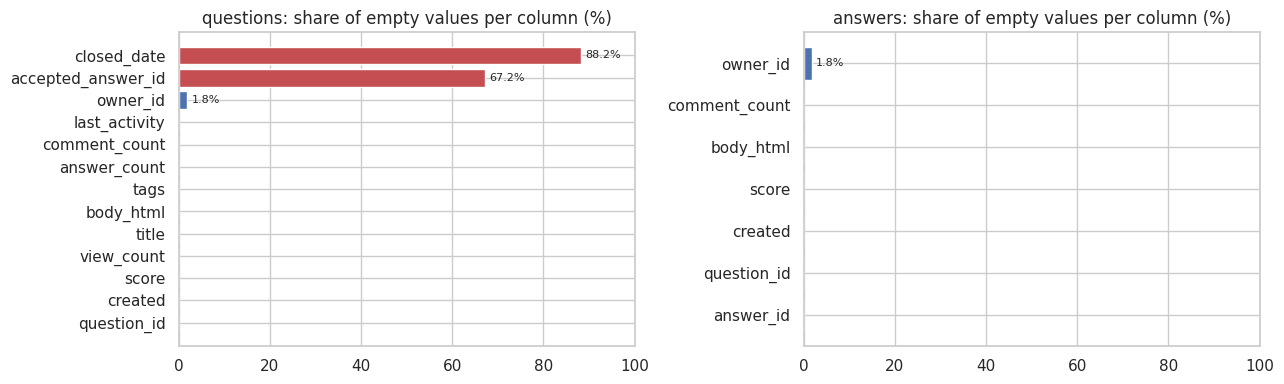

In [15]:
# Visualizing the missing values
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, name in zip(ax, ["questions", "answers"]):
    t = missing[missing.table == name].sort_values("percent")
    a.barh(t.index, t.percent, color=["#c44e52" if p > 50 else "#4c72b0" for p in t.percent])
    a.set_xlim(0, 100)
    a.set_title(f"{name}: share of empty values per column (%)")
    for y, p in enumerate(t.percent):
        if p > 0:
            a.text(p + 1, y, f"{p:.1f}%", va="center", fontsize=8)
save("missing_values")

### What did you know about your dataset?

- **Size:** 414,451 questions and 523,728 answers from July 2010 to March 2024, plus 221,126 links between questions. 42,035 questions were closed as duplicates of 13,750 originals, so a large part of IT support is repeat questions.
- **Quality signals:** each answer has a score (votes) and may be the accepted answer. 67% of the questions have no accepted answer, so the up-votes matter as a second signal of a trusted answer.
- **Text:** titles and bodies are HTML with code blocks, inline code, links and images. Questions have a median of 85 words and trusted answers 83 words.
- **Missing values** are few and meaningful: an empty accepted answer means none was accepted, an empty closed date means the question is still open (88% of questions), and an empty owner means a deleted account (1.8%).
- **Duplicates:** no repeated ids, but 780 titles and 811 answer texts appear more than once. The closed duplicates are not errors: they are useful rephrasings.
- **Newer data:** 2,000 questions after the dump from the API (1,081 usable question-answer pairs), 1,200 off-topic questions from 12 other Stack Exchange sites, 2,959 passages of the official Ubuntu guides (2,940 after cleaning) and 3,329 teacher-refined answers for fine-tuning.
- **Licence:** Stack Exchange content is CC BY-SA, so the source of every item is kept.

## ***2. Understanding Your Variables***

In [16]:
# Dataset Columns
for name, df in [("questions", posts_q), ("answers", posts_a), ("links", links), ("recent questions (API)", recent_raw),
                 ("off-topic questions", off_topic), ("guide passages", docs)]:
    print(f"{name:24s}", list(df.columns))

questions                ['question_id', 'created', 'score', 'view_count', 'title', 'body_html', 'tags', 'answer_count', 'comment_count', 'accepted_answer_id', 'closed_date', 'last_activity', 'owner_id']
answers                  ['answer_id', 'question_id', 'created', 'score', 'body_html', 'comment_count', 'owner_id']
links                    ['question_id', 'related_id', 'link_type']
recent questions (API)   ['question_id', 'title', 'body', 'tags', 'score', 'view_count', 'answer_count', 'accepted_answer_id', 'creation_date', 'closed_reason', 'link', 'answers']
off-topic questions      ['site', 'question_id', 'title', 'tags']
guide passages           ['doc_id', 'site', 'url', 'title', 'section', 'text']


In [17]:
# Dataset Describe
display(posts_q.describe(percentiles=[.25, .5, .75, .95, .99]).round(1))
display(posts_a.describe(percentiles=[.25, .5, .75, .95, .99]).round(1))
display(posts_q[["created", "closed_date"]].describe())

,question_id,created,score,view_count,answer_count,comment_count,accepted_answer_id,closed_date,last_activity
count,414451.0,414451,414451.0,414451.0,414451.0,414451.0,136162.0,48876,414451
mean,782813.6,2016-11-23 01:25:45.427572992,3.3,7050.6,1.3,2.0,677010.3,2016-09-16 14:53:14.261359872,2017-10-29 12:06:01.960573696
min,1.0,2009-01-08 07:47:55.393000,-38.0,4.0,0.0,0.0,2.0,2010-08-15 20:43:58.203000,2010-07-29 14:11:46.233000
25%,395483.5,2013-12-25 06:18:39.333500160,0.0,230.0,1.0,0.0,281562.0,2014-01-14 00:57:10.174749952,2014-11-30 20:56:15.001999872
50%,805573.0,2016-08-01 09:11:03.572999936,1.0,836.0,1.0,1.0,654195.5,2016-08-11 01:28:27.001500160,2017-09-05 20:58:04.889999872
75%,1174916.5,2019-09-18 03:27:31.846499840,2.0,2872.0,2.0,3.0,1048901.8,2018-10-31 21:26:59.570500096,2020-09-18 01:19:29.820000256
95%,1448387.0,2023-01-02 15:57:39.963500032,11.0,22315.0,3.0,7.0,1396650.5,2022-06-04 16:02:01.297250048,2023-07-18 12:16:09.567000064
99%,1497204.5,2023-12-16 01:51:15.531500032,43.0,107814.5,6.0,12.0,1483512.8,2023-10-28 00:53:23.026749952,2024-02-19 21:17:11.048000
max,1509153.0,2024-03-31 23:33:06.157000,2624.0,7736464.0,82.0,56.0,1509474.0,2024-04-03 09:54:38.503000,2024-04-07 06:16:28.347000
std,444851.2,NaN,19.0,50867.7,1.4,2.7,439645.1,NaN,NaN


,answer_id,question_id,created,score,comment_count
count,523728.0,523728.0,523728,523728.0,523728.0
mean,708049.9,633333.0,2016-04-23 17:54:55.221897216,3.9,1.3
min,2.0,1.0,2009-01-08 08:15:28.817000,-11.0,0.0
25%,310767.2,229856.8,2013-06-20 19:45:09.548000,0.0,0.0
50%,689872.5,589631.5,2015-10-25 18:53:47.676499968,1.0,0.0
75%,1096438.5,1003864.8,2018-11-27 09:51:30.547749888,3.0,2.0
95%,1421178.2,1385006.3,2022-07-30 16:16:13.956499968,13.0,6.0
99%,1490598.2,1476010.0,2023-10-27 16:13:11.890299904,52.0,11.0
max,1509152.0,1509070.0,2024-03-31 23:18:55.127000,3020.0,61.0
std,445863.7,439789.5,NaN,21.9,2.3


,created,closed_date
count,414451,48876
mean,2016-11-23 01:25:45.427572992,2016-09-16 14:53:14.261359872
min,2009-01-08 07:47:55.393000,2010-08-15 20:43:58.203000
25%,2013-12-25 06:18:39.333500160,2014-01-14 00:57:10.174749952
50%,2016-08-01 09:11:03.572999936,2016-08-11 01:28:27.001500160
75%,2019-09-18 03:27:31.846499840,2018-10-31 21:26:59.570500096
max,2024-03-31 23:33:06.157000,2024-04-03 09:54:38.503000


### Variables Description 

| Variable | Meaning |
|---|---|
| `question_id`, `answer_id` | ids of the posts; `question_id` in the answers table links an answer to its question |
| `created`, `last_activity`, `closed_date` | when the post was written, last edited or answered, and closed by moderators (empty = open) |
| `score` | up-votes minus down-votes, the community's judgement of the post |
| `view_count`, `answer_count`, `comment_count` | how popular the question is and how much discussion it got |
| `title`, `body_html` | the text of the post, in HTML |
| `tags` | up to five topic labels, for example `networking`, `apt` or `22.04` |
| `accepted_answer_id` | the answer the asker marked as the solution (empty if none) |
| `owner_id` | the author's account id, only used to find answers written by the asker, then dropped |
| `link_type` | 1 = related question, 3 = duplicate of another question |
| recent questions (API) | the same fields for questions from April 2024 to November 2026, with their answers |
| off-topic questions | `site` and `title` of questions from cooking, travel, music and other non-IT sites |
| guide passages | `site`, `url`, `title`, `section` and `text` of the official Ubuntu guides |
| refined answers | `question_id` and `refined`, the teacher's rewrite of the trusted answer |

Features created in the wrangling step include `q_words` and `a_words` (length), `q_has_code` and `a_has_code`, `hours_to_answer`, `ref_type` (accepted or top-voted), `versions` (Ubuntu versions in the tags), `year` and `split`.

### Check Unique Values for each variable.

In [18]:
# Check Unique Values for each variable.
uniq = {}
for name, df in [("questions", posts_q), ("answers", posts_a), ("links", links)]:
    for c in df.columns:
        s = df[c]
        uniq[(name, c)] = s.map(lambda v: tuple(v) if isinstance(v, list) else v).nunique()
uniq = pd.Series(uniq, name="unique values").to_frame()
all_tags = Counter(t for ts in posts_q.tags for t in ts)
print(f"distinct tags: {len(all_tags):,} | questions per tag (median): {np.median(list(all_tags.values())):.0f}")
print("link types:", links.link_type.value_counts().rename({1: "related (1)", 3: "duplicate (3)"}).to_dict())
uniq

distinct tags: 3,162 | questions per tag (median): 48
link types: {'related (1)': 179091, 'duplicate (3)': 42035}


unique values
questions question_id                414451
          created                    414451
          score                         504
          view_count                  37553
          title                      414358
          body_html                  414435
          tags                       231003
          answer_count                   45
          comment_count                  47
          accepted_answer_id         136162
          closed_date                 48876
          last_activity              414445
          owner_id                   221175
answers   answer_id                  523728
          question_id                318537
          created                    523725
          score                         580
          body_html                  522917
          comment_count                  51
          owner_id                   148257
links     question_id                131890
          related_id                  60365
          link_type                       2

## 3. ***Data Wrangling***

### Data Wrangling Code

In [19]:
# Write your code to make your dataset analysis ready.
t0 = time.time()
qa, funnel = itbot.clean_qa(posts_q, posts_a, links)          # one clean question + trusted answer per row
print(f"cleaned in {time.time() - t0:.0f} s\n")
f = pd.Series(funnel, name="questions left").to_frame()
f["removed at this step"] = (-f["questions left"].diff()).fillna(0).astype(int)
f["share of the dump"] = (100 * f["questions left"] / f["questions left"].iloc[0]).round(1).astype(str) + "%"
display(f)

# real re-wordings: questions closed as duplicates, linked to their original's answer
para = itbot.paraphrases(posts_q, links, qa)
para = para[para.dup_title.str.len() > 10].reset_index(drop=True)

# recent questions from the API, cleaned with the same rules, minus anything already in the dump
recent = itbot.clean_api(recent_rows)
recent = recent[~recent.question_id.isin(posts_q.question_id)].reset_index(drop=True)

# off-topic questions: unique titles only
off_topic = off_topic.drop_duplicates("title").reset_index(drop=True)

# guide passages: no copies, at least 25 words
docs = docs.drop_duplicates("text")
docs = docs[docs.text.str.split().str.len() >= 25].reset_index(drop=True)
docs["guide_type"] = docs.url.str.extract(r"/(how-to|explanation|reference|tutorial)s?/")[0].fillna("other")

# time-based split: the model learns from the past and is tested on newer questions, like in real use
qa["split"] = np.select([qa.created < "2023-01-01", qa.created < "2023-07-01"], ["train", "val"], "test")
print(f"paraphrase pairs {len(para):,} | recent API pairs {len(recent):,} | off-topic titles {len(off_topic):,} | guide passages {len(docs):,}")
print(qa.split.value_counts().to_dict())

# what the cleaning does to one answer
ex = qa[qa.answer.str.contains("```") & (qa.a_words.between(40, 90))].iloc[3]
print("\nBEFORE (HTML in the dump):\n", posts_a.loc[posts_a.answer_id == ex.answer_id, "body_html"].iloc[0][:600])
print("\nAFTER (clean text the model learns from):\n", ex.answer[:600])

Path("outputs/data").mkdir(parents=True, exist_ok=True)
qa.drop(columns=["closed_date"]).to_parquet("outputs/data/qa_clean.parquet", compression="zstd")

cleaned in 191 s



,questions left,removed at this step,share of the dump
all questions in the dump,414451,0,100.0%
"not closed (closed, duplicate or off-topic removed)",365575,48876,88.2%
not voted down (score >= 0),358809,6766,86.6%
"has a trusted answer (accepted, or 2+ up-votes)",148112,210697,35.7%
answer is more than a link or a screenshot (15+ words),141662,6450,34.2%
"lengths in range (question 3-600 words, answer up to 800)",137049,4613,33.1%
no exact duplicate questions,137049,0,33.1%


paraphrase pairs 30,306 | recent API pairs 1,081 | off-topic titles 1,200 | guide passages 2,940
{'train': 134621, 'val': 1218, 'test': 1210}

BEFORE (HTML in the dump):
 <p><code>oidentd</code> supports ipv6, but said support doesn't seem to be documented very well (or, y'know, at all...).</p>

<p>After installing it, you'll need to edit <code>/etc/default/oidentd</code> and change this:</p>

<pre><code>OIDENT_OPTIONS="-mf"
</code></pre>

<p>to this:</p>

<pre><code>OIDENT_OPTIONS="-mf -a ::"
</code></pre>

<p>and restart it, then it should listen on all your interfaces (both IPv4 and IPv6).</p>


AFTER (clean text the model learns from):
 `oidentd` supports ipv6, but said support doesn't seem to be documented very well (or, y'know, at all...).

After installing it, you'll need to edit `/etc/default/oidentd` and change this:

```
OIDENT_OPTIONS="-mf"
```

to this:

```
OIDENT_OPTIONS="-mf -a ::"
```

and restart it, then it should listen on all your interfaces (both IPv4 and IPv6).


### What all manipulations have you done and insights you found?

**What I did**
1. **Parsed the dump** (`Posts.xml`, `PostLinks.xml`) into a question table, an answer table and a link table.
2. **Chose one trusted answer per question:** the accepted answer if it has at least one up-vote, otherwise the best answer with 2+ up-votes.
3. **Cleaned the text:** HTML to markdown (code blocks and inline code kept exactly), images and link targets removed, e-mails, user names in prompts and home paths masked, thank-you lines dropped.
4. **Filtered in a funnel:** open questions only, not voted down, with a trusted answer of 15+ words, lengths in range, no exact duplicates. 414,451 questions became 137,049 clean pairs (33.1% of the dump).
5. **Flagged answers the bot must not copy:** self-answers (12.6%) and first-person stories (4.8%). They stay in the search library but not in the fine-tuning data.
6. **Built rephrasings** from duplicate links (30,306 rephrased questions of 10,361 originals) and cleaned the API, off-topic and guide data the same way.
7. **Split by time:** train 134,621 pairs (before 2023), validation 1,218 (January to June 2023), test 1,210 (July 2023 to March 2024).

**What I found**
- Only a third of all questions end with an answer the community trusted, and the share falls every year.
- One in eight trusted answers was written by the person who asked. Left in, the bot would learn to answer as the user ("I fixed it by...").
- Duplicates are concentrated: a small number of original questions collect most of the repeats, which is good news for a bot that searches solved threads.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

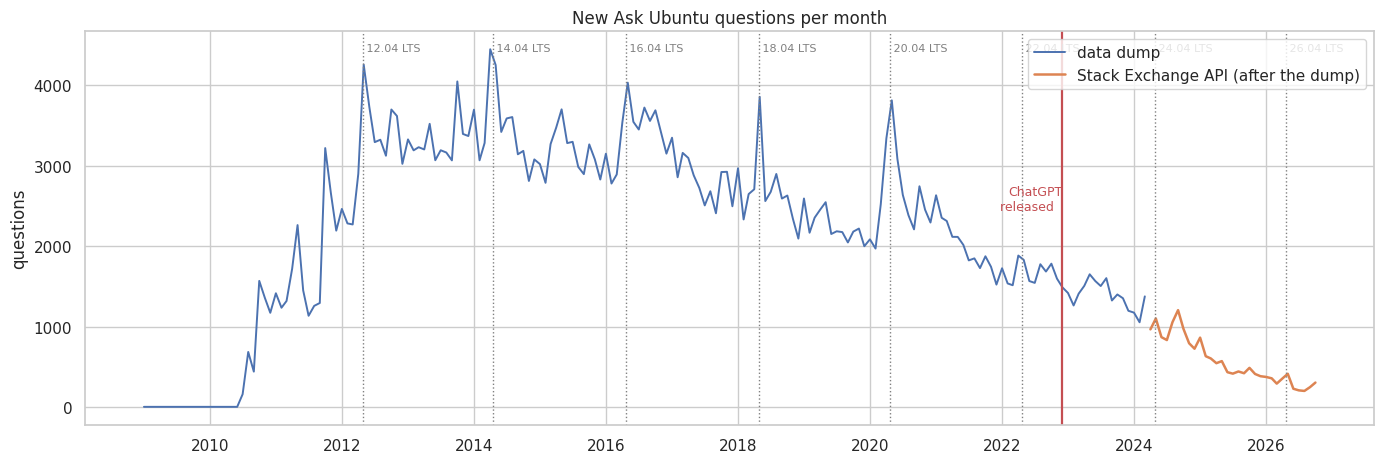

peak: 4,450 questions in April 2014 | 2022 monthly mean 1660 | 2025 monthly mean 516


In [20]:
# Chart - 1 visualization code
# New questions per month, 2010 to today: the dump until March 2024, the Stack Exchange API after that
m_dump = posts_q.set_index("created").resample("MS").size()
m_dump = m_dump[m_dump.index < "2024-04-01"]
m_api = monthly_api[monthly_api.complete].assign(month=lambda d: pd.to_datetime(d.month)).set_index("month").questions
fig, ax = plt.subplots(figsize=(14, 4.8))
ax.plot(m_dump.index, m_dump.values, color="#4c72b0", lw=1.4, label="data dump")
ax.plot(m_api.index, m_api.values, color="#dd8452", lw=1.8, label="Stack Exchange API (after the dump)")
for v, d in [("12.04", "2012-04-26"), ("14.04", "2014-04-17"), ("16.04", "2016-04-21"), ("18.04", "2018-04-26"),
             ("20.04", "2020-04-23"), ("22.04", "2022-04-21"), ("24.04", "2024-04-25"), ("26.04", "2026-04-23")]:
    ax.axvline(pd.Timestamp(d), color="grey", ls=":", lw=1)
    ax.text(pd.Timestamp(d), ax.get_ylim()[1] * 0.97, f" {v} LTS", fontsize=8, color="grey", va="top")
ax.axvline(pd.Timestamp("2022-11-30"), color="#c44e52", lw=1.6)
ax.text(pd.Timestamp("2022-11-30"), m_dump.max() * 0.55, "ChatGPT\nreleased  ", color="#c44e52", ha="right", fontsize=9)
ax.set_title("New Ask Ubuntu questions per month")
ax.set_ylabel("questions")
ax.legend(loc="upper right")
save("chart01_questions_per_month")
peak = m_dump.idxmax()
print(f"peak: {m_dump.max():,} questions in {peak:%B %Y} | 2022 monthly mean {m_dump['2022'].mean():.0f} | "
      f"2025 monthly mean {m_api['2025'].mean():.0f}")

##### 1. Why did you pick the specific chart?

A line over time is the natural way to show activity month by month. Marking the Ubuntu LTS releases and the release of ChatGPT on the same axis lets me check whether the spikes and the drop line up with events in the industry.

##### 2. What is/are the insight(s) found from the chart?

- Questions rose quickly after Ask Ubuntu opened and peaked at **4,450 in April 2014**. Every LTS release (12.04 to 20.04) produced a spike in its release month.
- From 2016 the volume fell steadily: **1,660 a month in 2022** and **516 a month in 2025** (from the API), less than a third of 2022.
- The fall did not start with ChatGPT (November 2022), but it continued after it.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** demand for help peaks at every LTS release, so a bot that is updated before a release can take most of that wave. **Negative:** fewer people ask and answer on the site, so new trusted answers for recent Ubuntu versions are scarce. This is why the project adds the official guides and the API questions, and tests on questions from after the dump.

#### Chart - 2

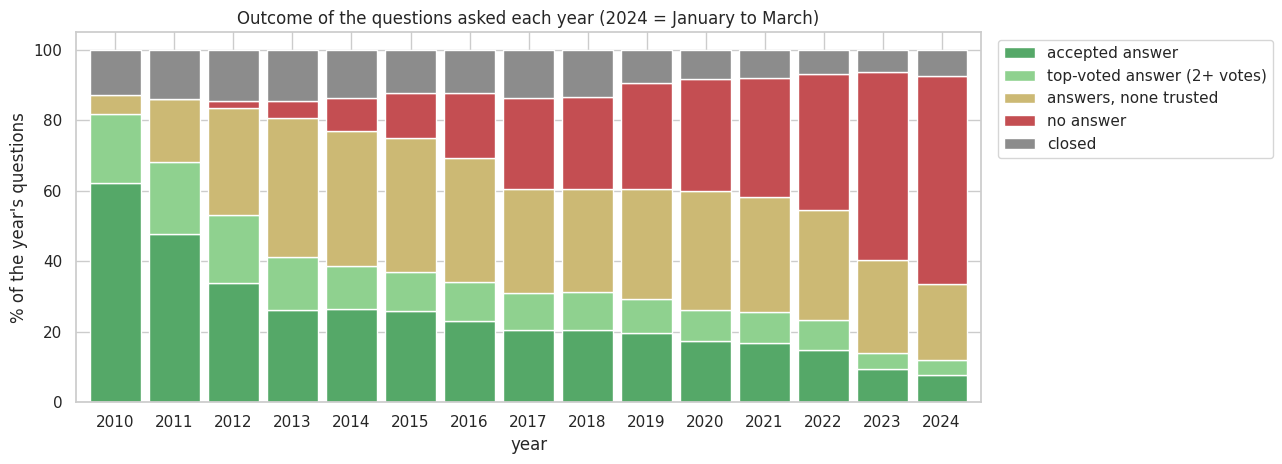

status,accepted answer,top-voted answer (2+ votes),"answers, none trusted",no answer,closed
year,,,,,
2012,33.8,19.3,30.5,1.8,14.6
2016,23.0,11.3,35.0,18.5,12.3
2020,17.5,8.7,33.6,32.0,8.1
2023,9.4,4.6,26.4,53.3,6.2


In [21]:
# Chart - 2 visualization code
# What happened to the questions of each year: trusted answer, other answers only, no answer, closed
ref_ids = (itbot.pick_reference(posts_q[posts_q.closed_date.isna()], posts_a)[["question_id", "ref_type", "created"]]
           .rename(columns={"created": "answer_created"}))
st = posts_q[["question_id", "created", "answer_count", "closed_date"]].merge(ref_ids, on="question_id", how="left")
st["wait_h"] = (st.answer_created - st.created).dt.total_seconds() / 3600
st["status"] = np.select([st.closed_date.notna(), st.ref_type == "accepted", st.ref_type == "top_voted", st.answer_count > 0],
                         ["closed", "accepted answer", "top-voted answer (2+ votes)", "answers, none trusted"], "no answer")
st["year"] = st.created.dt.year
share = pd.crosstab(st.year, st.status, normalize="index").loc[2010:2024] * 100
order = ["accepted answer", "top-voted answer (2+ votes)", "answers, none trusted", "no answer", "closed"]
share[order].plot(kind="bar", stacked=True, figsize=(13, 4.8), width=0.85,
                  color=["#55a868", "#8fd18f", "#ccb974", "#c44e52", "#8c8c8c"])
plt.ylabel("% of the year's questions")
plt.title("Outcome of the questions asked each year (2024 = January to March)")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xticks(rotation=0)
save("chart02_question_outcomes")
display(share[order].round(1).loc[[2012, 2016, 2020, 2023]])

##### 1. Why did you pick the specific chart?

A stacked bar per year shows the full outcome of every question (trusted answer, weaker answers, no answer, closed) and how the mix changes. It tells me how much usable training data each year can give.

##### 2. What is/are the insight(s) found from the chart?

- In 2012, **33.8%** of questions got an accepted answer and only **1.8%** got no answer at all.
- By 2023, accepted answers fell to **9.4%** and questions with **no answer rose to 53.3%**.
- The share closed by moderators also fell, from 14.6% to 6.2%.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** more than half of new questions now go unanswered, which is the clearest sign of unmet demand that an automated assistant can serve. **Negative:** the supply of trusted answers is concentrated in older years (the median training answer is from 2016), so the bot risks giving old advice. The fine-tuning data is therefore sampled evenly across years, and only answers from 2014 on are used.

#### Chart - 3

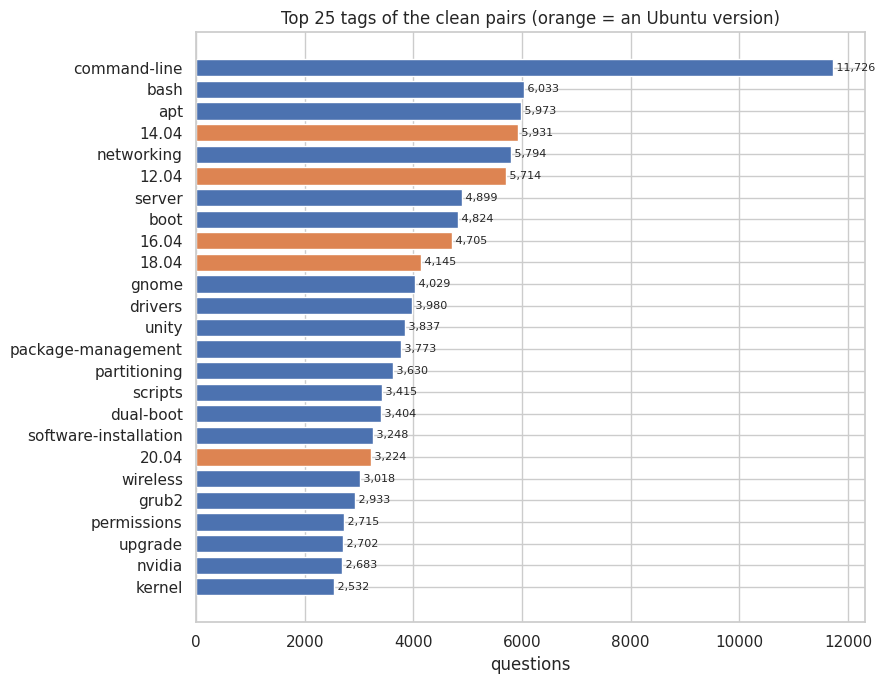

3,057 tags in use; the top 25 cover 29% of all tag uses


In [22]:
# Chart - 3 visualization code
# The 25 most common tags of the clean question/answer pairs
tag_counts = Counter(t for ts in qa.tags for t in ts)
top = pd.Series(dict(tag_counts.most_common(25))).sort_values()
plt.figure(figsize=(9, 7))
plt.barh(top.index, top.values, color=["#dd8452" if re.match(r"^\d", t) else "#4c72b0" for t in top.index])
plt.title("Top 25 tags of the clean pairs (orange = an Ubuntu version)")
plt.xlabel("questions")
for y, v in enumerate(top.values):
    plt.text(v, y, f" {v:,}", va="center", fontsize=8)
save("chart03_top_tags")
print(f"{len(tag_counts):,} tags in use; the top 25 cover {sum(top.values) / sum(tag_counts.values()):.0%} of all tag uses")

##### 1. Why did you pick the specific chart?

A horizontal bar chart is the clearest way to rank 25 categories with long names. It shows what the bot will be asked most often.

##### 2. What is/are the insight(s) found from the chart?

- `command-line` is by far the largest tag (**11,726** clean pairs), followed by `bash` (6,033), `apt` (5,973), `networking` (5,794), `server` (4,899) and `boot` (4,824).
- Five Ubuntu versions are in the top 25, led by 14.04 (5,931) and 12.04 (5,714).
- There are 3,057 tags in use and the top 25 cover only 29% of tag uses: a long tail.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the bot's core topics are clear (the terminal, packages, networking, boot and drivers), and these are the areas where good answers save a support desk the most time. **Negative:** the long tail of 3,057 tags cannot all be learned by a small model, so the bot also needs the search library, and the oldest version tags show how much of the data is about releases nobody uses any more.

#### Chart - 4

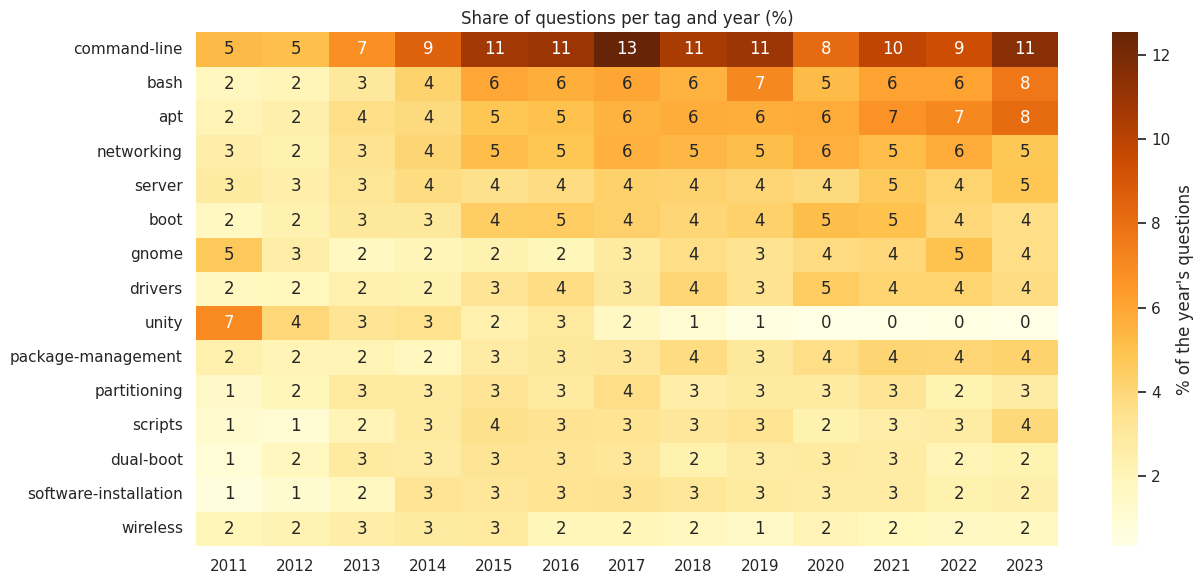

In [23]:
# Chart - 4 visualization code
# How the topics changed: share of each year's questions that carry a tag (top 15 tags, ignoring version tags)
topic_tags = [t for t, _ in tag_counts.most_common(60) if not re.match(r"^\d", t)][:15]
yrs = qa[qa.year.between(2011, 2023)]
heat = pd.DataFrame({t: yrs.groupby("year").tags.apply(lambda s: s.map(lambda ts: t in ts).mean() * 100) for t in topic_tags}).T
plt.figure(figsize=(13, 6))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="YlOrBr", cbar_kws={"label": "% of the year's questions"})
plt.title("Share of questions per tag and year (%)")
plt.xlabel("")
save("chart04_tag_trends")

##### 1. Why did you pick the specific chart?

A heatmap fits a table of 15 tags by 13 years and makes trends visible at a glance (a colour that fades or grows along a row). Topics that change over time matter because the bot must not give out-of-date advice.

##### 2. What is/are the insight(s) found from the chart?

- `unity` fell from **7% of questions in 2011 to 0% from 2020**, after Ubuntu dropped the Unity desktop.
- `command-line` doubled from 5% to 11-13%, and `apt` and `bash` grew from 2% to **8% in 2023**.
- `gnome` came back after 2018 (3-5%) when Ubuntu returned to GNOME; `networking` stayed steady at about 5%.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the topics that grow (the terminal, apt, scripting, GNOME) are the ones a text bot handles well. **Negative:** answers about Unity and other retired parts are useless today. They remain in the library for old systems, but the training pool starts in 2014 so the bot does not learn them as the default.

#### Chart - 5

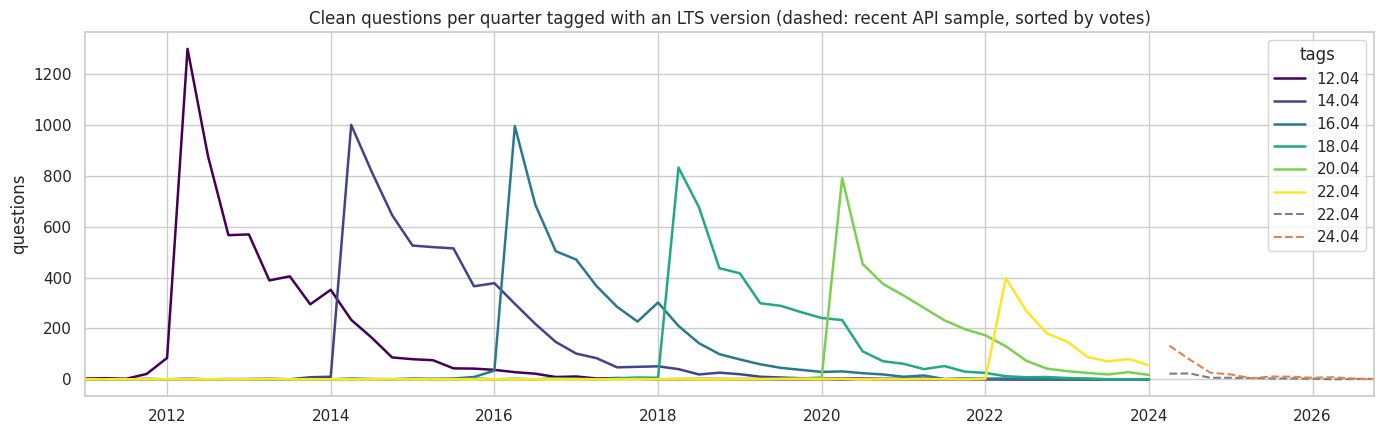

peak quarter per version: {'12.04': '2012-04', '14.04': '2014-04', '16.04': '2016-04', '18.04': '2018-04', '20.04': '2020-04', '22.04': '2022-04'}


In [24]:
# Chart - 5 visualization code
# Life cycle of each long-term-support release: questions tagged with the version, per quarter
lts = ["12.04", "14.04", "16.04", "18.04", "20.04", "22.04"]
vq = qa[["created", "tags"]].explode("tags")
vq = vq[vq.tags.isin(lts)]
counts = vq.groupby([pd.Grouper(key="created", freq="QS"), "tags"]).size().unstack(fill_value=0)
recent_v = recent.explode("tags")
recent_v = recent_v[recent_v.tags.isin(["22.04", "24.04"])].groupby([pd.Grouper(key="created", freq="QS"), "tags"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(14, 4.5))
counts.plot(ax=ax, lw=1.8, colormap="viridis")
if len(recent_v):
    recent_v.plot(ax=ax, ls="--", lw=1.5, color=["#7f7f7f", "#dd8452"][: recent_v.shape[1]])
ax.set_title("Clean questions per quarter tagged with an LTS version (dashed: recent API sample, sorted by votes)")
ax.set_ylabel("questions")
ax.set_xlabel("")
save("chart05_version_lifecycle")
print("peak quarter per version:", {v: f"{counts[v].idxmax():%Y-%m}" for v in lts if v in counts})

##### 1. Why did you pick the specific chart?

One line per LTS version over time shows each release's life cycle. This tells me how long questions about a version keep coming, and so how old an answer can be and still be useful.

##### 2. What is/are the insight(s) found from the chart?

- Each LTS version's questions peak in the quarter it is released: **12.04 in 2012-04, 14.04 in 2014-04, up to 22.04 in 2022-04**.
- After the peak, questions about a version fade over two to three years, while the next release takes over.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a version's answers stay useful for about two years, so a bot refreshed with every LTS release (April of even years) can stay current. **Negative:** the dump stops before 24.04 became the main version; 24.04 appears in 27% of the newer API questions. Without the newer data and the guides, the bot would always be one release behind.

#### Chart - 6

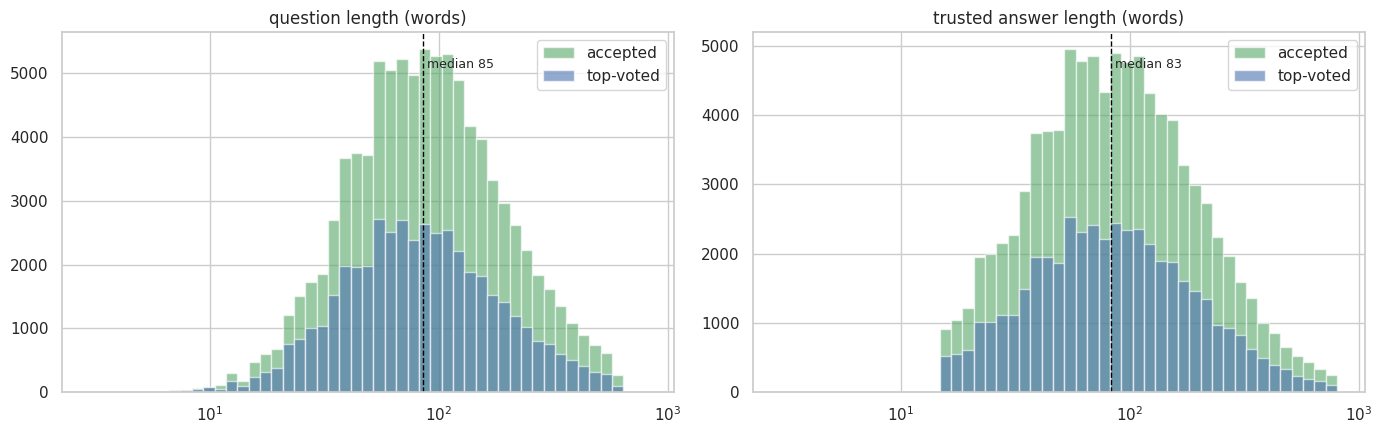

           q_words  a_words
ref_type                   
accepted      86.0     84.0
top_voted     81.0     81.0


In [25]:
# Chart - 6 visualization code
# How long questions and trusted answers are (words, log scale)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
bins = np.logspace(np.log10(3), np.log10(800), 50)
for a, col, title in [(ax[0], "q_words", "question length"), (ax[1], "a_words", "trusted answer length")]:
    for kind, color in [("accepted", "#55a868"), ("top_voted", "#4c72b0")]:
        a.hist(qa.loc[qa.ref_type == kind, col], bins=bins, alpha=0.6, label=kind.replace("_", "-"), color=color)
    a.axvline(qa[col].median(), color="black", ls="--", lw=1)
    a.text(qa[col].median(), a.get_ylim()[1] * 0.9, f" median {qa[col].median():.0f}", fontsize=9)
    a.set_xscale("log")
    a.set_title(title + " (words)")
    a.legend()
save("chart06_lengths")
print(qa.groupby("ref_type")[["q_words", "a_words"]].median())

##### 1. Why did you pick the specific chart?

Histograms on a log scale suit word counts, which are very skewed. Splitting accepted and top-voted answers checks whether the two kinds of trusted answers look alike. The lengths also set the token limits for fine-tuning.

##### 2. What is/are the insight(s) found from the chart?

- Questions have a median of **85 words** and trusted answers **83 words**; both have long right tails.
- Accepted answers and top-voted answers have almost the same shape (medians 84 and 81 words), so the two kinds of trusted answers can be treated alike.
- 95% of trusted answers are shorter than about 600 tokens.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a token limit of 1,024 per training example covers nearly all question and answer pairs, so little is cut. The chart also sets the target length: a good support answer is about 80 to 120 words, and the final bot writes 108 on average. **Negative:** none found; very long answers are rare and are dropped by the length filter.

#### Chart - 7

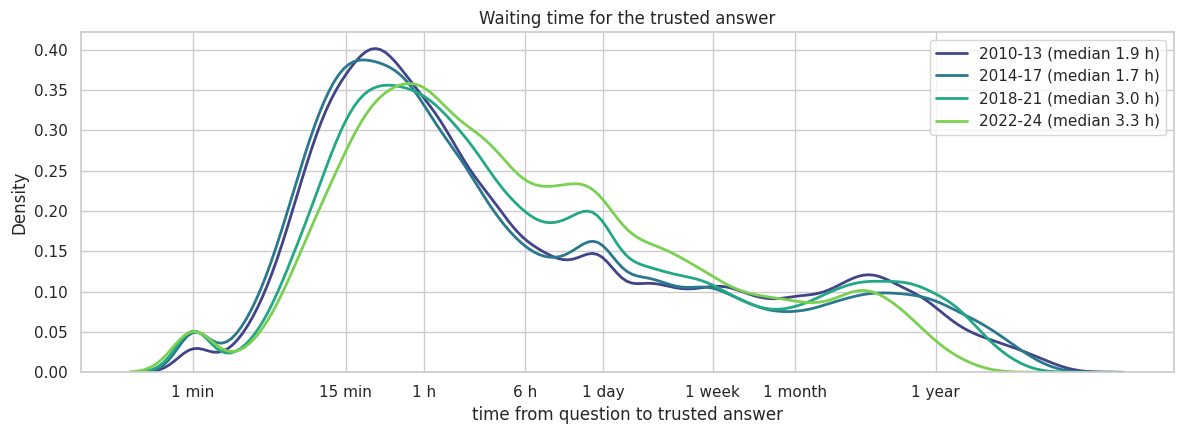

period
2010-13    69.4
2014-17    70.5
2018-21    68.7
2022-24    71.0
Name: % answered within a day, dtype: float64


In [26]:
# Chart - 7 visualization code
# How long people waited for the trusted answer, by period
qa["period"] = pd.cut(qa.year, [2009, 2013, 2017, 2021, 2024], labels=["2010-13", "2014-17", "2018-21", "2022-24"])
w = qa.dropna(subset=["hours_to_answer"])
plt.figure(figsize=(12, 4.5))
for p, c in zip(w.period.cat.categories, sns.color_palette("viridis", 4)):
    h = np.log10(w.loc[w.period == p, "hours_to_answer"].clip(lower=1 / 60))
    sns.kdeplot(h, label=f"{p} (median {10 ** h.median():.1f} h)", color=c, lw=2, bw_adjust=0.7)
ticks = [1 / 60, 0.25, 1, 6, 24, 24 * 7, 24 * 30, 24 * 365]
plt.xticks(np.log10(ticks), ["1 min", "15 min", "1 h", "6 h", "1 day", "1 week", "1 month", "1 year"])
plt.xlabel("time from question to trusted answer")
plt.title("Waiting time for the trusted answer")
plt.legend()
save("chart07_waiting_time")
print((w.groupby("period").hours_to_answer.apply(lambda s: (s <= 24).mean() * 100)).round(1).rename("% answered within a day"))

##### 1. Why did you pick the specific chart?

Density curves of the waiting time on a log axis (minutes to years) compare four periods on one chart. Waiting time is the business problem a bot can remove.

##### 2. What is/are the insight(s) found from the chart?

- The median wait for a trusted answer grew from **1.7-1.9 hours (2010-2017) to 3.0-3.3 hours (2018-2024)**.
- About **70%** of trusted answers arrive within a day in every period, but there is a long tail of weeks, months and even years.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the bot answers in about five seconds, against a median wait of more than three hours and more than a day for three in ten users. That is the main business value: fewer users stuck waiting, and fewer tickets for human support. **Negative:** the community still answers most questions within a day, so the bot has to be good enough to be preferred over waiting.

#### Chart - 8

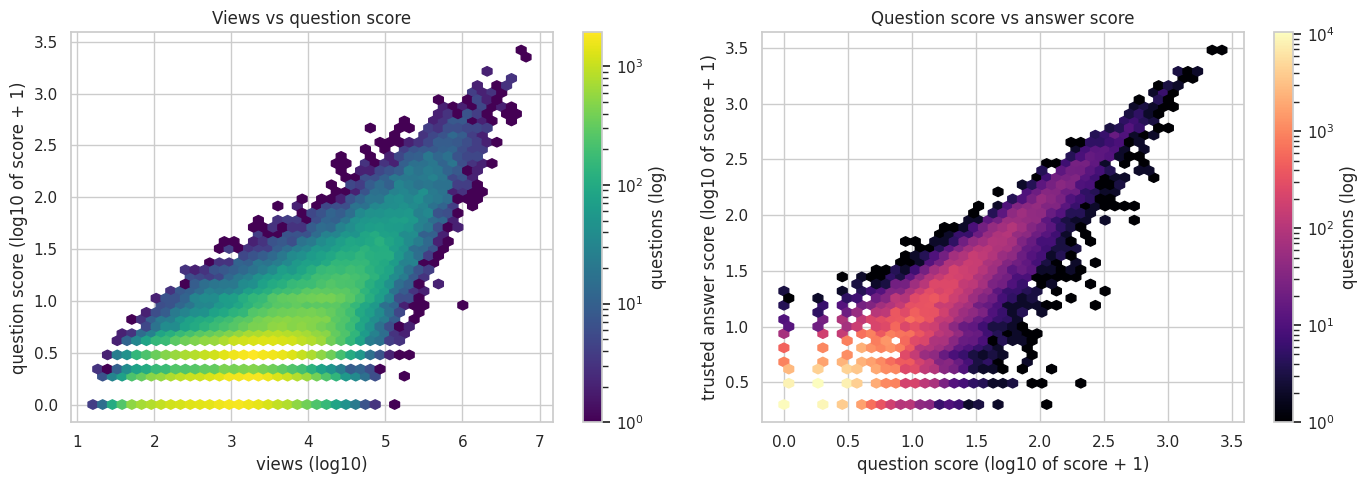

Spearman: views~q_score 0.61 | q_score~a_score 0.71


In [27]:
# Chart - 8 visualization code
# Popularity: how often a question is viewed vs its score, and the answer's score
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
hb = ax[0].hexbin(np.log10(qa.view_count + 1), np.log10(qa.q_score + 1), gridsize=45, bins="log", cmap="viridis", mincnt=1)
ax[0].set_xlabel("views (log10)")
ax[0].set_ylabel("question score (log10 of score + 1)")
ax[0].set_title("Views vs question score")
fig.colorbar(hb, ax=ax[0], label="questions (log)")
hb = ax[1].hexbin(np.log10(qa.q_score + 1), np.log10(qa.a_score + 1), gridsize=45, bins="log", cmap="magma", mincnt=1)
ax[1].set_xlabel("question score (log10 of score + 1)")
ax[1].set_ylabel("trusted answer score (log10 of score + 1)")
ax[1].set_title("Question score vs answer score")
fig.colorbar(hb, ax=ax[1], label="questions (log)")
save("chart08_popularity")
print("Spearman: views~q_score", round(stats.spearmanr(qa.view_count, qa.q_score)[0], 2),
      "| q_score~a_score", round(stats.spearmanr(qa.q_score, qa.a_score)[0], 2))

##### 1. Why did you pick the specific chart?

Hexbin plots handle 137,000 points without turning into a blob, and the log scales fit the skewed counts. They show whether popular questions also get better answers.

##### 2. What is/are the insight(s) found from the chart?

- Popular questions get higher scores (Spearman **0.61** between views and question score).
- Highly rated questions also get highly rated answers (**0.71** between question score and answer score).
- Most questions sit at low scores, with a thin band of famous questions at the top.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the score is a reliable quality signal, so "accepted or 2+ up-votes" is a sound rule for a trusted answer. **Negative:** the rule favours popular problems; rare problems have fewer trusted answers, so the bot will be weaker on niche hardware and software.

#### Chart - 9

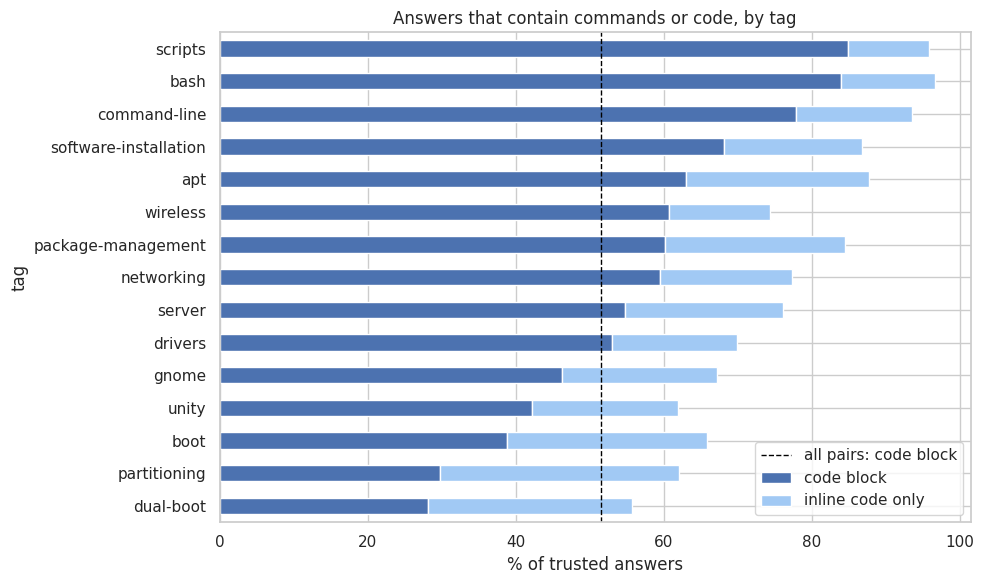

In [28]:
# Chart - 9 visualization code
# How often the trusted answer contains a command or code, for the 15 biggest topic tags
rows = []
for t in topic_tags:
    s = qa[qa.tags.map(lambda ts: t in ts)]
    rows.append({"tag": t, "code block": (s.a_code_blocks > 0).mean() * 100,
                 "inline code only": ((s.a_code_blocks == 0) & (s.a_inline_code > 0)).mean() * 100})
code_by_tag = pd.DataFrame(rows).set_index("tag").sort_values("code block")
code_by_tag.plot(kind="barh", stacked=True, figsize=(10, 6), color=["#4c72b0", "#a1c9f4"])
plt.axvline((qa.a_code_blocks > 0).mean() * 100, color="black", ls="--", lw=1, label="all pairs: code block")
plt.xlabel("% of trusted answers")
plt.title("Answers that contain commands or code, by tag")
plt.legend(loc="lower right")
save("chart09_code_by_tag")

##### 1. Why did you pick the specific chart?

A stacked horizontal bar per tag shows how often the trusted answer contains a command. This tells me whether a metric that checks commands is fair across topics.

##### 2. What is/are the insight(s) found from the chart?

- About **85%** of trusted answers tagged `scripts` or `bash` contain a code block, and more than 95% contain some code.
- `dual-boot` (28%) and `partitioning` (30%) have the fewest code blocks: their answers explain GUI steps and choices.
- Across all pairs, about half of the trusted answers (52%) have a code block.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** for most topics, checking whether the bot names the same commands as the trusted answer (command recall) is a fair test of a correct fix. **Negative:** for dual-boot and partitioning, command recall says little, so the project also uses semantic similarity and LLM judges, which do not depend on code.

#### Chart - 10

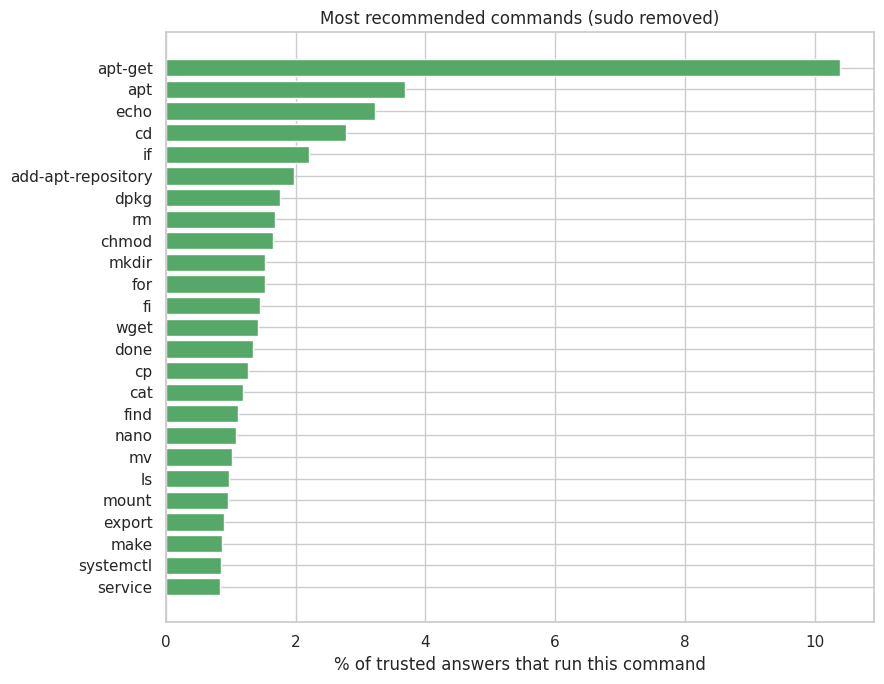

In [29]:
# Chart - 10 visualization code
# The commands the community recommends most: first word of each line in the answers' code blocks
def first_commands(text):
    out = []
    for block in re.findall(r"```(.*?)```", text, re.S):
        for line in block.splitlines():
            w = line.strip().lstrip("$#> ").split()
            while w and w[0] in ("sudo", "-E", "-H", "-i", "-s"):
                w = w[1:]
            if w and re.match(r"^[a-z][\w.+-]{1,25}$", w[0]):
                out.append(w[0])
    return out

cmd_counts = Counter(c for t in qa.answer for c in set(first_commands(t)))
top_cmd = pd.Series(dict(cmd_counts.most_common(25))).sort_values()
plt.figure(figsize=(9, 7))
plt.barh(top_cmd.index, top_cmd.values / len(qa) * 100, color="#55a868")
plt.xlabel("% of trusted answers that run this command")
plt.title("Most recommended commands (sudo removed)")
save("chart10_top_commands")

##### 1. Why did you pick the specific chart?

A ranked bar chart of the first word of each command line shows which tools the community recommends. That is the knowledge the fine-tuned model should pick up.

##### 2. What is/are the insight(s) found from the chart?

- `apt-get` appears in **10.4%** of trusted answers, far ahead of `apt` (3.7%), `echo` (3.2%) and `cd` (2.8%).
- Package tools fill the list: `add-apt-repository` (2.0%), `dpkg` (1.7%), `wget`; system tools such as `systemctl` (0.8%) come lower.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** most fixes are about installing, removing or repairing packages, so getting apt, dpkg and PPAs right covers a large share of real tickets. **Negative:** the older `apt-get` dominates because most answers are old; the bot may prefer it even where `apt` is the current advice. Both work, so this is a style issue more than an error.

#### Chart - 11

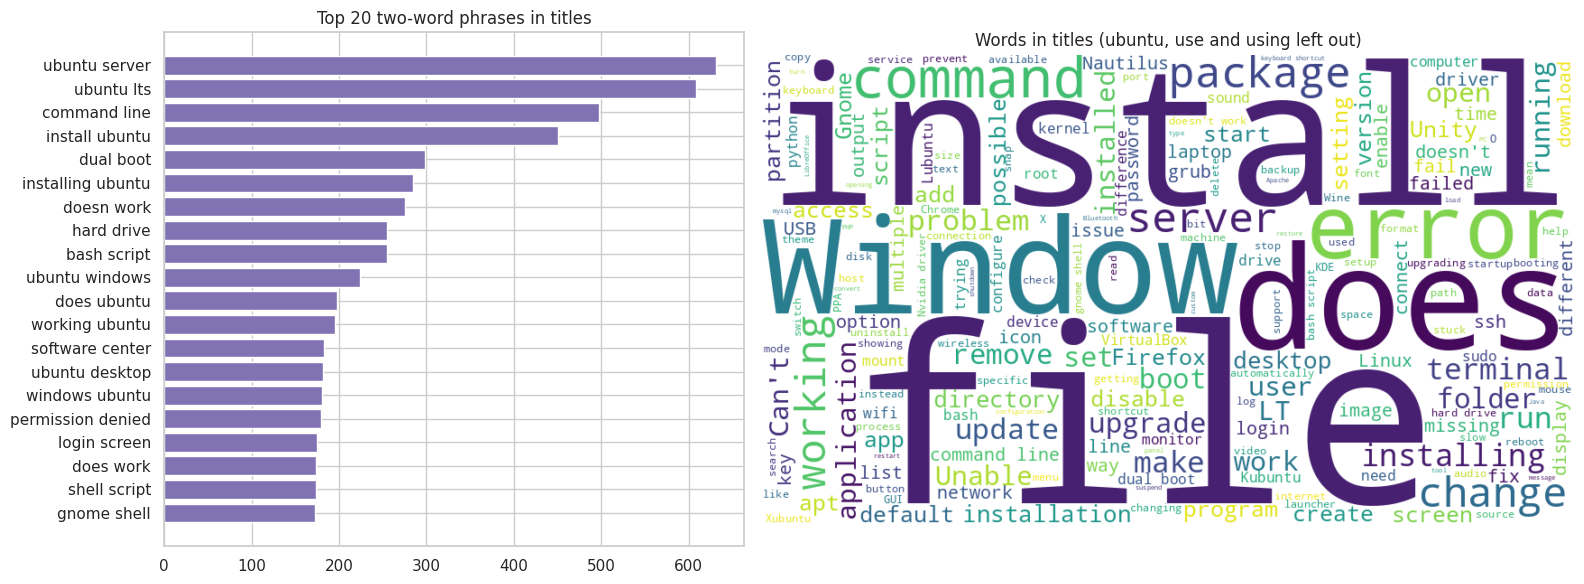

titles by first word (%): {'other': 55.4, 'how': 24.8, 'ubuntu': 4.2, 'what': 3.3, 'can': 3.2, 'why': 3.0, 'is': 2.9, 'unable': 1.1}


In [30]:
# Chart - 11 visualization code
# What people ask: the most common two-word phrases in titles, and a word cloud of title words
from sklearn.feature_extraction.text import CountVectorizer
from wordcloud import WordCloud
sample_titles = qa.title.sample(min(60000, len(qa)), random_state=SEED)
cv = CountVectorizer(ngram_range=(2, 2), stop_words="english", min_df=5, token_pattern=r"(?u)\b[a-zA-Z][\w.-]+\b")
bigrams = pd.Series(np.asarray(cv.fit_transform(sample_titles.str.lower()).sum(0)).ravel(), cv.get_feature_names_out())
bigrams = bigrams.sort_values().tail(20)
fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1.4]})
ax[0].barh(bigrams.index, bigrams.values, color="#8172b3")
ax[0].set_title("Top 20 two-word phrases in titles")
wc = WordCloud(width=900, height=520, background_color="white", colormap="viridis", random_state=SEED,
               stopwords=set(CountVectorizer(stop_words="english").get_stop_words()) | {"ubuntu", "using", "use"})
ax[1].imshow(wc.generate(" ".join(sample_titles)), interpolation="bilinear")
ax[1].axis("off")
ax[1].set_title("Words in titles (ubuntu, use and using left out)")
save("chart11_title_phrases")
first = qa.title.str.lower().str.extract(r"^(how|why|what|can|is|unable|cannot|can't|error|problem|ubuntu)\b")[0].fillna("other")
print("titles by first word (%):", (first.value_counts(normalize=True) * 100).round(1).head(8).to_dict())

##### 1. Why did you pick the specific chart?

Two-word phrases show the typical problems better than single words, and the word cloud gives a quick overall picture of the vocabulary of IT support questions.

##### 2. What is/are the insight(s) found from the chart?

- The most common two-word phrases are **"ubuntu server"** (about 630 titles), **"ubuntu lts"** (610), **"command line"** (500), **"install ubuntu"** (450) and **"dual boot"** (300).
- Problem phrases follow: "doesn't work", "hard drive", "bash script", "permission denied", "login screen".
- A quarter of titles (24.8%) start with "how"; the word cloud is led by install, file, Windows, error and package.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the example questions in the chat app and the off-topic checks were chosen from these themes, so the demo reflects what users really ask. **Negative:** many titles only say that something "doesn't work", so questions are often vague; the bot must work from the body text and the library rather than the title alone.

#### Chart - 12

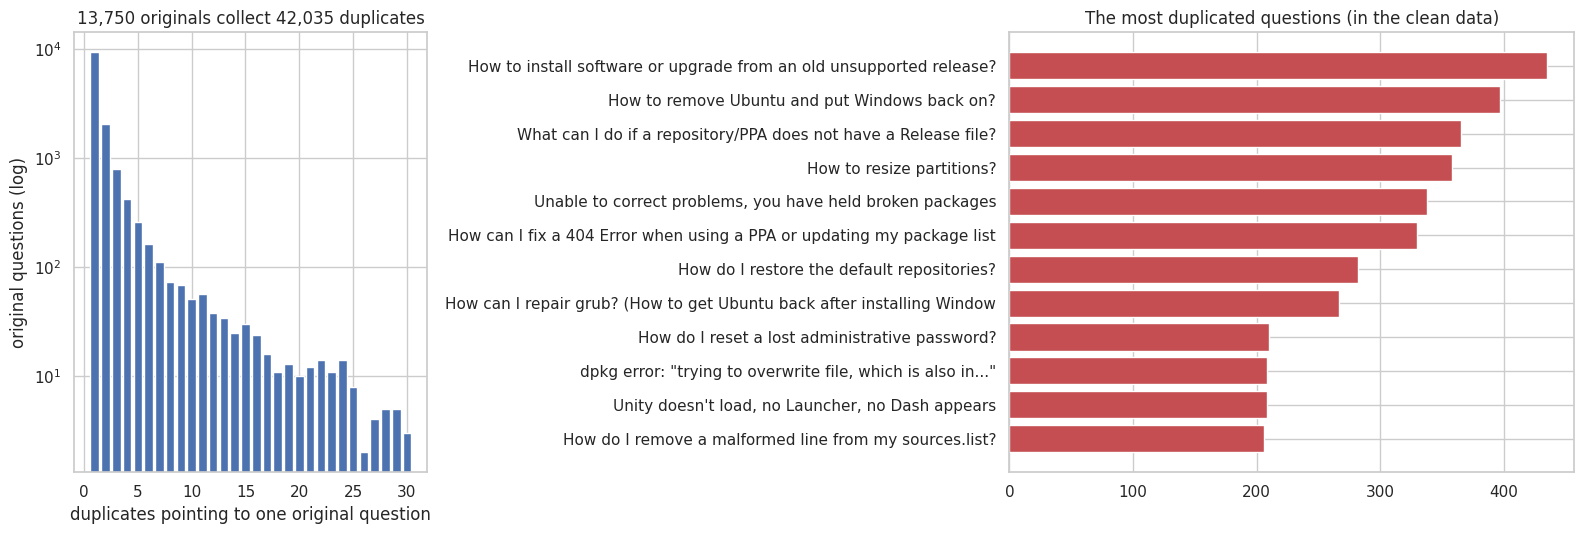

the top 1% of originals (137) receive 34% of all duplicates


In [31]:
# Chart - 12 visualization code
# Questions asked again and again: how many duplicates point to each original, and the most duplicated ones
n_dup = links[links.link_type == 3].groupby("related_id").size()
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1, 1.6]})
vals = n_dup.value_counts().sort_index()
ax[0].bar(vals.index[:30], vals.values[:30], color="#4c72b0")
ax[0].set_yscale("log")
ax[0].set_xlabel("duplicates pointing to one original question")
ax[0].set_ylabel("original questions (log)")
ax[0].set_title(f"{len(n_dup):,} originals collect {n_dup.sum():,} duplicates")
most = qa.sort_values("n_duplicates", ascending=False).head(12)
ax[1].barh(most.title.str[:70][::-1], most.n_duplicates[::-1], color="#c44e52")
ax[1].set_title("The most duplicated questions (in the clean data)")
save("chart12_duplicates")
top1 = n_dup.sort_values(ascending=False)
print(f"the top 1% of originals ({int(len(top1) * 0.01)}) receive {top1.head(int(len(top1) * 0.01)).sum() / top1.sum():.0%} of all duplicates")

##### 1. Why did you pick the specific chart?

The distribution of duplicates per original (log scale) and the list of the most duplicated questions show how repetitive support questions are, which is the main argument for a bot that searches solved threads.

##### 2. What is/are the insight(s) found from the chart?

- **13,750** original questions collect **42,035** duplicates. Most originals get one or two, but the **top 1% (137 questions) receive 34%** of all duplicates.
- The most repeated problems are installing from an old unsupported release (about 430 duplicates), removing Ubuntu and going back to Windows (about 395), broken PPAs, resizing partitions, held broken packages and repairing GRUB.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a few hundred canonical answers solve a third of all repeat questions, so a bot that knows them, and can find them in its library, removes a large share of support work cheaply. The duplicates also give 30,306 human rephrasings, used to tune the search and to train the bot on different wordings. **Negative:** none for the bot; for the community it shows how much time goes into answering the same thing again.

#### Chart - 13

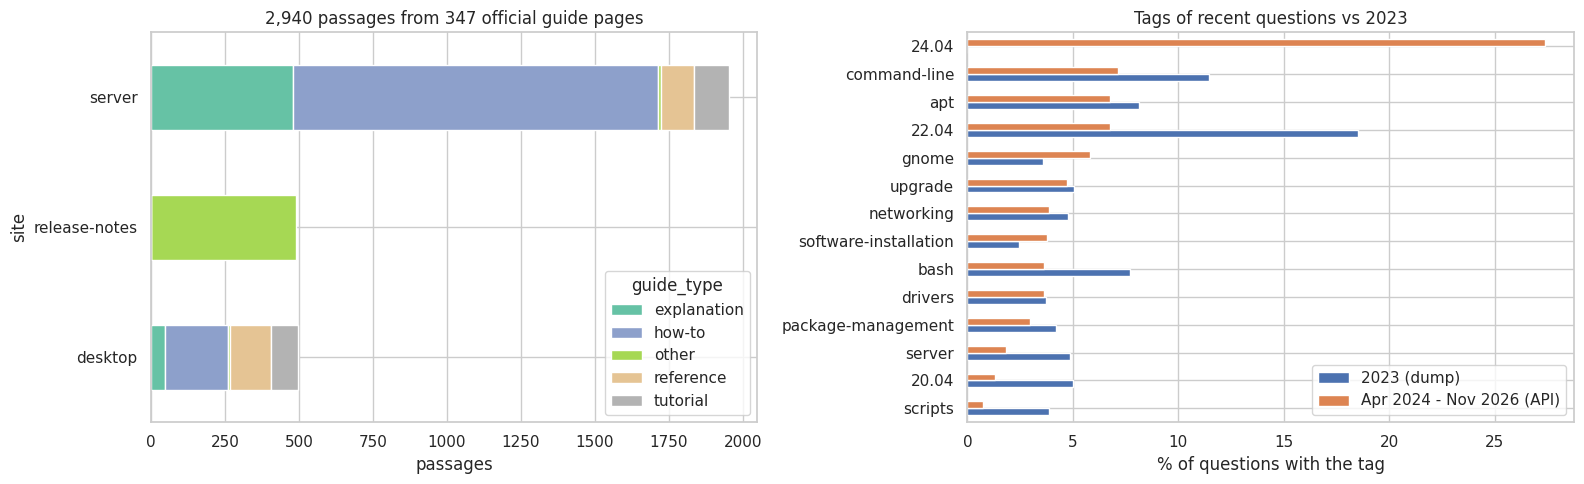

In [32]:
# Chart - 13 visualization code
# The newer data: guide passages by site and type, and what recent questions are about compared with 2023
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
gd = pd.crosstab(docs.site, docs.guide_type)
gd.plot(kind="barh", stacked=True, ax=ax[0], colormap="Set2")
ax[0].set_title(f"{len(docs):,} passages from {docs.url.nunique()} official guide pages")
ax[0].set_xlabel("passages")
r_share = pd.Series(Counter(t for ts in recent.tags for t in ts)) / len(recent) * 100
q23 = qa[qa.year == 2023]
o_share = pd.Series(Counter(t for ts in q23.tags for t in ts)) / len(q23) * 100
cmp = pd.DataFrame({"2023 (dump)": o_share, "Apr 2024 - Nov 2026 (API)": r_share}).fillna(0)
cmp = cmp.loc[cmp.max(1).sort_values(ascending=False).index[:14]].sort_values("Apr 2024 - Nov 2026 (API)")
cmp.plot(kind="barh", ax=ax[1], color=["#4c72b0", "#dd8452"])
ax[1].set_xlabel("% of questions with the tag")
ax[1].set_title("Tags of recent questions vs 2023")
save("chart13_new_data")

##### 1. Why did you pick the specific chart?

The two newer sources need their own check: the guide passages by site and type, and a side-by-side bar of tags in 2023 vs after the dump, which shows how the questions moved on.

##### 2. What is/are the insight(s) found from the chart?

- The 2,940 guide passages come from 347 official pages: the Server guide gives most of them (mostly how-to and explanation pages), the release notes about 490 and the Desktop guide about 500.
- After the dump, **24.04 appears in 27% of new questions** while 22.04 drops from 18.5% (2023) to about 7%.
- `bash` (7.7% to 3.6%) and `scripts` (3.8% to 0.7%) fall, while `gnome` and `software-installation` rise.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the guides (up to Ubuntu 26.04) and the API questions cover the newest releases, which the dump cannot. The "future" test set uses exactly these questions to check that the bot still works on new topics. **Negative:** the shift in topics means part of the dump's knowledge ages quickly, and the newer sources are much smaller.

#### Chart - 14 - Correlation Heatmap

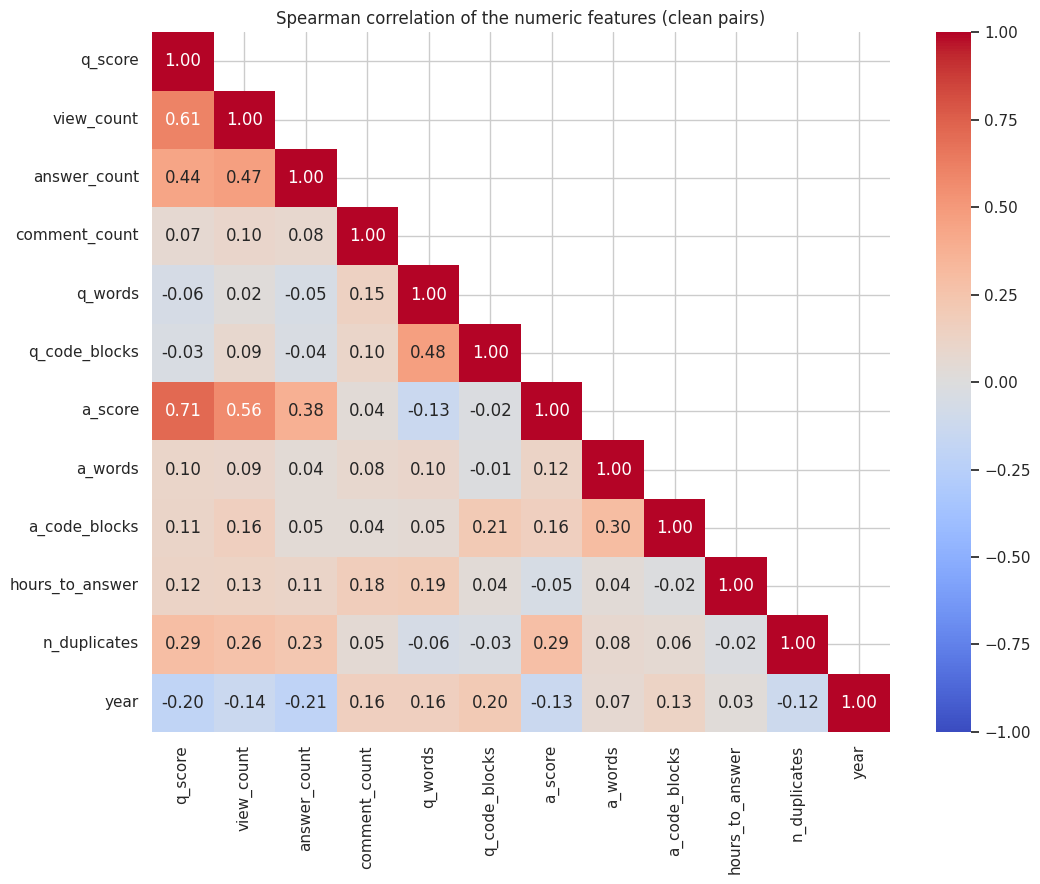

In [33]:
# Correlation Heatmap visualization code
num_cols = ["q_score", "view_count", "answer_count", "comment_count", "q_words", "q_code_blocks", "a_score", "a_words",
            "a_code_blocks", "hours_to_answer", "n_duplicates", "year"]
corr = qa[num_cols].corr(method="spearman")
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, mask=np.triu(np.ones_like(corr, dtype=bool), 1))
plt.title("Spearman correlation of the numeric features (clean pairs)")
save("chart14_correlation")

##### 1. Why did you pick the specific chart?

A correlation heatmap shows all pairs of numeric features at once. I used Spearman correlation because the counts are skewed and the relations are monotonic but not linear.

##### 2. What is/are the insight(s) found from the chart?

- The strongest relations are between **question score and answer score (0.71)**, question score and views (0.61) and answer score and views (0.56).
- Longer questions contain more code blocks (0.48), and longer answers also contain more code (0.30).
- Answer length is almost unrelated to answer score (0.12): longer answers are not rated better.
- Newer questions have slightly lower scores (-0.20) and fewer answers (-0.21), which matches the decline seen in charts 1 and 2.

#### Chart - 15 - Pair Plot 

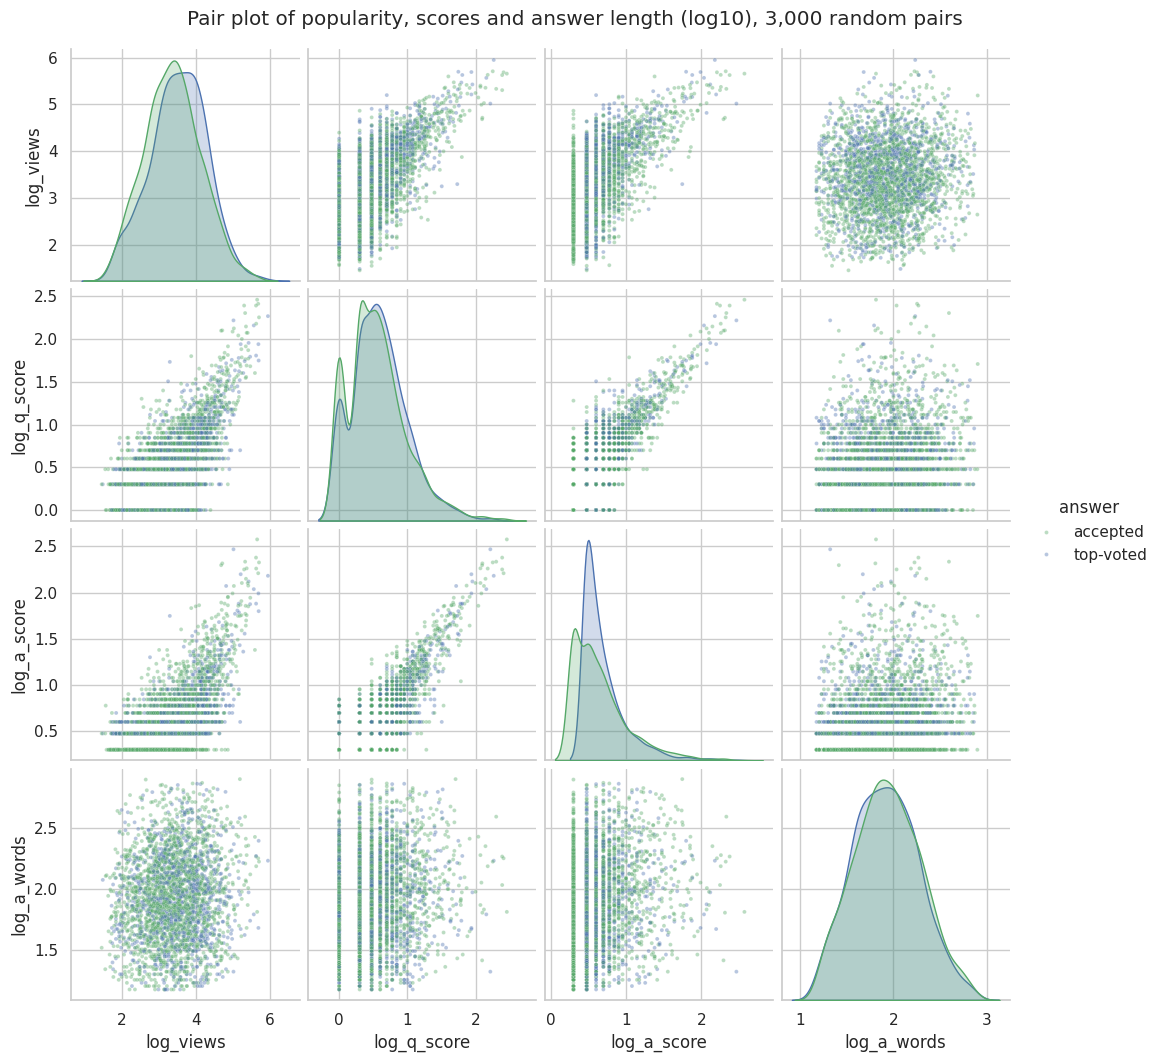

In [34]:
# Pair Plot visualization code
pp = qa.sample(3000, random_state=SEED).assign(
    log_views=lambda d: np.log10(d.view_count + 1), log_q_score=lambda d: np.log10(d.q_score + 1),
    log_a_score=lambda d: np.log10(d.a_score + 1), log_a_words=lambda d: np.log10(d.a_words),
    answer=lambda d: d.ref_type.str.replace("_", "-"))
g = sns.pairplot(pp[["log_views", "log_q_score", "log_a_score", "log_a_words", "answer"]], hue="answer",
                 plot_kws=dict(s=8, alpha=0.4), diag_kws=dict(common_norm=False), palette=["#55a868", "#4c72b0"], height=2.6)
g.fig.suptitle("Pair plot of popularity, scores and answer length (log10), 3,000 random pairs", y=1.02)
plt.savefig(FIG / "chart15_pairplot.png", dpi=100, bbox_inches="tight")
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows every pair of four key features plus each feature's distribution, coloured by the type of trusted answer. It is a multivariate check of the relations seen in the heatmap.

##### 2. What is/are the insight(s) found from the chart?

- In log scale, views, question score and answer score form clear upward bands: the same structure as in the heatmap.
- Accepted and top-voted answers overlap almost completely. Accepted answers include more low-score answers, because an asker can accept an answer with few votes.
- Answer length forms a round cloud against the scores, which confirms that length says nothing about quality. The bot is not rewarded for long answers, and the refined training answers are kept short.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Three statements based on the charts:
1. **Questions that include code or error output are more likely to get a trusted answer** (charts 2 and 9: helpers need details to solve a problem).
2. **Accepted answers that contain a command get more up-votes than accepted answers without one** (charts 9 and 10: the community values answers that can be run).
3. **Since ChatGPT was released, fewer new questions get a trusted answer and the wait is longer** (charts 1, 2 and 7). If true, it matters for this project: forums are losing their helpers, which makes a bot built on their past answers more valuable.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Null hypothesis (H0):** whether an open question contains code has no relation to whether it gets a trusted answer.

**Alternative hypothesis (H1):** questions with code get a trusted answer at a different (higher) rate than questions without code.

#### 2. Perform an appropriate statistical test.

In [35]:
# Perform Statistical Test to obtain P-Value
# H1: open questions that include code or error output get a trusted answer more often
open_q = posts_q[posts_q.closed_date.isna()][["question_id", "body_html"]].copy()
open_q["has_code"] = open_q.body_html.str.contains("<code>", regex=False)
open_q["trusted"] = open_q.question_id.isin(ref_ids.question_id)
tab = pd.crosstab(open_q.has_code, open_q.trusted)
chi2, p, dof, _ = stats.chi2_contingency(tab)
rate = open_q.groupby("has_code").trusted.mean()
odds = (tab.loc[True, True] * tab.loc[False, False]) / (tab.loc[True, False] * tab.loc[False, True])
v = np.sqrt(chi2 / tab.values.sum())
display(tab.rename(index={True: "question has code", False: "no code"}, columns={True: "trusted answer", False: "no trusted answer"}))
print(f"trusted-answer rate: with code {rate[True]:.1%}, without {rate[False]:.1%}")
print(f"chi-square = {chi2:,.1f}, dof = {dof}, p-value = {p:.3g}, odds ratio = {odds:.2f}, Cramer's V = {v:.3f}")
del open_q

trusted,no trusted answer,trusted answer
has_code,,
no code,112519,71154
question has code,103097,78805


trusted-answer rate: with code 43.3%, without 38.7%
chi-square = 793.3, dof = 1, p-value = 1.52e-174, odds ratio = 1.21, Cramer's V = 0.047


##### Which statistical test have you done to obtain P-Value?

The chi-square test of independence on the 2 x 2 table (question has code, question got a trusted answer), with the odds ratio and Cramer's V as effect sizes.

##### Why did you choose the specific statistical test?

Both variables are yes/no and the counts are very large, which is exactly the setting of the chi-square test. With 360,000 questions almost any difference is significant, so the odds ratio and Cramer's V show how big it really is.

**Result: H0 rejected.** Open questions with code get a trusted answer more often: **43.3% against 38.7%** (chi-square 793.3, p = 1.5e-174). The odds ratio is 1.21 and Cramer's V only 0.047, so the effect is real but small. Showing the error message or the command helps, but it is not what decides whether a question gets answered.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Null hypothesis (H0):** accepted answers with a code block do not score higher than accepted answers without one.

**Alternative hypothesis (H1):** accepted answers with a code block score higher.

#### 2. Perform an appropriate statistical test.

In [36]:
# Perform Statistical Test to obtain P-Value
# H2: accepted answers that contain a command (code block) get more up-votes than accepted answers without one
acc = qa[qa.ref_type == "accepted"]
with_code, no_code = acc.loc[acc.a_code_blocks > 0, "a_score"], acc.loc[acc.a_code_blocks == 0, "a_score"]
u, p = stats.mannwhitneyu(with_code, no_code, alternative="greater")
auc = u / (len(with_code) * len(no_code))
print(f"accepted answers with a code block: {len(with_code):,}, median score {with_code.median():.0f}, mean {with_code.mean():.1f}")
print(f"accepted answers without:           {len(no_code):,}, median score {no_code.median():.0f}, mean {no_code.mean():.1f}")
print(f"Mann-Whitney U = {u:,.0f}, one-sided p-value = {p:.3g}, P(random answer with code scores higher) = {auc:.3f}")

accepted answers with a code block: 47,493, median score 3, mean 11.9
accepted answers without:           44,210, median score 2, mean 6.2
Mann-Whitney U = 1,227,251,357, one-sided p-value = 0, P(random answer with code scores higher) = 0.584


##### Which statistical test have you done to obtain P-Value?

The one-sided Mann-Whitney U test, with the probability that a random answer with code scores higher than a random answer without code as the effect size.

##### Why did you choose the specific statistical test?

Scores are counts with a very long tail (median 3, maximum over 3,000), so a t-test on means would be dominated by a few famous answers. A rank test compares the whole distributions and the question is one-directional.

**Result: H0 rejected.** Accepted answers with a code block score higher than those without: median **3 against 2**, mean 11.9 against 6.2 (one-sided Mann-Whitney U, p below the smallest number the computer can show). A random answer with code beats a random answer without code 58.4% of the time. This supports keeping commands exactly as written in the training data, and measuring command recall.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Null hypothesis (H0):** the share of new questions that get a trusted answer within 90 days, and the time to that answer, are the same before (Dec 2020 to Nov 2022) and after (Dec 2022 to Dec 2023) the release of ChatGPT.

**Alternative hypothesis (H1):** after the release, a smaller share of questions get a trusted answer within 90 days and they wait longer.

#### 2. Perform an appropriate statistical test.

In [37]:
# Perform Statistical Test to obtain P-Value
# H3: after ChatGPT was released, fewer new questions get a trusted answer, and the answer takes longer.
# Fair comparison: both periods end at least 3 months before the dump, and only answers within 90 days count.
st3 = st[(st.created >= "2020-12-01") & (st.created < "2024-01-01") & (st.status != "closed")].copy()
st3["after"] = st3.created >= "2022-12-01"
st3["trusted_90d"] = st3.ref_type.notna() & (st3.wait_h.between(0, 24 * 90))
tab3 = pd.crosstab(st3.after, st3.trusted_90d)
chi2, p, _, _ = stats.chi2_contingency(tab3)
r = st3.groupby("after").trusted_90d.mean()
print(f"share with a trusted answer within 90 days: Dec 2020 - Nov 2022 {r[False]:.1%} ({(~st3.after).sum():,} questions), "
      f"Dec 2022 - Dec 2023 {r[True]:.1%} ({st3.after.sum():,} questions)")
print(f"chi-square = {chi2:.1f}, p-value = {p:.3g}")
w_before = st3[~st3.after & st3.trusted_90d].wait_h
w_after = st3[st3.after & st3.trusted_90d].wait_h
u, p2 = stats.mannwhitneyu(w_after, w_before, alternative="greater")
print(f"median wait for that answer: before {w_before.median():.1f} h, after {w_after.median():.1f} h")
print(f"Mann-Whitney U = {u:,.0f}, one-sided p-value = {p2:.3g}, P(an 'after' question waits longer) = {u / (len(w_after) * len(w_before)):.3f}")

share with a trusted answer within 90 days: Dec 2020 - Nov 2022 24.7% (41,411 questions), Dec 2022 - Dec 2023 15.0% (17,525 questions)
chi-square = 677.7, p-value = 2.06e-149
median wait for that answer: before 2.1 h, after 2.9 h
Mann-Whitney U = 13,935,733, one-sided p-value = 0.00181, P(an 'after' question waits longer) = 0.518


##### Which statistical test have you done to obtain P-Value?

The chi-square test on the share answered within 90 days, and the one-sided Mann-Whitney U test on the waiting time.

##### Why did you choose the specific statistical test?

A fair comparison needs the same chance for both periods: the dump ends in April 2024, so a question from March 2024 had little time to be answered. Counting only answers within 90 days and ending the second period in December 2023 removes that bias. The share is a yes/no outcome (chi-square) and the waiting time is very skewed (rank test). The test shows a change in time, not that ChatGPT caused it.

**Result: H0 rejected for both measures.** The share of new questions with a trusted answer within 90 days fell from **24.7% (Dec 2020 to Nov 2022) to 15.0% (Dec 2022 to Dec 2023)** (chi-square 677.7, p = 2e-149). The median wait for that answer grew from **2.1 to 2.9 hours** (one-sided Mann-Whitney U, p = 0.0018), although that effect is small (an "after" question waits longer 51.8% of the time). The test shows a change over time; it cannot prove that ChatGPT caused it, since the decline had started earlier.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [38]:
# Handling Missing Values & Missing Value Imputation
mv = pd.Series({
    "no accepted answer -> the best-voted answer (2+ votes) is used instead": int((qa.ref_type == "top_voted").sum()),
    "no trusted answer at all -> question dropped, nothing is made up": int(funnel["not voted down (score >= 0)"] - funnel["has a trusted answer (accepted, or 2+ up-votes)"]),
    "empty closed date = the question is still open (kept, it is not missing data)": int(posts_q.closed_date.isna().sum()),
    "question without tags -> empty tag list (tag features = 0)": int((qa.tags.str.len() == 0).sum()),
    "answer older than its question (merged posts) -> waiting time left empty": int(qa.hours_to_answer.isna().sum()),
    "guide passage before the first sub-heading -> page title used as section": int((docs.section == docs.title).sum()),
}, name="rows").to_frame()
display(mv)
assert qa[["title", "question", "answer"]].map(lambda s: len(s.strip()) == 0).sum().sum() == 0
print("no empty title, question or answer left in the clean pairs")

,rows
no accepted answer -> the best-voted answer (2+ votes) is used instead,45346
"no trusted answer at all -> question dropped, nothing is made up",210697
"empty closed date = the question is still open (kept, it is not missing data)",365575
question without tags -> empty tag list (tag features = 0),0
answer older than its question (merged posts) -> waiting time left empty,19
guide passage before the first sub-heading -> page title used as section,344


no empty title, question or answer left in the clean pairs


#### What all missing value imputation techniques have you used and why did you use those techniques?

No values were invented. Each kind of missing value was handled by what it means:
- **No accepted answer (67% of questions):** the best answer with 2+ up-votes is used instead (45,346 pairs). If there is none, the question is dropped (210,697): a made-up answer would be worse than no example.
- **Empty closed date (88%):** the question is open. This is information, not missing data, so it was kept as is.
- **Answer older than its question (19 merged posts):** the waiting time is left empty rather than negative.
- **Missing owner (1.8%, deleted accounts):** only needed to detect self-answers, then the column is dropped.
- **Guide passages before the first sub-heading (344):** the page title is used as the section name.

After this step no clean pair has an empty title, question or answer.

### 2. Handling Outliers

,Q1,Q3,upper fence (Q3 + 1.5 IQR),rows above
q_words,51.0,145.0,286.0,9568.0
a_words,47.0,149.0,302.0,9139.0
a_score,2.0,6.0,12.0,15111.0
view_count,795.0,8839.0,20905.0,17586.0
hours_to_answer,0.4,63.7,158.6,28228.0


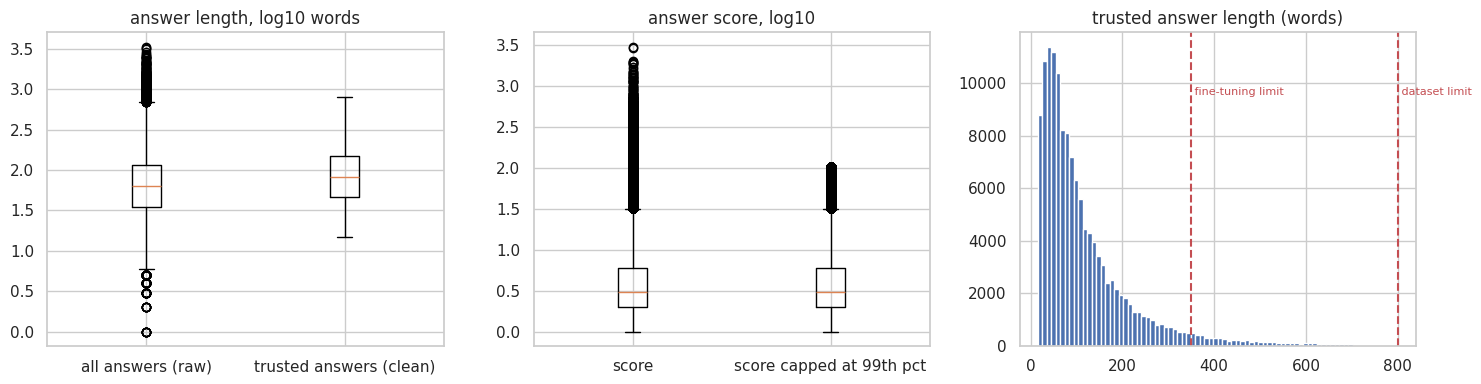

raw answers longer than 800 words: 0.4% of a 100k sample


In [39]:
# Handling Outliers & Outlier treatments
raw_words = posts_a.body_html.sample(100000, random_state=SEED).str.replace(r"<[^>]+>", " ", regex=True).str.split().str.len()
# this is the last use of the raw HTML: drop it to keep Colab's 12.7 GB of RAM free for the models
posts_q, posts_a = posts_q.drop(columns="body_html"), posts_a.drop(columns="body_html")
free_gpu()
iqr = {}
for col in ["q_words", "a_words", "a_score", "view_count", "hours_to_answer"]:
    s = qa[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr[col] = {"Q1": q1, "Q3": q3, "upper fence (Q3 + 1.5 IQR)": q3 + 1.5 * (q3 - q1), "rows above": int((s > q3 + 1.5 * (q3 - q1)).sum())}
display(pd.DataFrame(iqr).T.round(1))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].boxplot([np.log10(raw_words.clip(lower=1)), np.log10(qa.a_words)], tick_labels=["all answers (raw)", "trusted answers (clean)"])
ax[0].set_title("answer length, log10 words")
ax[1].boxplot([np.log10(qa.a_score), np.log10(qa.a_score.clip(upper=qa.a_score.quantile(0.99)))], tick_labels=["score", "score capped at 99th pct"])
ax[1].set_title("answer score, log10")
ax[2].hist(qa.a_words, bins=80, color="#4c72b0")
for x, lab in [(350, "fine-tuning limit"), (800, "dataset limit")]:
    ax[2].axvline(x, color="#c44e52", ls="--")
    ax[2].text(x, ax[2].get_ylim()[1] * 0.8, " " + lab, color="#c44e52", fontsize=8)
ax[2].set_title("trusted answer length (words)")
save("fe_outliers")
print(f"raw answers longer than 800 words: {(raw_words > 800).mean():.1%} of a 100k sample")

##### What all outlier treatment techniques have you used and why did you use those techniques?

The IQR rule flags many rows (15,111 above the upper fence for the answer score, 17,586 for views, 28,228 for the waiting time), but these are not errors: they are famous questions and slow answers, which are real. So I did not remove or clip them. For analysis, the counts were log-transformed so they do not dominate charts and correlations.

Limits were only set where a model needs them: questions of 3 to 600 words, answers of 15 to 800 words (raw answers above 800 words are only 0.4%), and at most 1,024 tokens per training example. These limits remove 4,613 pairs and keep the examples a small model can learn completely.

### 3. Categorical Encoding

In [40]:
# Encode your categorical columns
from sklearn.preprocessing import MultiLabelBinarizer
top_tags = [t for t, _ in tag_counts.most_common(30)]
mlb = MultiLabelBinarizer(classes=top_tags)
tag_matrix = pd.DataFrame(mlb.fit_transform(qa.tags.map(lambda ts: [t for t in ts if t in top_tags])),
                          columns=[f"tag_{t}" for t in top_tags], index=qa.index)
qa["is_accepted"] = (qa.ref_type == "accepted").astype(int)
qa["latest_version"] = qa.versions.map(lambda v: max(float(x) for x in v) if v else np.nan)
qa["is_lts_version"] = qa.versions.map(lambda v: int(any(x.endswith(".04") and int(x[:2]) % 2 == 0 for x in v)))
print("multi-hot tag matrix:", tag_matrix.shape, f"| {tag_matrix.values.sum() / len(qa):.2f} top-30 tags per question on average")
display(pd.concat([qa[["title", "ref_type", "is_accepted", "versions", "latest_version", "is_lts_version"]], tag_matrix.iloc[:, :6]], axis=1).head(5))

multi-hot tag matrix: (137049, 30) | 0.88 top-30 tags per question on average


,title,ref_type,is_accepted,versions,latest_version,is_lts_version,tag_command-line,tag_bash,tag_apt,tag_14.04,tag_networking,tag_12.04
0,"How to get the ""Your battery is broken"" message to go away?",accepted,1,[],NaN,0,0,0,0,0,0,0
1,How can I set the Software Center to install software for non-root users?,accepted,1,[],NaN,0,0,0,0,0,0,0
2,What are some alternatives to upgrading without using the standard upgrade system?,top_voted,0,[],NaN,0,0,0,0,0,0,0
3,How to graphically interface with a headless server?,accepted,1,[],NaN,0,0,0,0,0,0,0
4,How do I run a successful Ubuntu Hour?,accepted,1,[],NaN,0,0,0,0,0,0,0


#### What all categorical encoding techniques have you used & why did you use those techniques?

- **Tags (a list per question):** multi-hot encoding of the 30 most common tags, one column per tag (0.88 of these tags per question on average). One-hot encoding does not fit because a question can have up to five tags.
- **Type of trusted answer:** a binary `is_accepted` column.
- **Ubuntu versions in the tags:** extracted into a numeric `latest_version` and a binary `is_lts_version`.
- **Title type:** a binary flag for "how to" titles.

The text itself is not encoded by hand: the language model uses its own tokenizer, and the search uses TF-IDF, BM25 and sentence embeddings (section 6.4).

### 4. Textual Data Preprocessing 
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

**An important choice for this project:** the classic pre-processing steps below are used for the **keyword search** (TF-IDF and BM25), where they help match words. The **language model gets the clean text without them**. Lower-casing, removing punctuation or stop words would break the very thing an IT answer is made of: `sudo apt-get install -y nvidia-driver-535` loses its meaning without the dashes, the digits and the exact spelling. The steps are shown on a sample of 2,000 questions, and the grid search in ML Model 1 measures which of them actually help the search.

#### 1. Expand Contraction

In [41]:
# Expand Contraction
import contractions
itbot._nltk_ready()
txt = (qa.title + ". " + qa.question.map(lambda t: " ".join(t.split()[:60]))).sample(2000, random_state=SEED).tolist()
step = {"original": txt}
step["expanded"] = [contractions.fix(t) for t in step["original"]]
changed = sum(a != b for a, b in zip(step["original"], step["expanded"]))
ex = next(i for i, (a, b) in enumerate(zip(step["original"], step["expanded"])) if a != b and "'t" in a)
print(f"{changed} of {len(txt)} texts changed, e.g.\n  before: {step['original'][ex][:160]}\n  after:  {step['expanded'][ex][:160]}")

1035 of 2000 texts changed, e.g.
  before: Ubuntu 12.04 won't boot on Toshiba Satellite L855. I recently attempted to install Ubuntu 12.04 onto Satellite and problems during the boot splash, right after 
  after:  Ubuntu 12.04 will not boot on Toshiba Satellite L855. I recently attempted to install Ubuntu 12.04 onto Satellite and problems during the boot splash, right aft


#### 2. Lower Casing

In [42]:
# Lower Casing
step["lower"] = [t.lower() for t in step["expanded"]]
vocab = lambda texts: len(set(w for t in texts for w in t.split()))
print(f"distinct words: {vocab(step['expanded']):,} -> {vocab(step['lower']):,} after lower casing")

distinct words: 20,087 -> 18,187 after lower casing


#### 3. Removing Punctuations

In [43]:
# Remove Punctuation
# punctuation becomes a space, but a dot between digits stays (22.04, 5.15.0)
step["no_punct"] = [re.sub(r"[^\w.]+|(?<!\d)\.|\.(?!\d)", " ", t) for t in step["lower"]]
print("before:", step["lower"][5][:150]); print("after: ", step["no_punct"][5][:150])
print(f"distinct words: {vocab(step['no_punct']):,}")

before: minimize all shortcut ubuntu 16.04. i do not usually ask questions but i cannot find a working solution anywhere. i went to *settings > keyboard > sho
after:  minimize all shortcut ubuntu 16.04  i do not usually ask questions but i cannot find a working solution anywhere  i went to settings keyboard shortcut
distinct words: 9,416


#### 4. Removing URLs & Removing words and digits contain digits.

In [44]:
# Remove URLs & Remove words and digits contain digits
step["no_urls"] = [itbot.URL_RE.sub(" ", re.sub(r"\[link: [^\]]+\]", " ", t)) for t in step["lower"]]
step["no_urls"] = [re.sub(r"[^\w.]+|(?<!\d)\.|\.(?!\d)", " ", t) for t in step["no_urls"]]
step["no_digits"] = [" ".join(w for w in t.split() if not any(c.isdigit() for c in w)) for t in step["no_urls"]]
lost = Counter(w for t in step["no_urls"] for w in t.split() if any(c.isdigit() for c in w))
print(f"texts with a URL: {sum('http' in t or '[link:' in t for t in step['lower'])}")
print("most common words removed by the digit rule:", [w for w, _ in lost.most_common(15)])

texts with a URL: 107
most common words removed by the digit rule: ['1', '12.04', '2', '14.04', '16.04', '0', '3', '20.04', '18.04', '7', '10', '5', '11.10', '8', '4']


#### 5. Removing Stopwords & Removing White spaces

In [45]:
# Remove Stopwords
stop = itbot._STOP
print(f"{len(stop)} English stop words; kept on purpose because they change the meaning: {sorted(itbot.KEEP_WORDS)}")
step["no_stop"] = [" ".join(w for w in t.split() if w not in stop) for t in step["no_urls"]]
n_before = sum(len(t.split()) for t in step["no_urls"]); n_after = sum(len(t.split()) for t in step["no_stop"])
print(f"words: {n_before:,} -> {n_after:,} ({1 - n_after / n_before:.0%} removed)")

183 English stop words; kept on purpose because they change the meaning: ['can', 'cannot', 'doesn', 'down', 'how', 'isn', 'no', 'not', 'off', 'on', 'out', 'up', 'what', 'where', 'why', 'won']
words: 129,697 -> 80,431 (38% removed)


In [46]:
# Remove White spaces
step["clean"] = [re.sub(r"\s+", " ", t).strip() for t in step["no_stop"]]
print(repr(step["no_stop"][7][:120])); print(repr(step["clean"][7][:120]))

'ubuntu server on laptop power off display close lid running ubuntu server 11.10 on laptop would like find way lcd displa'
'ubuntu server on laptop power off display close lid running ubuntu server 11.10 on laptop would like find way lcd displa'


#### 6. Rephrase Text

In [47]:
# Rephrase Text
# Real rephrasings written by people: a question closed as a duplicate asks the same thing in other words.
show = para.sample(6, random_state=SEED).merge(qa[["question_id", "title"]], on="question_id")
display(show[["dup_title", "title"]].rename(columns={"dup_title": "duplicate (asked later)", "title": "original question"}))
print(f"{len(para):,} rephrasings of {para.question_id.nunique():,} original questions. They are used twice:")
print("  1. to test the search: does a rephrased question find its original thread? (ML Model 1)")
print("  2. as extra fine-tuning examples: rephrased question -> the original's trusted answer (ML Model 3)")

,duplicate (asked later),original question
0,How can I install Ubuntu Desktop on Ubuntu app on Windows 10?,What's the easiest way to run GUI apps on Windows Subsystem for Linux?
1,python installation error. python:i386 unmet dependency,The following packages have unmet dependencies!
2,Ubuntu 14.04 Vulnerable to Shellshock?,What is the CVE-2014-6271 bash vulnerability (Shellshock) and how do I fix it?
3,"No panels, launcher, etc visible on desktop","Unity doesn't load, no Launcher, no Dash appears"
4,PHP5 Ubuntu not updated?,How do I install different (upgrade or downgrade) PHP version in still supported Ubuntu release?
5,Every time I turn on computer green square shows over wallpaper Ubuntu 20.04,Fuzzy graphics after upgrading to Ubuntu 20.04


30,306 rephrasings of 10,361 original questions. They are used twice:
  1. to test the search: does a rephrased question find its original thread? (ML Model 1)
  2. as extra fine-tuning examples: rephrased question -> the original's trusted answer (ML Model 3)


#### 7. Tokenization

In [48]:
# Tokenization
import nltk
for pkg in ("punkt", "punkt_tab", "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"):
    nltk.download(pkg, quiet=True)
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(BASE_MODEL)
line = "sudo apt-get install -y nvidia-driver-535 && sudo reboot  # Ubuntu 22.04"
print("NLTK word tokens:", nltk.word_tokenize(line))
print("Qwen3 tokens:    ", tok.tokenize(line))
sample = qa.sample(3000, random_state=SEED)
q_tok = [len(tok(itbot.format_question(t, b), add_special_tokens=False)["input_ids"]) for t, b in zip(sample.title, sample.question)]
a_tok = [len(tok(a, add_special_tokens=False)["input_ids"]) for a in sample.answer]
print(f"tokens per question (title + up to 200 words): median {np.median(q_tok):.0f}, 95th pct {np.percentile(q_tok, 95):.0f}")
print(f"tokens per trusted answer: median {np.median(a_tok):.0f}, 95th pct {np.percentile(a_tok, 95):.0f}")
print(f"tokens per word: {np.sum(a_tok) / sample.a_words.sum():.2f}")

NLTK word tokens: ['sudo', 'apt-get', 'install', '-y', 'nvidia-driver-535', '&', '&', 'sudo', 'reboot', '#', 'Ubuntu', '22.04']
Qwen3 tokens:     ['sudo', 'Ġapt', '-get', 'Ġinstall', 'Ġ-', 'y', 'Ġn', 'vidia', '-driver', '-', '5', '3', '5', 'Ġ&&', 'Ġsudo', 'Ġreboot', 'Ġ', 'Ġ#', 'ĠUbuntu', 'Ġ', '2', '2', '.', '0', '4']


tokens per question (title + up to 200 words): median 138, 95th pct 499
tokens per trusted answer: median 130, 95th pct 600
tokens per word: 1.63


#### 8. Text Normalization

In [49]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)
from nltk.stem import PorterStemmer
ps = PorterStemmer()
words = ["installing", "installed", "installation", "drivers", "updates", "updated", "partitions", "booting", "mounted", "libraries", "dependencies"]
display(pd.DataFrame({"word": words, "Porter stem": [ps.stem(w) for w in words], "WordNet lemma": [itbot._lemma(w) for w in words]}).set_index("word").T)
step["lemmas"] = [" ".join(itbot._lemma(w) for w in t.split()) for t in step["clean"]]
step["stems"] = [" ".join(ps.stem(w) for w in t.split()) for t in step["clean"]]
print(f"distinct words: {vocab(step['clean']):,} -> {vocab(step['lemmas']):,} with lemmas, {vocab(step['stems']):,} with stems")
print("one text after the whole chain:", step["lemmas"][3][:200])

word,installing,installed,installation,drivers,updates,updated,partitions,booting,mounted,libraries,dependencies
Porter stem,instal,instal,instal,driver,updat,updat,partit,boot,mount,librari,depend
WordNet lemma,install,install,installation,driver,update,update,partition,boot,mount,library,dependency


distinct words: 9,229 -> 7,774 with lemmas, 7,407 with stems
one text after the whole chain: how remove change save svn password use svn eclipse feature allow save svn user password think use something call gnome keyring problem need use another user access svn repository unable change previo


##### Which text normalization technique have you used and why?

I compared **Porter stemming** and **WordNet lemmatization**. Stemming makes non-words ("installing" and "installation" become "instal", "updates" becomes "updat"); lemmatization keeps real words ("install", "update", "partition"). Lemmas were used, with the verb form tried first and a small list of fixes for computing words (for example "windows" stays "windows"). This reduces 9,229 distinct words to 7,774.

The grid search in ML Model 1 then tested whether it helps the keyword search: lemmas (MRR@10 0.1344) were about as good as stop-word removal alone (0.1354), and both lost clearly to semantic search (0.227). The language model gets the original text, because normalization would break commands.

#### 9. Part of speech tagging

In [50]:
# POS Taging
tagged = [nltk.pos_tag(nltk.word_tokenize(t)) for t in qa.title.sample(3000, random_state=SEED)]
verbs = Counter(itbot._lemma(w.lower()) for s in tagged for w, p in s if p.startswith("VB") and w.isalpha())
nouns = Counter(w.lower() for s in tagged for w, p in s if p.startswith("NN") and w.isalpha() and w.lower() != "ubuntu")
print("Example:", tagged[0])
display(pd.DataFrame({"top verbs (what users want to do)": [f"{w} ({c})" for w, c in verbs.most_common(15)],
                      "top nouns (what it is about)": [f"{w} ({c})" for w, c in nouns.most_common(15)]}))

Example: [('Wrong/corrupted', 'VBN'), ('icon', 'NN'), ('in', 'IN'), ('dash', 'NN')]


,top verbs (what users want to do),top nouns (what it is about)
0,be (438),file (134)
1,do (352),error (105)
2,install (282),files (97)
3,use (194),windows (93)
4,run (113),command (80)
5,work (107),system (75)
6,get (88),server (63)
7,find (70),directory (62)
8,have (68),screen (60)
9,change (67),boot (60)


#### 10. Text Vectorization

In [51]:
# Vectorizing Text
# The bot's library for all experiments: solved threads asked before July 2023 (train + validation period)
# plus the official guide passages. Test questions (July 2023 on) and recent API questions are never in it.
lib_threads = qa[qa.split != "test"]
if N["library_quick"]:
    keep = set(para.question_id.sample(min(len(para), 300), random_state=SEED))
    lib_threads = pd.concat([lib_threads[lib_threads.question_id.isin(keep)],
                             lib_threads.sample(N["library_quick"], random_state=SEED)]).drop_duplicates("question_id")
lib = pd.concat([itbot.thread_items(lib_threads), itbot.doc_items(docs)], ignore_index=True)
print(f"library: {len(lib):,} items ({(lib.kind == 'thread').sum():,} threads, {(lib.kind == 'doc').sum():,} guide passages)")

t0 = time.time()
PREP = dict(drop_stop=True, lemmatize=True)
lib_prepped = [itbot.classic_preprocess(t, **PREP) for t in lib.search_text]           # step chain from above
tfidf = itbot.TfidfSearch(PREP, min_df=2, sublinear_tf=True)
tfidf.X = tfidf.vec.fit_transform(lib_prepped)
bm25 = itbot.BM25Search(PREP, min_df=2).fit(prepped=lib_prepped)
print(f"TF-IDF matrix {tfidf.X.shape}, {tfidf.X.nnz / tfidf.X.shape[0]:.0f} non-zero words per item | BM25 matrix {bm25.X.shape} | {time.time() - t0:.0f} s")

t0 = time.time()
dense = itbot.DenseSearch(EMBED_MODEL, device=DEVICE, batch_size=256 if DEVICE == "cuda" else 64)
E_lib = dense.encode(lib.search_text.tolist(), show=False)
dense.fit(emb=E_lib)
print(f"embeddings {E_lib.shape} (bge-small, 384 numbers per item) in {time.time() - t0:.0f} s")

query = "wifi stopped working after kernel update"
for name, s in [("TF-IDF", tfidf), ("BM25", bm25), ("semantic", dense)]:
    i, v = s.search([query], 3)
    print(f"{name:9s}", [lib.title.iloc[j][:60] for j in i[0]])

library: 138,779 items (135,839 threads, 2,940 guide passages)


TF-IDF matrix (138779, 62575), 43 non-zero words per item | BM25 matrix (138779, 62575) | 20 s


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

embeddings (138779, 384) (bge-small, 384 numbers per item) in 96 s
TF-IDF    ['WiFi stops working after reboot in 18.04', "Intel Wifi isn't working after upgrading to kernel 3.5", 'WiFi problem after Ubuntu 12.10 update']
BM25      ['wifi and bluetooth not working when booting to another kerne', 'Intel Wifi 6 AX210 - WiFi not working after Update', 'Wifi stopped working after kernel update (Ubuntu 14.04 on Ma']
semantic  ['Wifi stopped working after kernel update (Ubuntu 14.04 on Ma', "Intel Wifi isn't working after upgrading to kernel 3.5", 'wifi not working after kernel update to 5.13.0-27-generic in']


##### Which text vectorization technique have you used and why?

Four ways to turn text into vectors were built and compared on the same task (finding the original thread of a rephrased question):
- **TF-IDF:** 62,575 terms, about 43 non-zero terms per item; MRR@10 0.157 on the test rephrasings.
- **BM25:** the same vocabulary, with tuned k1 = 2.0 and b = 0.9; 0.138.
- **LSA:** TF-IDF reduced to 256 dimensions with truncated SVD; 0.084.
- **Sentence embeddings (bge-small-en-v1.5):** 384 dimensions, normalised; **0.219, the best**.

The bots use the embeddings, because they match meaning rather than exact words ("Wi-Fi stopped" and "wireless not working"). For the language model the text is split by Qwen3's own byte-pair tokenizer (1.63 tokens per word).

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [52]:
# Manipulate Features to minimize feature correlation and create new features
feat = pd.DataFrame({
    "log_views": np.log10(qa.view_count + 1), "log_q_score": np.log10(qa.q_score + 1), "log_a_score": np.log10(qa.a_score + 1),
    "log_q_words": np.log10(qa.q_words), "log_a_words": np.log10(qa.a_words), "q_has_code": qa.q_has_code.astype(int),
    "a_has_code": qa.a_has_code.astype(int), "is_accepted": qa.is_accepted, "age_years": 2024.25 - qa.created.dt.year - qa.created.dt.month / 12,
    "has_version_tag": (qa.versions.str.len() > 0).astype(int), "title_is_how_to": qa.title.str.lower().str.startswith("how").astype(int),
    "log_hours_to_answer": np.log10(qa.hours_to_answer.fillna(qa.hours_to_answer.median()) + 0.01)})
c = feat.corr(method="spearman")
pairs = [(a, b, c.loc[a, b]) for i, a in enumerate(c) for b in c.columns[i + 1:] if abs(c.loc[a, b]) > 0.6]
print("strongly related pairs (|rho| > 0.6):", [(a, b, round(r, 2)) for a, b, r in pairs])
feat = feat.drop(columns=["log_views"])          # carries the same information as age + question score
print("engineered features kept:", list(feat.columns))

strongly related pairs (|rho| > 0.6): [('log_views', 'log_q_score', np.float64(0.61)), ('log_q_score', 'log_a_score', np.float64(0.71))]
engineered features kept: ['log_q_score', 'log_a_score', 'log_q_words', 'log_a_words', 'q_has_code', 'a_has_code', 'is_accepted', 'age_years', 'has_version_tag', 'title_is_how_to', 'log_hours_to_answer']


#### 2. Feature Selection

In [53]:
# Select your features wisely to avoid overfitting
# For a language model "feature selection" means choosing which examples it learns from.
# Rules for the fine-tuning pool, each with the reason in the comment:
pool = qa[(qa.split == "train")
          & (qa.year >= 2014)                # 2010-2013 answers often use tools Ubuntu no longer has (gconf, Unity 2D)
          & (qa.a_score >= 2)                # at least two people confirmed the answer worked
          & (qa.a_words.between(20, 350))    # long enough to explain, short enough to learn the whole answer
          & (qa.q_words <= 400)
          & ~qa.self_answer                  # the asker's own answer is often "I found the fix ...": the bot would learn to talk like the user
          & ~qa.first_person]                # other answers written as a personal story ("I had the same problem, I did ...")
print(f"self-answers among the trusted answers: {qa.self_answer.mean():.1%}; first-person answers: {qa.first_person.mean():.1%} "
      f"(kept in the library, left out of fine-tuning)")
print(f"fine-tuning pool: {len(pool):,} of {(qa.split == 'train').sum():,} training-period pairs")
# The model learns from the refined version of each trusted answer: same fix and commands, written as a clear reply
# to the user (forum answers are often personal stories or very short notes, which is not how a support desk replies)
rpool = pool.merge(refined[["question_id", "refined"]], on="question_id")
print(f"threads in the pool with a refined answer: {len(rpool):,}")
imp = pd.DataFrame({"all train-period pairs": qa[qa.split == "train"][["a_score", "a_words", "year", "is_accepted"]].median(),
                    "fine-tuning pool": pool[["a_score", "a_words", "year", "is_accepted"]].median()})
display(imp.round(1))
# which features tell us how much the community valued an answer? mutual information with the answer's score
from sklearn.feature_selection import mutual_info_regression
X_mi = feat.drop(columns=["log_a_score"]).sample(20000, random_state=SEED)
mi = pd.Series(mutual_info_regression(X_mi, feat.loc[X_mi.index, "log_a_score"], random_state=SEED),
               index=X_mi.columns).sort_values(ascending=False)
display(mi.round(4).to_frame("mutual information with log10(answer score + 1)"))

self-answers among the trusted answers: 12.6%; first-person answers: 4.8% (kept in the library, left out of fine-tuning)
fine-tuning pool: 50,073 of 134,621 training-period pairs
threads in the pool with a refined answer: 3,329


,all train-period pairs,fine-tuning pool
a_score,3.0,3.0
a_words,83.0,89.0
year,2015.0,2016.0
is_accepted,1.0,1.0


,mutual information with log10(answer score + 1)
log_q_score,0.5263
is_accepted,0.0945
log_q_words,0.0171
a_has_code,0.0170
log_hours_to_answer,0.0159
log_a_words,0.0117
title_is_how_to,0.0073
age_years,0.0065
q_has_code,0.0000
has_version_tag,0.0000


##### What all feature selection methods have you used  and why?

For a language model, the "features" are the examples it learns from, so selection means choosing training data:
1. **Rules with a reason each:** answers from 2014 on (older ones use retired tools), at least two up-votes, 20 to 350 words, questions up to 400 words, no self-answers and no first-person answers. This gives a pool of 50,073 pairs.
2. **A quality filter on the teacher's rewrites:** a rewrite is kept only if it keeps at least 60% of the original answer's commands, has a sensible length and speaks to the user. 3,329 of 4,000 rewrites passed.
3. **For the engineered numeric features:** Spearman correlation to remove near-duplicate features (views was dropped, it carries the same information as age and score), and mutual information with the answer score to see which signals reflect quality.

##### Which all features you found important and why?

The question score is by far the most informative signal of a good answer (mutual information 0.53), followed by acceptance (0.09). Length, code and waiting time carry almost no information about the answer's score (below 0.02). So the trust rule uses votes and acceptance, not length, and the training data is not chosen for long or code-heavy answers.

#### 3. The fine-tuning answers: refining the trusted answers with a teacher model

The selected pairs are real fixes, but they are written as forum posts: often a personal story ("I had the same problem, I did..."), sometimes a single command with no explanation, sometimes with links in place of steps. A support bot should answer the user directly and clearly. So each selected answer was rewritten by a larger model, **Qwen3-4B-Instruct-2507** (the teacher), into the reply a help desk would send, under strict rules: keep every command, package name, path and setting of the trusted answer exactly as written, add nothing else except a one-line check that the fix worked, speak to the user, give numbered steps with code blocks, and stay under 220 words.

**How (script 3, run once on a GPU):**
1. 4,000 threads were drawn from the fine-tuning pool, the same number from every year so recent versions are not drowned out by the busy years.
2. The teacher rewrote each trusted answer (greedy decoding, so the result is repeatable).
3. Every rewrite was checked automatically (`itbot.refine_ok`), and dropped if it lost the fix (it must keep at least 60% of the original's commands), was too short or too long, slipped into the asker's voice, or refused.
4. 3,329 rewrites (83%) passed and are saved as `data/refined_answers.jsonl.gz`.

The bot is evaluated against the original community answers, not the rewrites, so the refinement cannot make the test easier.

In [54]:
%%writefile scripts/refine_answers.py
# Rewrite trusted Ask Ubuntu answers into clear help-desk replies with a teacher model (Qwen3-4B-Instruct-2507).
# The rewrite keeps each answer's fix and commands; itbot.refine_ok() drops rewrites that lost them. The result is the
# fine-tuning data of ML Model 3 (data/refined_answers.jsonl.gz). Needs a GPU with about 24 GB (the dataset in the
# repo was made on an RTX 6000 Ada: 4,000 answers in about an hour).
#
#   python scripts/refine_answers.py --pool raw/pool.parquet --n 4000 --out data/refined_answers.jsonl.gz
#
# --pool: the notebook's fine-tuning pool (columns question_id, title, question, answer, year), e.g. saved with
# pool.to_parquet("raw/pool.parquet") after section 6 of the notebook.
import argparse
import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path(__file__).resolve().parent.parent))
import itbot  # noqa: E402

ap = argparse.ArgumentParser()
ap.add_argument("--pool", required=True)
ap.add_argument("--n", type=int, default=4000)
ap.add_argument("--teacher", default="Qwen/Qwen3-4B-Instruct-2507")
ap.add_argument("--out", default="data/refined_answers.jsonl.gz")
ap.add_argument("--seed", type=int, default=101)
args = ap.parse_args()

pool = pd.read_parquet(args.pool)
# the same number of threads from every year, so the data is not dominated by the busy years
per_year = int(np.ceil(args.n / pool.year.nunique()))
sub = (pool.groupby("year", group_keys=False).apply(lambda g: g.sample(min(len(g), per_year), random_state=args.seed))
       .sample(frac=1, random_state=args.seed).head(args.n))
teacher, tok = itbot.load_llm(args.teacher)
prompts = [itbot.refine_prompt(tok, itbot.format_question(t, b), a) for t, b, a in zip(sub.title, sub.question, sub.answer)]
lengths = np.array([len(p) for p in prompts])
long_ = lengths >= np.quantile(lengths, 0.9)          # the longest prompts in small batches, the rest in big ones
refined = [None] * len(prompts)
for mask, bs in ((long_, 16), (~long_, 48)):
    idx = np.where(mask)[0]
    for i, r in zip(idx, itbot.generate(teacher, tok, [prompts[i] for i in idx], max_new_tokens=450, batch_size=bs, log=print)):
        refined[i] = r
keep = [itbot.refine_ok(r, a) for r, a in zip(refined, sub.answer)]
out = pd.DataFrame({"question_id": sub.question_id.values, "refined": refined})[keep]
out.to_json(args.out, orient="records", lines=True, compression="gzip")
print(f"kept {len(out):,} of {len(sub):,} rewrites -> {args.out}")

Overwriting scripts/refine_answers.py


In [55]:
# The instruction the teacher model followed for every answer, and how the refined answers compare with the originals
print(itbot.REFINE_SYSTEM, "\n")
print(itbot.REFINE_TASK)
cmp_r = rpool.assign(refined_words=rpool.refined.str.split().str.len(),
                     commands_kept=[itbot.command_recall(r, a) if itbot.command_words(a) else np.nan
                                    for r, a in zip(rpool.refined, rpool.answer)])
print(f"\n{len(rpool):,} refined answers kept of 4,000 rewrites ({len(rpool) / 4000:.0%}) | median length: "
      f"{int(cmp_r.a_words.median())} words before, {int(cmp_r.refined_words.median())} after | share of the original's "
      f"commands kept, for answers with commands: median {np.nanmedian(cmp_r.commands_kept):.0%}, "
      f"mean {np.nanmean(cmp_r.commands_kept):.0%}")
print("threads per year:", cmp_r.year.value_counts().sort_index().to_dict())
for i in (0, 11):
    r = cmp_r.iloc[i]
    print("=" * 100, f"\nQUESTION: {r.title}\n\nTRUSTED ANSWER (Ask Ubuntu):\n{itbot.shorten(r.answer, 90)}"
          f"\n\nREFINED REPLY (what the model learns):\n{itbot.shorten(r.refined, 120)}")

You are a senior Ubuntu support engineer. You write the replies an IT help desk sends to its users. 

A user asked this question:

<question>
{question}
</question>

This answer from an experienced Ask Ubuntu member solved the problem:

<trusted_answer>
{answer}
</trusted_answer>

Write the reply the help desk should send to the user. Rules:
1. Use the trusted answer's solution. Keep every command, package name, file path and setting it relies on, exactly as written there.
2. Do not add other commands, packages or claims. A one-line check that the fix worked is fine.
3. Start with one or two sentences that say what to do (and why, if the trusted answer explains it). Then give numbered steps, with commands in ``` code blocks.
4. Speak to the user as "you". Never write as the person who asked. No greeting, no thanks, no sign-off, no links.
5. Keep it under 220 words.

3,329 refined answers kept of 4,000 rewrites (83%) | median length: 81 words before, 122 after | share of the original's 

- **83% of the rewrites passed the checks** (3,329 of 4,000), the same number of threads from every year from 2014 to 2022 (355 to 385 each).
- **The fix is kept:** for answers with commands, the refined reply keeps a median of 100% of the original's commands (mean 92%).
- **The form changes:** the median length goes from 81 to 122 words, because a bare command becomes a short explanation plus numbered steps. In the Firefox example, a one-line forum tip becomes four clear steps; in the `ls` example, the same two commands are kept and explained, and the "Source:" link at the end is dropped.
- These refined replies are what ML Model 3 learns to write. All test scores are still measured against the original community answers.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [56]:
# Transform Your data
# 1. skewed counts -> log10 (used in charts and statistics above)
print("skew before / after log10:", {c: (round(stats.skew(qa[c]), 1), round(stats.skew(np.log10(qa[c] + 1)), 1)) for c in ["view_count", "a_score", "a_words"]})
# 2. text -> the chat format the model is trained on, then tokens
r = rpool.iloc[0]
ex = itbot.encode_example(tok, itbot.build_messages(itbot.format_question(r.title, r.question)), r.refined)
print("\n--- one training example in the model's chat format (refined answer, shortened) ---")
print(tok.decode(ex["prompt"]) + itbot.shorten(r.refined, 40) + tok.decode(ex["completion"][-1:]))

skew before / after log10: {'view_count': (np.float64(27.4), np.float64(0.2)), 'a_score': (np.float64(27.4), np.float64(1.8)), 'a_words': (np.float64(2.4), np.float64(0.2))}

--- one training example in the model's chat format (refined answer, shortened) ---
<|im_start|>system
You are an IT support assistant for Ubuntu and Linux. Help the user like an experienced Ask Ubuntu member: get to the point, give the exact commands in code blocks and briefly explain what they do. If the question is not about Ubuntu, Linux or computers, say that you can only help with Ubuntu and Linux questions.<|im_end|>
<|im_start|>user
firefox can not display some icons of some english sites

My firefox now is updated to 26.0.

I find my firefox can not display some icons of some english sites.

Below is my screenshot of wordpress management interface.
On the left of the picture, you can find those strange characters.

What is the matter? Thanks<|im_end|>
<|im_start|>assistant
<think>

</think>

To fix the mi

Yes. The counts are extremely skewed: the skewness of `view_count` drops from 27.4 to 0.2 after a log10 transform, `a_score` from 27.4 to 1.8 and the answer length from 2.4 to 0.2. The log scale is used for the charts, the correlations and the mutual information, where a few famous questions would otherwise dominate.

The text is transformed too: HTML into markdown, and each example into the model's chat format (system prompt, question, optional library items, answer). For the pre-trained base model every answer ends with `<|endoftext|>`, the end token it knows from pre-training (see ML Model 3); the example above shows the chat format of an instruction-tuned model.

### 6. Data Scaling

In [57]:
# Scaling your data
print("embedding lengths (should all be 1):", np.round(np.linalg.norm(E_lib[:5], axis=1), 4))
print("TF-IDF row lengths (L2 normalised):", np.round(np.sqrt(tfidf.X[:5].multiply(tfidf.X[:5]).sum(1)).A.ravel(), 4))
print("BM25 scores are not normalised: they only rank items for one query, so no scaling is needed")

embedding lengths (should all be 1): [1. 1. 1. 1. 1.]
TF-IDF row lengths (L2 normalised): [1. 1. 1. 1. 1.]
BM25 scores are not normalised: they only rank items for one query, so no scaling is needed


##### Which method have you used to scale you data and why?

- **Sentence embeddings:** L2-normalised, so the dot product is the cosine similarity and all items are compared on the same scale.
- **TF-IDF rows:** L2-normalised for the same reason.
- **BM25:** not scaled; its scores only rank the items for one query and are never compared across queries.
- **The language model:** needs no scaling; its inputs are token ids.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Not for the bots. The TF-IDF matrix is large (138,779 items x 62,575 terms) but sparse, and searching it takes milliseconds, so there is no speed problem. I still tested whether a compact representation helps, because it could match related words: it does not (next answer). The sentence embeddings are already compact (384 numbers per item).

In [58]:
# DImensionality Reduction (If needed)
# Test: does LSA (TruncatedSVD of the TF-IDF matrix) find rephrased questions better than plain TF-IDF?
from sklearn.decomposition import TruncatedSVD
pv = para[para.question_id.isin(lib.question_id)]
orig_ids = pv.question_id.drop_duplicates().sample(frac=1, random_state=SEED)
val_orig = set(orig_ids.iloc[: len(orig_ids) // 2])
para_val = pv[pv.question_id.isin(val_orig)].sample(min(1000 if not QUICK else 60, pv.question_id.isin(val_orig).sum()), random_state=SEED)
para_test = pv[~pv.question_id.isin(val_orig)].sample(min(1000 if not QUICK else 60, (~pv.question_id.isin(val_orig)).sum()), random_state=SEED)
pq = lambda d: (d.dup_title + "\n" + d.dup_question.map(lambda t: " ".join(t.split()[:150]))).tolist()
truth = lambda d: ("t" + d.question_id.astype(str)).tolist()

t0 = time.time()
svd = TruncatedSVD(256 if not QUICK else 64, random_state=SEED)
Z = svd.fit_transform(tfidf.X).astype(np.float32)
Z /= np.linalg.norm(Z, axis=1, keepdims=True) + 1e-9
Zq = svd.transform(tfidf.vec.transform([itbot.classic_preprocess(t, **PREP) for t in pq(para_val)])).astype(np.float32)
Zq /= np.linalg.norm(Zq, axis=1, keepdims=True) + 1e-9
i_lsa, _ = itbot.topk(Zq @ Z.T, 10)
i_tf, _ = tfidf.search(pq(para_val), 10)
dimred = pd.DataFrame({"TF-IDF (no reduction)": itbot.retrieval_scores(lib.item_id.values[i_tf], truth(para_val)),
                       f"LSA, {Z.shape[1]} dimensions": itbot.retrieval_scores(lib.item_id.values[i_lsa], truth(para_val))}).T
print(f"explained variance of {Z.shape[1]} components: {svd.explained_variance_ratio_.sum():.1%} | {time.time() - t0:.0f} s")
display(dimred.round(3))

explained variance of 256 components: 27.9% | 19 s


,recall@1,recall@5,recall@10,MRR@10
TF-IDF (no reduction),0.105,0.227,0.287,0.157
"LSA, 256 dimensions",0.054,0.128,0.170,0.086


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

**Truncated SVD on the TF-IDF matrix (latent semantic analysis).** It works directly on sparse matrices, where PCA would need a dense, centred copy of 138,779 x 62,575 numbers. With 256 components it keeps 27.9% of the variance, and the search gets worse: MRR@10 falls from 0.157 to 0.086. The reduced vectors lose the exact terms (package names, error codes) that IT questions depend on, so LSA is kept only as a comparison.

### 8. Data Splitting

,split,period,rows,used for
0,train,solved threads asked before 2023,134621,"fine-tuning pool, library"
1,validation,Jan - Jun 2023,1218,"early stopping, prompt and LoRA tuning, library"
2,test,Jul 2023 - Mar 2024,1210,final scores (300 sampled)
3,future,Apr 2024 - Nov 2026 (API),1081,scores on questions after the dump (200 sampled)
4,off-topic train / test,12 non-IT sites,1050 / 150,teach and test polite refusals
5,rephrasings val / test,duplicate links,1000 / 1000,tune and test the search


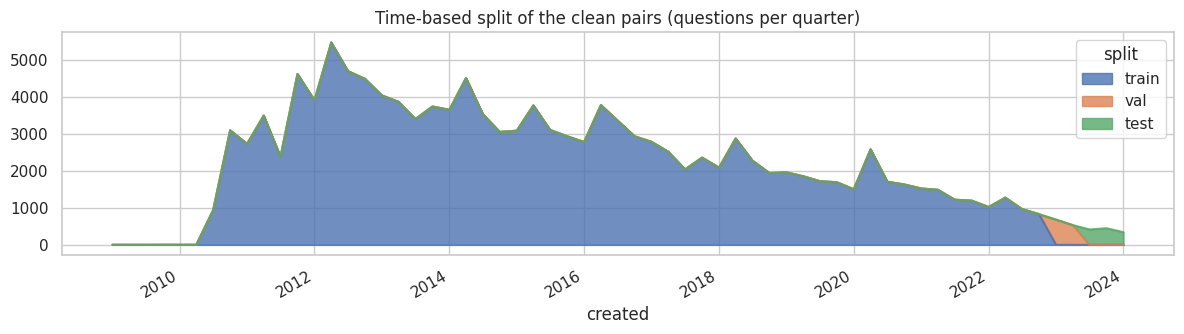

In [59]:
# Split your data to train and test. Choose Splitting ratio wisely.
test_q = qa[qa.split == "test"].sample(min(N["test"], (qa.split == "test").sum()), random_state=SEED).reset_index(drop=True)
val_q = qa[qa.split == "val"].sample(min(N["tune"], (qa.split == "val").sum()), random_state=SEED).reset_index(drop=True)
future_q = recent.sample(min(N["future"], len(recent)), random_state=SEED).reset_index(drop=True)
off_shuffled = off_topic.sample(frac=1, random_state=SEED).reset_index(drop=True)
off_test = off_shuffled.iloc[: N["off_topic_test"]]
off_train = off_shuffled.iloc[N["off_topic_test"]:]
splits = pd.DataFrame([
    ("train", "solved threads asked before 2023", (qa.split == "train").sum(), "fine-tuning pool, library"),
    ("validation", "Jan - Jun 2023", (qa.split == "val").sum(), "early stopping, prompt and LoRA tuning, library"),
    ("test", "Jul 2023 - Mar 2024", (qa.split == "test").sum(), f"final scores ({len(test_q)} sampled)"),
    ("future", "Apr 2024 - Nov 2026 (API)", len(recent), f"scores on questions after the dump ({len(future_q)} sampled)"),
    ("off-topic train / test", "12 non-IT sites", f"{len(off_train)} / {len(off_test)}", "teach and test polite refusals"),
    ("rephrasings val / test", "duplicate links", f"{len(para_val)} / {len(para_test)}", "tune and test the search"),
], columns=["split", "period", "rows", "used for"])
display(splits)
plt.figure(figsize=(12, 3.5))
by_month = qa.groupby([pd.Grouper(key="created", freq="QS"), "split"]).size().unstack(fill_value=0)[["train", "val", "test"]]
by_month.plot(kind="area", ax=plt.gca(), color=["#4c72b0", "#dd8452", "#55a868"], alpha=0.8)
plt.title("Time-based split of the clean pairs (questions per quarter)")
save("fe_split")

##### What data splitting ratio have you used and why? 

**A split by time, not a random split:**

| Set | Period | Size |
|---|---|---|
| train (fine-tuning pool and library) | questions before 2023 | 134,621 pairs |
| validation (early stopping and tuning) | January to June 2023 | 1,218 |
| test (final scores) | July 2023 to March 2024 | 1,210 (300 sampled) |
| future | April 2024 to November 2026, from the API | 1,081 (200 sampled) |
| off-topic train / test | 12 non-IT sites | 1,050 / 150 |
| rephrasings validation / test | duplicate links | 1,000 / 1,000 |

A random split would put near-identical questions (duplicates, the same bug in the same month) on both sides and make the scores look better than they are. A time split copies real use: the bot is trained on the past and asked about the future. The validation and test sets are small (about 1% each) because each test answer has to be generated and scored, which is the expensive part.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Yes, in three ways:
- **Topics:** the top 25 tags cover 29% of uses and the rest is a long tail (chart 3).
- **Years:** 2012 to 2016 have far more trusted answers than recent years (chart 2).
- **On-topic vs off-topic:** the bot must learn to decline non-IT questions, but these are a small part of what it sees: 400 of the 3,462 training examples (12%). (The planning estimate printed above assumed the full 20,000-thread ceiling; with 3,329 refined answers the share is higher.)

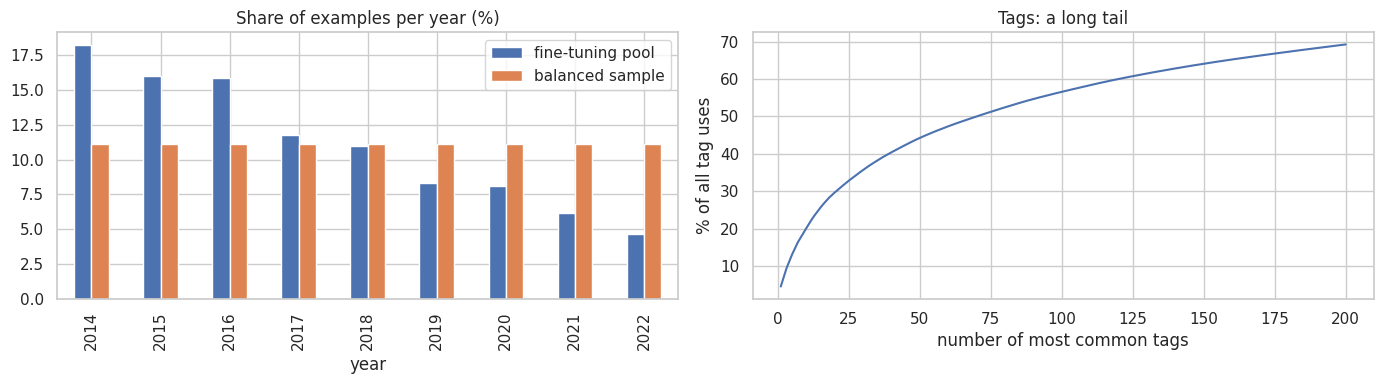

on-topic vs off-topic examples in fine-tuning: about 20000 vs 400 (2%)


In [60]:
# Handling Imbalanced Dataset (If needed)
def balanced_sample(df, n, seed=SEED):
    """Sample n rows spread evenly over the years (a year with fewer rows gives all it has)."""
    per_year = df.groupby("year").size()
    quota, left, years = {}, n, sorted(per_year.index)
    while left > 0 and years:
        share = max(1, left // len(years))
        for y in list(years):
            take = min(share, per_year[y] - quota.get(y, 0), left)
            quota[y] = quota.get(y, 0) + take
            left -= take
            if quota[y] >= per_year[y]:
                years.remove(y)
            if left == 0:
                break
    return pd.concat([df[df.year == y].sample(q, random_state=seed) for y, q in quota.items() if q > 0])

demo = balanced_sample(pool, min(N["train_max"], len(pool)))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
pd.DataFrame({"fine-tuning pool": pool.year.value_counts(normalize=True).sort_index() * 100,
              "balanced sample": demo.year.value_counts(normalize=True).sort_index() * 100}).plot(kind="bar", ax=ax[0])
ax[0].set_title("Share of examples per year (%)")
top_share = pd.Series(Counter(t for ts in pool.tags for t in ts)).sort_values(ascending=False)
ax[1].plot(np.arange(1, 201), top_share.values[:200].cumsum() / top_share.sum() * 100)
ax[1].set_xlabel("number of most common tags")
ax[1].set_ylabel("% of all tag uses")
ax[1].set_title("Tags: a long tail")
save("fe_imbalance")
print(f"on-topic vs off-topic examples in fine-tuning: about {N['train_max']} vs {N['refusals']} ({N['refusals'] / N['train_max']:.0%})")

##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

- **Years:** the training threads are sampled with the same number per year, so old years do not dominate.
- **Topics:** not re-balanced on purpose. Common topics are what users ask most, and the long tail is covered by the search library rather than by oversampling.
- **Off-topic:** 400 polite refusals were added (no oversampling). This was enough: the fine-tuned bot declines 100% of the off-topic test questions and wrongly refuses 0% of the IT questions.

## ***7. ML Model Implementation***

### ML Model - 1

In [61]:
# ML Model - 1 Implementation
# A search-only support bot (no language model): find the most similar solved question in the library
# and reply with that thread's trusted answer. This is how many help desks use an FAQ today.
qa_answer = qa.set_index("question_id").answer
questions = lambda df: [itbot.format_question(t, b) for t, b in zip(df.title, df.question)]
RESULTS, ANSWERS, TIMES = {}, {}, {}
bert = itbot.BertScorer(BERT_MODEL, BERT_LAYER, device=DEVICE)


def score(name, preds, df, split):
    """Score answers against the trusted answers and keep them for the final comparison."""
    s = itbot.answer_scores(preds, df.answer.tolist(), dense, bert)
    RESULTS[(name, split)], ANSWERS[(name, split)] = s, preds
    return s


def search_bot(searcher, df):
    """Reply with the answer of the first solved thread the search returns."""
    idx, _ = searcher.search(questions(df), 20)
    out = []
    for row in idx:
        j = next((j for j in row if lib.kind.iloc[j] == "thread"), row[0])
        out.append(qa_answer[lib.question_id.iloc[j]] if lib.kind.iloc[j] == "thread" else lib.show_text.iloc[j])
    return out

# Fit the Algorithm: the BM25 index of section 6.4 with its default settings (k1 = 1.2, b = 0.75)
# Predict on the model
t0 = time.time()
ans = search_bot(bm25, test_q)
s_m1 = score("1. search bot, BM25 default", ans, test_q, "test")
ret_bm25 = itbot.retrieval_scores(lib.item_id.values[bm25.search(pq(para_test), 10)[0]], truth(para_test))
TIMES["model 1"] = time.time() - t0
print("finding the original of a rephrased question:", {k: round(v, 3) for k, v in ret_bm25.items()})
print("answer quality on the test questions:", s_m1[["rougeL", "bertscore", "semantic", "command_recall"]].mean().round(3).to_dict())

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


finding the original of a rephrased question: {'recall@1': 0.081, 'recall@5': 0.169, 'recall@10': 0.226, 'MRR@10': 0.119}
answer quality on the test questions: {'rougeL': 0.104, 'bertscore': 0.815, 'semantic': 0.693, 'command_recall': 0.123}


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

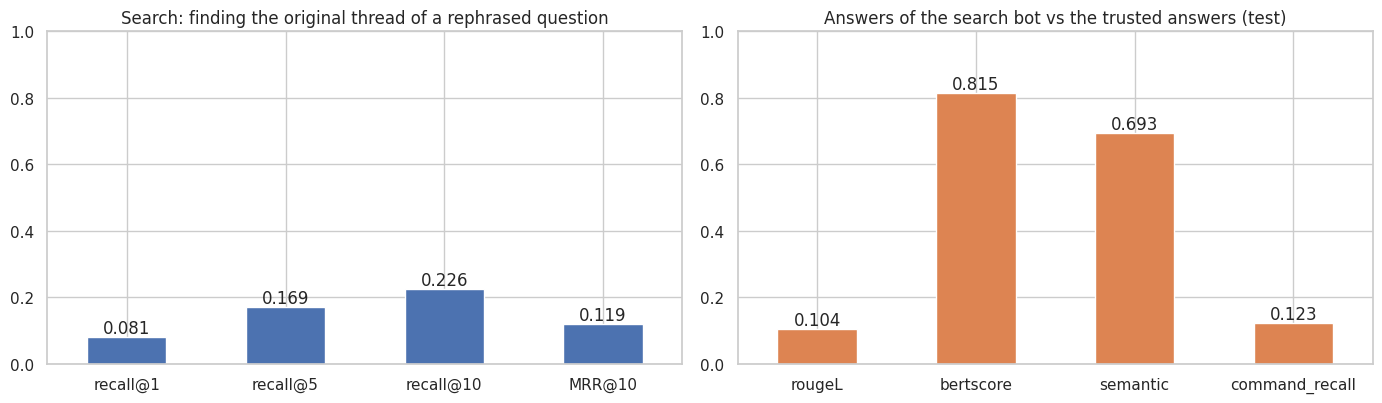

In [62]:
# Visualizing evaluation Metric Score chart
def metric_bars(ax, table, title, cols=("rougeL", "bertscore", "semantic", "command_recall")):
    t = table[list(cols)] if isinstance(table, pd.DataFrame) else table
    t.plot(kind="bar", ax=ax, rot=0, width=0.8)
    ax.set_ylim(0, 1)
    ax.set_title(title)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f", fontsize=7)
    ax.legend(fontsize=8, loc="upper left", ncol=2)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
pd.Series(ret_bm25).plot(kind="bar", ax=ax[0], color="#4c72b0", rot=0)
ax[0].set_ylim(0, 1)
ax[0].set_title("Search: finding the original thread of a rephrased question")
for c in ax[0].containers:
    ax[0].bar_label(c, fmt="%.3f")
s_m1[["rougeL", "bertscore", "semantic", "command_recall"]].mean().plot(kind="bar", ax=ax[1], color="#dd8452", rot=0)
ax[1].set_ylim(0, 1)
ax[1].set_title("Answers of the search bot vs the trusted answers (test)")
for c in ax[1].containers:
    ax[1].bar_label(c, fmt="%.3f")
save("model1_scores")

**ML Model 1 is a search bot, the classic retrieval baseline.** It finds the most similar solved thread in a library of 138,779 items (135,839 solved threads before 2023 and 2,940 guide passages) and returns that thread's trusted answer. The first version uses BM25 with default settings.

- **Finding the original of a rephrased question:** the right thread is first 8.1% of the time and in the top 10 22.6% of the time (MRR@10 0.119).
- **Answers on the test questions:** ROUGE-L 0.104, BERTScore 0.815, semantic similarity 0.693, command recall 0.123.

Its strength is that every answer is real, human-written text, which gives a high BERTScore. Its weakness is that the nearest thread is often a different problem, so the right commands are rarely there (command recall 0.12).

#### 2. Cross- Validation & Hyperparameter Tuning

grid search: 80 settings in 461 s; best: + stop words removed, k1 = 2.0, b = 0.9


,pre-processing,k1,b,recall@1,recall@5,recall@10,MRR@10
0,+ stop words removed,2.0,0.90,0.096,0.186,0.246,0.1354
1,+ lemmas (section 6.4),2.0,0.90,0.095,0.185,0.239,0.1344
2,+ stop words removed,1.6,0.90,0.095,0.183,0.241,0.1331
3,lower case + punctuation,2.0,0.90,0.092,0.187,0.232,0.1320
4,+ stop words removed,2.0,0.75,0.094,0.179,0.231,0.1298
5,+ lemmas (section 6.4),1.6,0.90,0.091,0.182,0.228,0.1295
6,+ lemmas (section 6.4),1.2,0.90,0.095,0.176,0.218,0.1294
7,lower case + punctuation,1.6,0.90,0.093,0.179,0.226,0.1286


,best MRR@10
pre-processing,
+ stop words removed,0.1354
+ lemmas (section 6.4),0.1344
lower case + punctuation,0.1320
+ words with digits removed,0.1234


,recall@1,recall@5,recall@10,MRR@10
semantic (bge-small),0.165,0.306,0.387,0.2273
"hybrid, semantic weight 4.0",0.147,0.310,0.400,0.2177
"hybrid, semantic weight 3.0",0.145,0.303,0.401,0.2154
"hybrid, semantic weight 2.0",0.144,0.295,0.386,0.2100
"hybrid, semantic weight 1.0",0.143,0.276,0.362,0.2019
"hybrid, semantic weight 0.5",0.132,0.261,0.307,0.1870
BM25 tuned,0.096,0.186,0.246,0.1354


search used by the bots from here on: semantic (bge-small)


,recall@1,recall@5,recall@10,MRR@10
TF-IDF,0.112,0.220,0.286,0.157
LSA (TF-IDF + SVD),0.054,0.122,0.173,0.084
BM25 default,0.081,0.169,0.226,0.119
BM25 tuned,0.099,0.190,0.246,0.138
semantic (bge-small),0.146,0.312,0.384,0.219


,rougeL,bertscore,semantic,command_recall,words
BM25 default,0.104,0.815,0.693,0.123,124.577
tuned: semantic (bge-small),0.115,0.818,0.730,0.182,125.877


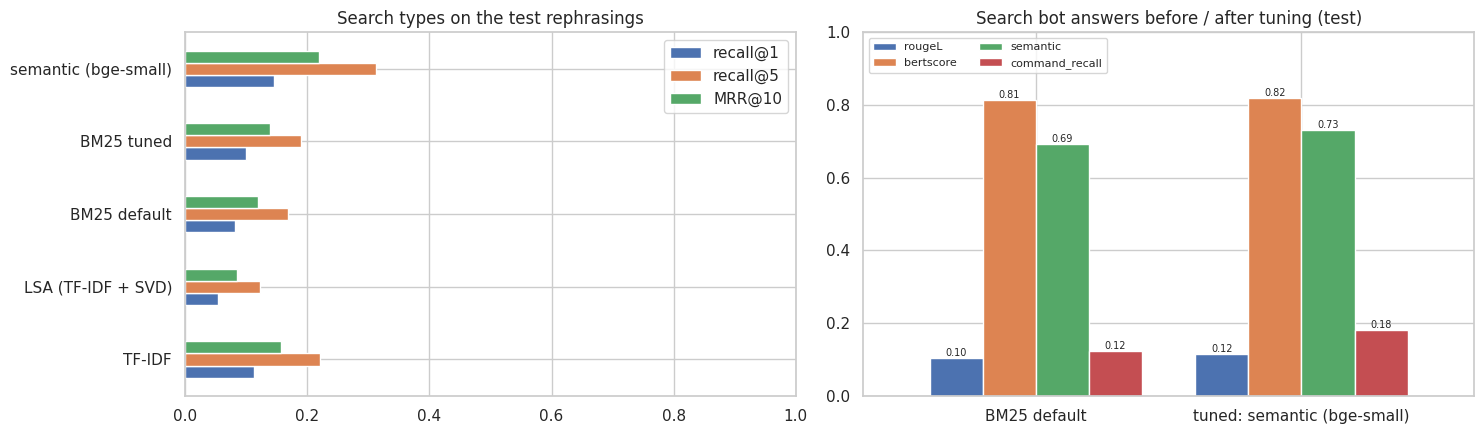

In [63]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# Grid search on the validation rephrasings (MRR@10): text pre-processing x BM25 k1 x BM25 b,
# then the semantic and hybrid search, then the final comparison on the test rephrasings.
t0 = time.time()
lower_only = [itbot.classic_preprocess(t, drop_stop=False, lemmatize=False) for t in lib.search_text]
digitless = lambda texts: [" ".join(w for w in t.split() if not any(c.isdigit() for c in w)) for t in texts]
no_stop = lambda texts: [" ".join(w for w in t.split() if w not in itbot._STOP) for t in texts]
variants = {"lower case + punctuation": (dict(drop_stop=False, lemmatize=False), lower_only, lambda q: q),
            "+ stop words removed": (dict(drop_stop=True, lemmatize=False), no_stop(lower_only), lambda q: q),
            "+ lemmas (section 6.4)": (PREP, lib_prepped, lambda q: q),
            "+ words with digits removed": (dict(PREP, drop_digit_words=True), digitless(lib_prepped), lambda q: q)}
grid = []
for vname, (prep, prepped, _) in variants.items():
    s = itbot.BM25Search(prep, min_df=2).fit(prepped=prepped)
    qv = [itbot.classic_preprocess(t, **prep) for t in pq(para_val)]
    for k1 in (0.6, 0.9, 1.2, 1.6, 2.0):
        for b in (0.3, 0.5, 0.75, 0.9):
            s.set_params(k1, b)
            r = itbot.retrieval_scores(lib.item_id.values[s.search(None, 10, prepped=qv)[0]], truth(para_val))
            grid.append({"pre-processing": vname, "k1": k1, "b": b, **r})
grid = pd.DataFrame(grid).sort_values("MRR@10", ascending=False).reset_index(drop=True)
best = grid.iloc[0]
print(f"grid search: {len(grid)} settings in {time.time() - t0:.0f} s; best: {best['pre-processing']}, k1 = {best.k1}, b = {best.b}")
display(grid.head(8).round(4))
display(grid.groupby("pre-processing")["MRR@10"].max().sort_values(ascending=False).round(4).to_frame("best MRR@10"))

prep_best, prepped_best, _ = variants[best["pre-processing"]]
bm25_best = itbot.BM25Search(prep_best, k1=best.k1, b=best.b, min_df=2).fit(prepped=prepped_best)

# hybrid = BM25 (tuned) + semantic search, fused by reciprocal rank; tune the weight of the semantic side,
# and keep BM25 alone and semantic alone as candidates: the validation rephrasings decide
cands = {"BM25 tuned": bm25_best, "semantic (bge-small)": dense}
for w in (0.5, 1.0, 2.0, 3.0, 4.0):
    cands[f"hybrid, semantic weight {w}"] = itbot.HybridSearch(bm25_best, dense, dense_weight=w)
hyb = pd.DataFrame({k: itbot.retrieval_scores(lib.item_id.values[v.search(pq(para_val), 10)[0]], truth(para_val))
                    for k, v in cands.items()}).T.sort_values("MRR@10", ascending=False)
display(hyb.round(4))
SEARCH_NAME = hyb.index[0]
searcher = cands[SEARCH_NAME]
w_best = searcher.w if isinstance(searcher, itbot.HybridSearch) else None
SEARCH_TYPE = "hybrid" if w_best else ("semantic" if searcher is dense else "bm25")
print("search used by the bots from here on:", SEARCH_NAME)

# all search types on the held-out test rephrasings
Zt = svd.transform(tfidf.vec.transform([itbot.classic_preprocess(t, **PREP) for t in pq(para_test)])).astype(np.float32)
Zt /= np.linalg.norm(Zt, axis=1, keepdims=True) + 1e-9
found = {"TF-IDF": tfidf.search(pq(para_test), 10)[0], "LSA (TF-IDF + SVD)": itbot.topk(Zt @ Z.T, 10)[0],
         "BM25 default": bm25.search(pq(para_test), 10)[0], "BM25 tuned": bm25_best.search(pq(para_test), 10)[0],
         "semantic (bge-small)": dense.search(pq(para_test), 10)[0]}
if SEARCH_TYPE == "hybrid":
    found[f"hybrid (BM25 tuned + semantic x{w_best})"] = searcher.search(pq(para_test), 10)[0]
search_cmp = pd.DataFrame({k: itbot.retrieval_scores(lib.item_id.values[v], truth(para_test)) for k, v in found.items()}).T
display(search_cmp.round(3))

# the search bot again, now with the search chosen on validation
ans = search_bot(searcher, test_q)
s_m1b = score("1. search bot, tuned", ans, test_q, "test")
score("1. search bot, tuned", search_bot(searcher, future_q), future_q, "future")
cmp1 = pd.DataFrame({"BM25 default": s_m1.mean(numeric_only=True), f"tuned: {SEARCH_NAME}": s_m1b.mean(numeric_only=True)}).T
display(cmp1[["rougeL", "bertscore", "semantic", "command_recall", "words"]].round(3))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
search_cmp[["recall@1", "recall@5", "MRR@10"]].plot(kind="barh", ax=ax[0])
ax[0].set_xlim(0, 1)
ax[0].set_title("Search types on the test rephrasings")
metric_bars(ax[1], cmp1, "Search bot answers before / after tuning (test)")
save("model1_tuning")
TIMES["model 1 tuning"] = time.time() - t0

##### Which hyperparameter optimization technique have you used and why?

**Grid search with a held-out validation set.** The search has no trained weights, so classic k-fold cross-validation does not apply. Instead, every setting was scored on the 1,000 validation rephrasings, by how high the original thread ranks (MRR@10), and only the best setting was then measured once on the separate 1,000 test rephrasings. The grid covered 4 pre-processing chains x 5 values of k1 (how quickly repeated words stop counting) x 4 values of b (how much long posts are penalised), 80 settings in total. A grid search fits because there are only three small, discrete settings and each one takes about a second to score. The weight of the semantic side in the hybrid search was tuned the same way.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

**Yes, a large improvement.** The grid search raised BM25 from MRR@10 0.119 to 0.135 (+14%, best with stop words removed, k1 = 2.0, b = 0.9), but semantic search with bge-small embeddings was much better: **0.227 on the validation rephrasings and 0.219 on the test rephrasings**, nearly double default BM25. Hybrid combinations did not beat pure semantic search.

With semantic search, the bot's answers on the test questions improved: semantic similarity 0.693 to 0.730 and command recall 0.123 to 0.182 (+48%).

### ML Model - 2

In [64]:
# ML Model - 2 Implementation
# The pre-trained language model as it is: Qwen3-1.7B-Base (no instruction tuning, no fine-tuning), with the system prompt only.
t0 = time.time()
free_gpu()
llm, tok = itbot.load_llm(BASE_MODEL, DEVICE)
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 1e9 if DEVICE == "cuda" else 0
# answers are written in batches: 16 at a time fit a T4, a 40-80 GB card takes 48 (same answers, written faster)
GEN = dict(max_new_tokens=384 if not QUICK else 96, batch_size=(48 if GPU_GB > 30 else 16) if DEVICE == "cuda" else 4)


def lib_rows(df, k=3, exclude=None, queries=None):
    """Top-k library items for each question (the search chosen in ML Model 1). exclude: question ids that must
    not be shown (a question that is itself in the library must never see its own thread)."""
    idx, _ = searcher.search(queries or questions(df), k + 5)
    out = []
    for r, row in enumerate(idx):
        keep = [j for j in row if exclude is None or lib.question_id.iloc[j] != exclude[r]][:k]
        out.append(lib.iloc[keep])
    return out


def prompts_for(df, with_lib, k=3, queries=None):
    qs = queries or questions(df)
    excl = df.question_id.values if df is not None and "question_id" in df else None
    ctx = lib_rows(df, k, exclude=excl, queries=qs) if with_lib else [None] * len(qs)
    return [itbot.chat_prompt(tok, itbot.build_messages(q, c)) for q, c in zip(qs, ctx)]


ans = itbot.generate(llm, tok, prompts_for(test_q, False), **GEN, log=print)
s_m2 = score("2. pre-trained as is", ans, test_q, "test")
TIMES["model 2"] = time.time() - t0
print(f"{len(ans)} answers in {TIMES['model 2'] / 60:.1f} min")
print(s_m2[["rougeL", "bertscore", "semantic", "command_recall", "words"]].mean().round(3).to_dict())

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

  48/300 answers, 31 s


  288/300 answers, 108 s


300 answers in 2.1 min
{'rougeL': 0.096, 'bertscore': 0.787, 'semantic': 0.7, 'command_recall': 0.177, 'words': 190.013}


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

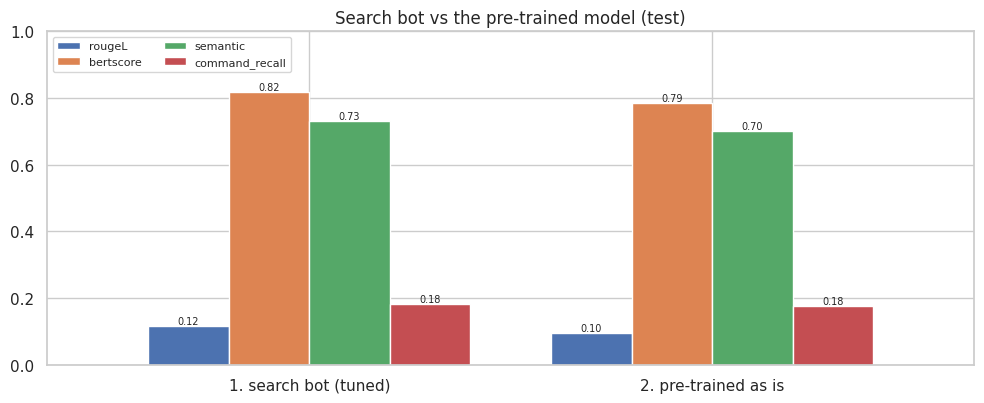

QUESTION: Can I run a kernel newer than 5.15 on Ubuntu 22.04 on a Raspberry Pi 4b?

PRE-TRAINED MODEL AS IS:
 umably based on the 6.2.x branch of the Ubuntu rpi-kernel repo), or from the Ubuntu rpi-kernel repo itself? I.e., if I apply the patches from the 6.2.y branch of the Ubuntu rpi-kernel repo to the 6.2.x branch of the Ubuntu rpi-kernel repo, will that enable the camera module?

umably based on the 6.2.x branch of the Ubuntu rpi-kernel repo), or from the Ubuntu rpi-kernel repo itself? I.e., if I apply the patches from the 6.2.y branch of the Ubuntu rpi-kernel repo to the 6.2.x branch of the Ubuntu rpi-kernel repo, will that enable the camera module?

umably based on the 6.2.x branch of the Ubuntu rpi-kernel repo), or from the Ubuntu rpi-kernel repo itself? I.e., if I apply the patches ...

TRUSTED ANSWER:
 I was able to update my kernel to 6.2.0-1004-raspi by installing the package linux-image-6.2.0-1004-raspi using apt. This updated my kernel with precompiled images.

I was able 

In [65]:
# Visualizing evaluation Metric Score chart
fig, ax = plt.subplots(figsize=(10, 4.2))
metric_bars(ax, pd.DataFrame({"1. search bot (tuned)": s_m1b.mean(numeric_only=True), "2. pre-trained as is": s_m2.mean(numeric_only=True)}).T,
            "Search bot vs the pre-trained model (test)")
save("model2_scores")
i = int(np.argsort(s_m2.semantic.values)[len(s_m2) // 2])
print("QUESTION:", test_q.title[i]); print("\nPRE-TRAINED MODEL AS IS:\n", itbot.shorten(ANSWERS[("2. pre-trained as is", "test")][i], 120))
print("\nTRUSTED ANSWER:\n", itbot.shorten(test_q.answer[i], 120))

**ML Model 2 is the pre-trained Qwen3-1.7B-Base as it comes**, the model before any instruction tuning, asked with the same system prompt. I chose it because it is open (Apache 2.0, no gated access), fits a T4 in fp16 (about 3.4 GB) with room for LoRA training, and, as a base model, shows clearly what fine-tuning adds.

As expected for a base model, it does not behave like an assistant: it often starts in the middle of a word ("umably..."), repeats itself, and keeps writing until the length limit (73% of answers). Its scores on the test questions are below the search bot on three of the four metrics: semantic similarity 0.700, command recall 0.177, BERTScore 0.787, ROUGE-L 0.096. It declines only 1.3% of off-topic questions.

#### 2. Cross- Validation & Hyperparameter Tuning

,rougeL,bertscore,semantic,command_recall,words,combined
setting,,,,,,
greedy,0.088,0.785,0.685,0.195,195.700,0.555
"sampling (T = 0.7, top-p = 0.8)",0.077,0.781,0.651,0.181,169.917,0.538
"greedy + library, top 3",0.101,0.794,0.708,0.227,193.333,0.576
"greedy + library, top 5",0.107,0.796,0.713,0.194,184.517,0.568


best setting on validation: greedy + library, top 3


,rougeL,bertscore,semantic,command_recall,words
as is,0.096,0.787,0.700,0.177,190.013
+ library (top 3),0.093,0.786,0.699,0.197,197.840


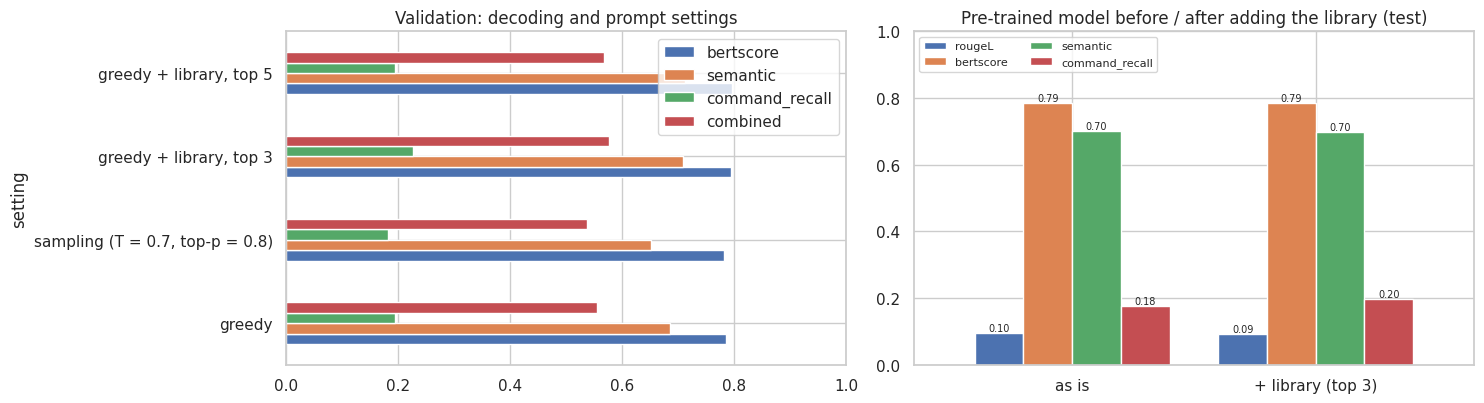

In [66]:
# ML Model - 2 Implementation with hyperparameter optimization techniques
# Settings of a pre-trained model that can be tuned without training: the decoding method and the prompt.
# Grid on the validation questions, scored by the mean of BERTScore, semantic similarity and command recall.
t0 = time.time()
configs = {"greedy": (False, {}), "sampling (T = 0.7, top-p = 0.8)": (False, dict(do_sample=True, temperature=0.7, top_p=0.8, top_k=20)),
           "greedy + library, top 3": (3, {}), "greedy + library, top 5": (5, {})}
tune = []
for name, (k, gen) in configs.items():
    torch.manual_seed(SEED)
    a = itbot.generate(llm, tok, prompts_for(val_q, bool(k), k or 3), **{**GEN, **gen})
    s = itbot.answer_scores(a, val_q.answer.tolist(), dense, bert)
    tune.append({"setting": name, **s[["rougeL", "bertscore", "semantic", "command_recall", "words"]].mean().to_dict()})
tune = pd.DataFrame(tune).set_index("setting")
tune["combined"] = tune[["bertscore", "semantic", "command_recall"]].mean(1)
display(tune.round(3))
best_setting = tune.combined.idxmax()
best_k, best_gen = configs[best_setting]
print("best setting on validation:", best_setting)

# test and future questions: the model as is, and the model with the library (the RAG version)
K_LIB = best_k or 3
ans = itbot.generate(llm, tok, prompts_for(test_q, True, K_LIB), **{**GEN, **best_gen})
s_m2b = score("2. pre-trained + library", ans, test_q, "test")
score("2. pre-trained as is", itbot.generate(llm, tok, prompts_for(future_q, False), **GEN), future_q, "future")
score("2. pre-trained + library", itbot.generate(llm, tok, prompts_for(future_q, True, K_LIB), **{**GEN, **best_gen}), future_q, "future")
# off-topic questions: does the pre-trained model refuse them?
off_q = off_test.title.tolist()
ANSWERS[("2. pre-trained + library", "off-topic")] = itbot.generate(llm, tok, prompts_for(None, True, K_LIB, queries=off_q), **GEN)
ANSWERS[("2. pre-trained as is", "off-topic")] = itbot.generate(llm, tok, prompts_for(None, False, queries=off_q), **GEN)
TIMES["model 2 tuning"] = time.time() - t0
cmp2 = pd.DataFrame({"as is": s_m2.mean(numeric_only=True), f"+ library (top {K_LIB})": s_m2b.mean(numeric_only=True)}).T
display(cmp2[["rougeL", "bertscore", "semantic", "command_recall", "words"]].round(3))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
tune[["bertscore", "semantic", "command_recall", "combined"]].plot(kind="barh", ax=ax[0])
ax[0].set_xlim(0, 1)
ax[0].set_title("Validation: decoding and prompt settings")
metric_bars(ax[1], cmp2, "Pre-trained model before / after adding the library (test)")
save("model2_tuning")

##### Which hyperparameter optimization technique have you used and why?

**Grid search on the validation questions.** A pre-trained model has no weights to tune without training, but its answers depend strongly on how it is asked and how the text is generated. Four settings were compared on the validation questions (January to June 2023): greedy decoding, sampling (temperature 0.7, top-p 0.8, the values Qwen recommends), and greedy decoding with 3 or 5 library items in front of the question (retrieval-augmented generation). The score was the mean of BERTScore, semantic similarity and command recall. Each setting means generating every answer again, so a small grid was the practical choice.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

**Only a small improvement.** On the validation questions, greedy decoding with the top 3 library items scored best (combined score 0.576, against 0.555 for greedy decoding alone and 0.538 for sampling). On the test questions the library raised command recall from 0.177 to 0.197, but semantic similarity stayed the same (0.700 and 0.699). The pre-trained model cannot really use the solved threads in front of it, which is exactly what fine-tuning is meant to change.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

Every metric compares the bot's answer with the answer the Ask Ubuntu community accepted or up-voted for the same question, so each one stands for a part of "would this have solved the user's problem":

| Metric | What it measures | What it means for an IT support desk |
|---|---|---|
| **Command recall** | share of the commands, package names, options and paths of the trusted answer that the bot's answer also contains | the most direct measure of a correct fix: if the bot names `nmcli`, `netplan apply` or the right package, the user can act on it. Higher recall means fewer tickets passed on to a human |
| **BERTScore F1** | token-by-token meaning overlap with the trusted answer, using contextual embeddings | rewards answers that say the same thing in other words; a proxy for "the support agent would agree with it" |
| **Semantic similarity** | cosine similarity of whole-answer embeddings | whether the answer is about the same solution at all; low values flag answers that went in a different direction |
| **ROUGE-L** | longest shared word sequence | strict wording overlap; useful as a sanity check, but it punishes good answers that are phrased differently |
| **Refusal rates** | off-topic questions declined, and on-topic questions wrongly declined | the first protects the company (no advice outside its scope), the second protects the user (no "I can't help" for a real IT problem) |
| **LLM judge win rate** | how often a larger model prefers the answer, in both orders; two judges from different families (Qwen3-4B-Instruct and Phi-4) | closest to a human review of usefulness at a fraction of the cost; two judges agreeing rules out the taste of one model |
| **Perplexity** | how likely the model finds an answer: the community's raw answer, and the refined reply it was trained to write | the refined one shows the model learned what a good reply looks like; the raw one shows how far it moved away from forum style |
| **Seconds per answer** | latency on the hardware it runs on | users leave a chat that takes too long; it decides whether a GPU is needed |

A metric that rises while command recall stays flat is a warning sign: the answer sounds right but does not contain the fix.

### ML Model - 3

In [67]:
# ML Model - 3 Implementation
# The pre-trained Qwen3-1.7B-Base fine-tuned with LoRA on the refined trusted answers. Half of the examples show
# library items in front of the question (the thread itself is never among them), so the model learns to use them
# when they fit and to ignore them when they do not.
t0 = time.time()
del llm
free_gpu()
rng = np.random.default_rng(SEED)


def make_examples(df, answers, ctx_share=0.5, exclude_self=True, queries=None, seed=SEED):
    """Rows -> encoded examples. queries: question texts (defaults to the rows' own title + body)."""
    r = np.random.default_rng(seed)
    qs = queries or questions(df)
    use = r.random(len(qs)) < ctx_share
    ctx = [None] * len(qs)
    if use.any():
        sel = np.where(use)[0]
        excl = df.question_id.values[sel] if exclude_self and df is not None else None
        rows = lib_rows(df.iloc[sel] if df is not None else None, K_LIB, exclude=excl, queries=[qs[i] for i in sel])
        for i, c in zip(sel, rows):
            ctx[i] = c
    ex = [itbot.encode_example(tok, itbot.build_messages(q, c), a, max_len=1024) for q, c, a in zip(qs, ctx, answers)]
    return [e for e in ex if e is not None]


# validation: refined answers of threads held out from training
r_val = rpool.sample(min(N["val_loss"], max(1, len(rpool) // 10)), random_state=SEED + 1)
rtrain = rpool[~rpool.question_id.isin(r_val.question_id)]
refined_of = rpool.set_index("question_id").refined


def training_set(n_main, seed=SEED):
    """Main examples (balanced over years) + rephrased questions + polite refusals of off-topic questions."""
    main = balanced_sample(rtrain, n_main, seed)
    ex = make_examples(main, main.refined.tolist(), seed=seed)
    pp = para[para.question_id.isin(rtrain.question_id)]
    pp = pp.sample(min(len(pp), int(n_main * N["paraphrase_share"])), random_state=seed)
    if len(pp):
        pp_q = [itbot.format_question(t, b) for t, b in zip(pp.dup_title, pp.dup_question)]
        pp_a = refined_of.loc[pp.question_id].tolist()
        ex += make_examples(pp.assign(question_id=-1), pp_a, queries=pp_q, exclude_self=False, seed=seed + 1)
    refusals = off_train.sample(min(N["refusals"], len(off_train)), random_state=seed).title.tolist()
    ex += make_examples(None, [itbot.REFUSAL] * len(refusals), ctx_share=0.3, queries=refusals, exclude_self=False, seed=seed + 2)
    random.Random(seed).shuffle(ex)
    return ex

val_ex = make_examples(r_val, r_val.refined.tolist(), exclude_self=True, seed=SEED + 3)
sweep_ex = training_set(N["sweep"], seed=SEED + 4)
# 16 examples per step on the GPU. On a 15-16 GB card (T4) they go one at a time, because a pair of 1,024-token
# examples would fill most of its memory; a 24 GB card takes two at a time and a 40-80 GB card four.
micro = (4 if GPU_GB > 30 else 2 if GPU_GB > 20 else 1) if DEVICE == "cuda" else 2
TRAIN = dict(batch_size=micro, grad_accum=16 // micro if DEVICE == "cuda" else 2)
print(f"sweep set: {len(sweep_ex)} examples | validation: {len(val_ex)} | mean tokens per example "
      f"{np.mean([len(e['prompt']) + len(e['completion']) for e in sweep_ex]):.0f}")

# Fit the Algorithm: a first fine-tune with common default settings (rank 16, alpha 32, learning rate 2e-4, 1 epoch)
SWEEP = {}


def run(r, alpha, lr, examples, epochs=1, **kw):
    base, _ = itbot.load_llm(BASE_MODEL, DEVICE)
    model = itbot.add_lora(base, r=r, alpha=alpha)
    steps = max(1, len(examples) * epochs // (TRAIN["batch_size"] * TRAIN["grad_accum"]))
    h = itbot.train_lora(model, tok, examples, val_ex, lr=lr, epochs=epochs, eval_every=max(1, steps // 4), **TRAIN, **kw)
    return model, h

model, h = run(16, 32, 2e-4, sweep_ex)
SWEEP["r16 a32 lr2e-4"] = h
TOKENS_PER_S = h.tokens_per_s.iloc[-1]
# Predict on the model: val loss and a few answers
print(f"validation loss {h.val_loss.iloc[-1]:.4f} | training speed {TOKENS_PER_S:,.0f} tokens/s")
val_probe = val_q.head(min(20, len(val_q)))
a = itbot.generate(model, tok, prompts_for(val_probe, True, K_LIB), **GEN)
probe = itbot.answer_scores(a, val_probe.answer.tolist(), dense, bert)
print("first fine-tune on validation questions:", probe[["bertscore", "semantic", "command_recall"]].mean().round(3).to_dict())
del model
free_gpu()
TIMES["model 3 first run"] = time.time() - t0

sweep set: 983 examples | validation: 177 | mean tokens per example 465


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

step 15/62  epoch 0.24  train 1.2217  val 1.1823  4888 tok/s  0.4 min


step 30/62  epoch 0.49  train 0.7838  val 1.1126  4729 tok/s  0.8 min


step 45/62  epoch 0.73  train 0.6894  val 1.0928  4698 tok/s  1.2 min


step 60/62  epoch 0.98  train 0.6861  val 1.0883  4716 tok/s  1.6 min


validation loss 1.0883 | training speed 4,716 tokens/s


first fine-tune on validation questions: {'bertscore': 0.828, 'semantic': 0.774, 'command_recall': 0.309}


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

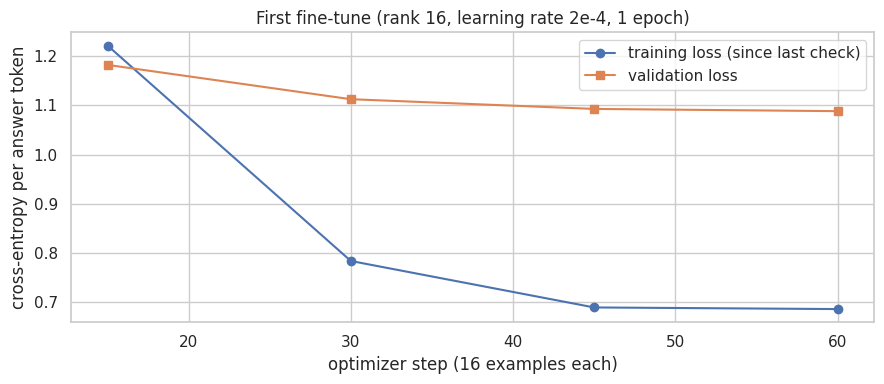

In [68]:
# Visualizing evaluation Metric Score chart
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(h.step, h.train_loss, "o-", label="training loss (since last check)")
ax.plot(h.step, h.val_loss, "s-", label="validation loss")
ax.set_xlabel("optimizer step (16 examples each)")
ax.set_ylabel("cross-entropy per answer token")
ax.set_title("First fine-tune (rank 16, learning rate 2e-4, 1 epoch)")
ax.legend()
save("model3_first_run")

**How the fine-tuning works**

- **LoRA (low-rank adaptation):** the 1.7 billion weights of the pre-trained Qwen3-1.7B-Base stay frozen. Next to every attention and MLP projection, two small matrices A and B (rank r) are trained, and their product B·A is added to the frozen weight. With rank 16 this is about 17 million trainable numbers (about 1% of the model), which fits a T4 and cannot "forget" much of what the model already knows.
- **What it learns from:** the trusted community answer for each question, rewritten by a teacher model (Qwen3-4B-Instruct) into a clear help-desk reply that keeps every command of the original (`scripts/refine_answers.py`). Rewrites that lost commands or slipped into the asker's voice were dropped: 3,329 of 4,000 were kept. Forum answers are often personal stories ("I had the same problem...") or very short notes; the refined replies teach the model how a support desk should answer, while keeping the community's fix. The loss is only computed on the answer tokens, so the model learns to answer, not to repeat questions.
- **Learning to stop:** the base model never saw Qwen's chat end token `<|im_end|>` in pre-training (its output weights for that token are tiny), so every training answer ends with the base model's own end token `<|endoftext|>`, which it knows from pre-training. This is how the model learns where an answer ends.
- **Retrieval-augmented fine-tuning:** half of the examples show three library items in front of the question, with the question's own thread removed. The model learns to use a matching solved thread when there is one and to ignore items that do not fit, which is what it will face in the app.
- **Augmentation:** rephrased questions (duplicates) mapped to the original's answer, and off-topic questions mapped to a polite refusal.
- **Training setup:** fp16 mixed precision on the T4, AdamW, a cosine learning-rate schedule with warm-up, 16 examples per step, early stopping on the validation loss of held-out refined answers, and a time budget so the run fits a free Colab session.
- **The first run** above uses common default settings (rank 16, alpha 32, learning rate 2e-4) on about 1,000 examples (600 threads with rephrasings and refusals) for one epoch. It also measures the training speed, which sets the size of the final run.

#### 2. Cross- Validation & Hyperparameter Tuning

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

step 15/62  epoch 0.24  train 1.3295  val 1.2194  4896 tok/s  0.4 min


step 30/62  epoch 0.49  train 0.8091  val 1.1434  4779 tok/s  0.8 min


step 45/62  epoch 0.73  train 0.7064  val 1.1178  4728 tok/s  1.2 min


step 60/62  epoch 0.98  train 0.7031  val 1.1127  4733 tok/s  1.6 min


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

... (7 outputs left out)

step 45/62  epoch 0.73  train 0.6926  val 1.0988  4728 tok/s  1.2 min


step 60/62  epoch 0.98  train 0.6912  val 1.0946  4694 tok/s  1.6 min


,final val loss,best val loss
r16 a32 lr2e-4,1.0883,1.0883
r8 a16 lr2e-4,1.1127,1.1127
r16 a32 lr5e-4,1.0633,1.0633
r32 a64 lr1e-4,1.0946,1.0946


best setting: r16 a32 lr5e-4


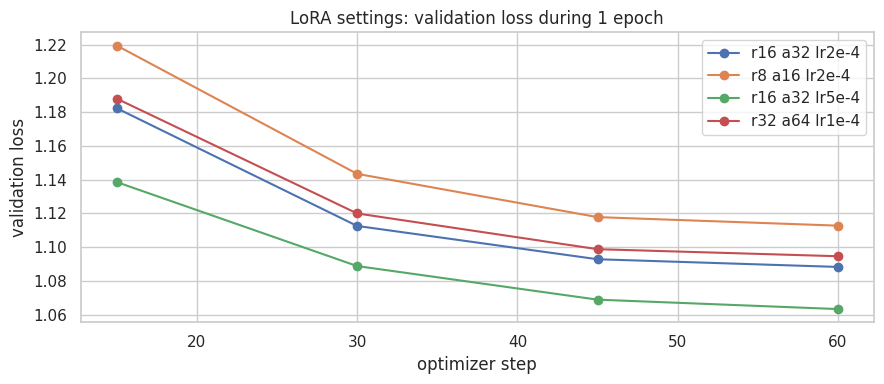

In [69]:
# ML Model - 3 Implementation with hyperparameter optimization techniques
# A small grid over the LoRA rank and the learning rate, each run on the same examples for 1 epoch,
# compared on the validation loss (one fine-tune is too expensive for cross-validation).
t0 = time.time()
for name, (r, alpha, lr) in {"r8 a16 lr2e-4": (8, 16, 2e-4), "r16 a32 lr5e-4": (16, 32, 5e-4), "r32 a64 lr1e-4": (32, 64, 1e-4)}.items():
    model, hh = run(r, alpha, lr, sweep_ex)
    SWEEP[name] = hh
    del model
    free_gpu()
sweep_tab = pd.DataFrame({k: {"final val loss": v.val_loss.iloc[-1], "best val loss": v.val_loss.min()} for k, v in SWEEP.items()}).T
display(sweep_tab.round(4))
best_cfg = sweep_tab["best val loss"].idxmin()
R, ALPHA, LR = {"r16 a32 lr2e-4": (16, 32, 2e-4), "r8 a16 lr2e-4": (8, 16, 2e-4), "r16 a32 lr5e-4": (16, 32, 5e-4), "r32 a64 lr1e-4": (32, 64, 1e-4)}[best_cfg]
TIMES["model 3 sweep"] = time.time() - t0
print("best setting:", best_cfg)
fig, ax = plt.subplots(figsize=(9, 4))
for k, v in SWEEP.items():
    ax.plot(v.step, v.val_loss, "o-", label=k)
ax.set_xlabel("optimizer step")
ax.set_ylabel("validation loss")
ax.set_title("LoRA settings: validation loss during 1 epoch")
ax.legend()
save("model3_sweep")

#### 3. The final fine-tuning run

The number of training examples is set from the speed measured above, so the run fits the time budget (`TRAIN_MINUTES`) of a free Colab session. Training stops early if the validation loss stops improving, and the best checkpoint is kept.

3,462 training examples (3,129 threads + rephrasings + refusals), 3 epochs, 649 steps


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030


step 64/651  epoch 0.30  train 1.0760  val 1.0450  6519 tok/s  1.5 min


step 128/651  epoch 0.59  train 0.9412  val 1.0260  6521 tok/s  3.0 min


step 192/651  epoch 0.89  train 0.9055  val 1.0195  6540 tok/s  4.5 min


step 256/651  epoch 1.18  train 0.8151  val 1.0380  6549 tok/s  6.1 min


step 320/651  epoch 1.48  train 0.7161  val 1.0403  6545 tok/s  7.5 min


step 384/651  epoch 1.78  train 0.7140  val 1.0386  6546 tok/s  9.0 min
early stopping: the validation loss stopped improving


training took 9.2 min; best validation loss 1.0195


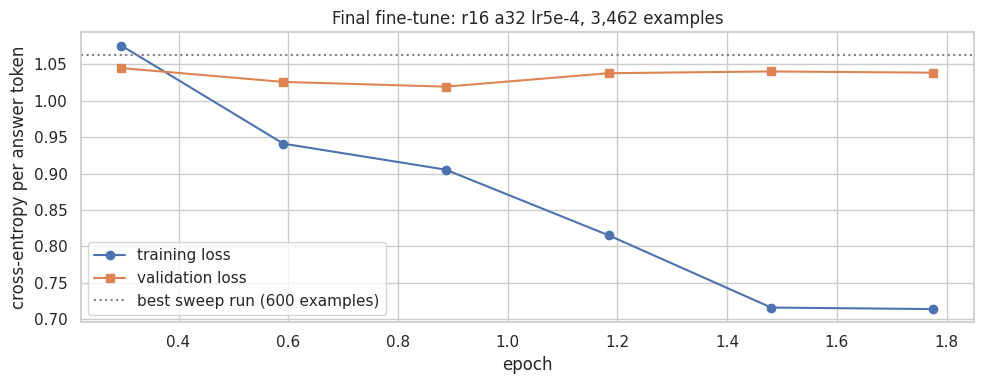

In [70]:
# Final fine-tune with the best LoRA setting, sized to the time budget
t0 = time.time()
mean_tokens = np.mean([len(e["prompt"]) + len(e["completion"]) for e in sweep_ex])
extra = 1 + N["paraphrase_share"] + N["refusals"] / max(1, N["train_max"])
n_main = int(min(N["train_max"], len(rtrain), 0.85 * TRAIN_MINUTES * 60 * TOKENS_PER_S / (EPOCHS * mean_tokens * extra)))
n_main = max(n_main, min(len(rtrain), 2 * N["sweep"]))
train_ex = training_set(n_main, seed=SEED)
steps = len(train_ex) * EPOCHS // (TRAIN["batch_size"] * TRAIN["grad_accum"])
print(f"{len(train_ex):,} training examples ({n_main:,} threads + rephrasings + refusals), {EPOCHS} epochs, {steps:,} steps")
base, _ = itbot.load_llm(BASE_MODEL, DEVICE)
ft = itbot.add_lora(base, r=R, alpha=ALPHA)
ft.print_trainable_parameters()
history = itbot.train_lora(ft, tok, train_ex, val_ex, lr=LR, epochs=EPOCHS, eval_every=max(1, steps // 10), patience=3,
                           max_minutes=TRAIN_MINUTES, **TRAIN)
base_dtype = next(p for n, p in ft.named_parameters() if "lora_" not in n).dtype
for n, p in ft.named_parameters():
    if "lora_" in n:
        p.data = p.data.to(base_dtype)
ft.save_pretrained("models/lora_adapter")
history.to_csv("outputs/training_history.csv", index=False)
TIMES["model 3 final training"] = time.time() - t0
print(f"training took {TIMES['model 3 final training'] / 60:.1f} min; best validation loss {history.val_loss.min():.4f}")
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(history.epoch, history.train_loss, "o-", label="training loss")
ax.plot(history.epoch, history.val_loss, "s-", label="validation loss")
ax.axhline(SWEEP[best_cfg].val_loss.iloc[-1], color="grey", ls=":", label="best sweep run (600 examples)")
ax.set_xlabel("epoch")
ax.set_ylabel("cross-entropy per answer token")
ax.set_title(f"Final fine-tune: {best_cfg}, {len(train_ex):,} examples")
ax.legend()
save("model3_final_training")

,rougeL,bertscore,semantic,command_recall,words
"1. search bot, BM25 default",0.104,0.815,0.693,0.123,124.577
"1. search bot, tuned",0.115,0.818,0.730,0.182,125.877
2. pre-trained as is,0.096,0.787,0.700,0.177,190.013
2. pre-trained + library,0.093,0.786,0.699,0.197,197.840
3. fine-tuned,0.144,0.829,0.776,0.279,108.077
3. fine-tuned + library,0.147,0.828,0.779,0.288,109.057


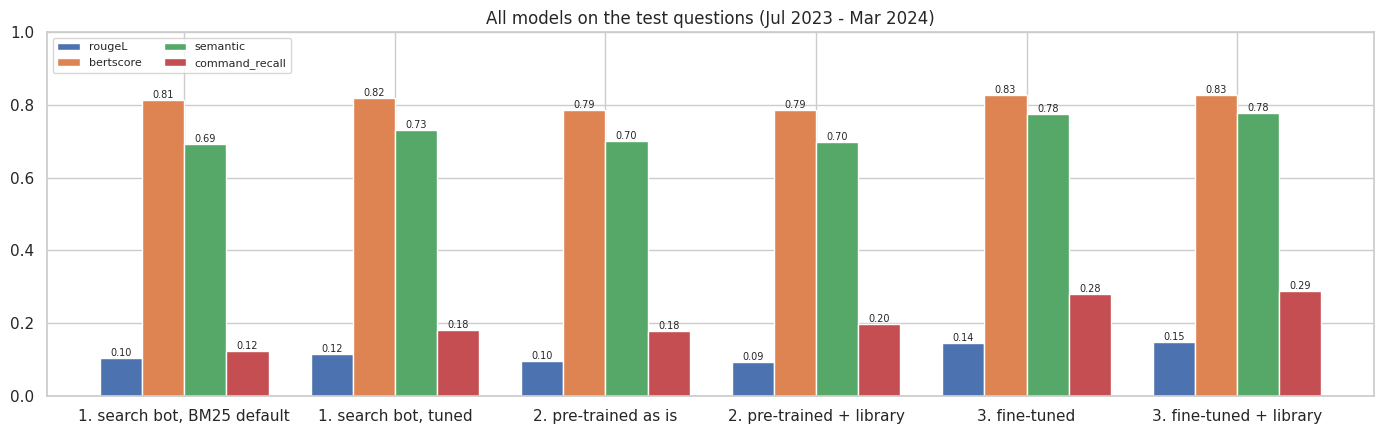

In [71]:
# Evaluate the fine-tuned model on the test, future and off-topic questions, with and without the library
t0 = time.time()
ft.eval()
for split, df in (("test", test_q), ("future", future_q)):
    score("3. fine-tuned", itbot.generate(ft, tok, prompts_for(df, False), **GEN), df, split)
    score("3. fine-tuned + library", itbot.generate(ft, tok, prompts_for(df, True, K_LIB), **GEN), df, split)
ANSWERS[("3. fine-tuned + library", "off-topic")] = itbot.generate(ft, tok, prompts_for(None, True, K_LIB, queries=off_q), **GEN)
ANSWERS[("3. fine-tuned", "off-topic")] = itbot.generate(ft, tok, prompts_for(None, False, queries=off_q), **GEN)
TIMES["model 3 evaluation"] = time.time() - t0
cmp3 = pd.DataFrame({k[0]: v.mean(numeric_only=True) for k, v in RESULTS.items() if k[1] == "test"}).T
display(cmp3[["rougeL", "bertscore", "semantic", "command_recall", "words"]].round(3))
fig, ax = plt.subplots(figsize=(14, 4.5))
metric_bars(ax, cmp3, "All models on the test questions (Jul 2023 - Mar 2024)")
save("model3_vs_all")

##### Which hyperparameter optimization technique have you used and why?

**Grid search over the LoRA rank and the learning rate, judged on the validation loss.** Four settings (rank 8, 16 or 32, with alpha = 2 x rank, and learning rates from 1e-4 to 5e-4) were each trained for one epoch on the same examples (600 threads with rephrasings and refusals) and compared on the same validation examples: refined answers of threads held out from training. Cross-validation is not practical here: one fine-tune costs minutes of GPU time, and 5 folds of 4 settings would use most of a free Colab session. The validation loss (cross-entropy per answer token) is a direct, cheap measure of how well the model writes the kind of reply it is trained for, on questions it has not seen. The best setting was then used for the full run, with early stopping on the same validation loss.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

**Yes.** The grid found rank 16 with learning rate 5e-4 best (validation loss 1.063 after one epoch, against 1.088 for the default rank 16 / 2e-4, 1.113 for rank 8 and 1.095 for rank 32). The final run with this setting on all 3,462 examples reached a validation loss of **1.020** after 0.9 epochs; early stopping ended training at 1.8 epochs, when the loss had risen three times, and restored the best weights.

Compared with the pre-trained model (ML Model 2), on the 300 test questions:

| | pre-trained as is | fine-tuned |
|---|---|---|
| command recall | 0.177 | **0.279** (+58%) |
| semantic similarity | 0.700 | **0.776** |
| BERTScore | 0.787 | **0.829** |
| ROUGE-L | 0.096 | **0.144** (+50%) |
| off-topic questions declined | 1.3% | **100%** |
| words per answer | 190 (rarely ends) | **108** |

## ***Final comparison of the models***

All five systems on the same questions:

- **Test:** questions from July 2023 to March 2024. They were never used for training, and they are not in the library.
- **Future:** questions asked after the dump, from April 2024 to November 2026.
- **Off-topic:** questions from non-IT sites, which the bot should decline.

The numbers come with 95% bootstrap confidence intervals. After that come the perplexity of the trusted answers, a pairwise LLM judge, a breakdown by topic and the speed.

,split,system,rougeL,bertscore,semantic,command_recall,words,refused (should be 0%)
0,test,"1. search bot, tuned",0.115 (0.109-0.122),0.818 (0.815-0.821),0.730 (0.721-0.739),0.182 (0.153-0.211),126,0.0%
1,test,2. pre-trained as is,0.096 (0.089-0.104),0.787 (0.782-0.792),0.700 (0.685-0.714),0.177 (0.149-0.211),190,0.3%
2,test,2. pre-trained + library,0.093 (0.085-0.101),0.786 (0.781-0.791),0.699 (0.685-0.714),0.197 (0.163-0.234),198,1.3%
3,test,3. fine-tuned,0.144 (0.138-0.151),0.829 (0.826-0.831),0.776 (0.768-0.785),0.279 (0.247-0.313),108,0.0%
4,test,3. fine-tuned + library,0.147 (0.141-0.154),0.828 (0.826-0.831),0.779 (0.771-0.788),0.288 (0.257-0.321),109,0.0%
5,future,"1. search bot, tuned",0.114 (0.107-0.122),0.819 (0.815-0.822),0.719 (0.708-0.728),0.118 (0.091-0.150),113,0.0%
6,future,2. pre-trained as is,0.082 (0.073-0.091),0.784 (0.778-0.791),0.673 (0.655-0.692),0.145 (0.114-0.182),175,0.5%
7,future,2. pre-trained + library,0.094 (0.085-0.103),0.790 (0.784-0.796),0.706 (0.689-0.722),0.128 (0.099-0.159),189,0.5%
8,future,3. fine-tuned,0.138 (0.131-0.144),0.824 (0.822-0.827),0.765 (0.755-0.775),0.223 (0.187-0.258),107,0.0%
9,future,3. fine-tuned + library,0.139 (0.132-0.147),0.823 (0.820-0.826),0.770 (0.760-0.780),0.224 (0.191-0.257),108,0.0%


off-topic questions declined (should be 100%): {'2. pre-trained as is': '1.3%', '2. pre-trained + library': '2.0%', '3. fine-tuned': '100.0%', '3. fine-tuned + library': '99.3%'}


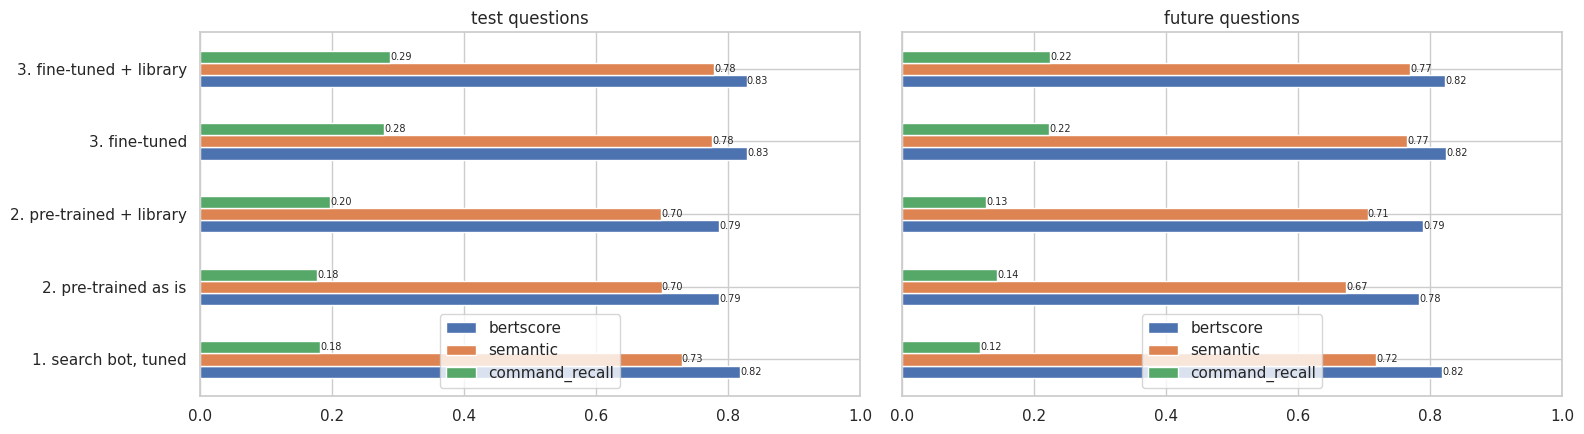

In [72]:
# One table for everything: mean scores with 95% bootstrap intervals, refusal rates
def boot_ci(x, n=1000, seed=SEED):
    x = np.asarray(pd.Series(x).dropna())
    if len(x) < 2:
        return (np.nan, np.nan)
    r = np.random.default_rng(seed)
    m = [x[r.integers(0, len(x), len(x))].mean() for _ in range(n)]
    return tuple(np.percentile(m, [2.5, 97.5]))

order = ["1. search bot, tuned", "2. pre-trained as is", "2. pre-trained + library", "3. fine-tuned", "3. fine-tuned + library"]
rows = []
for split in ("test", "future"):
    for name in order:
        s = RESULTS.get((name, split))
        if s is None:
            continue
        row = {"split": split, "system": name}
        for m in ("rougeL", "bertscore", "semantic", "command_recall"):
            lo, hi = boot_ci(s[m])
            row[m] = f"{s[m].mean():.3f} ({lo:.3f}-{hi:.3f})"
        row["words"] = round(s.words.mean())
        row["refused (should be 0%)"] = f"{s.refused.mean():.1%}"
        rows.append(row)
final = pd.DataFrame(rows)
display(final)
off = pd.Series({name: np.mean([itbot.is_refusal(a) for a in ANSWERS[(name, "off-topic")]])
                 for name in ["2. pre-trained as is", "2. pre-trained + library", "3. fine-tuned", "3. fine-tuned + library"]})
print("off-topic questions declined (should be 100%):", (off * 100).round(1).astype(str).add("%").to_dict())
summary = pd.DataFrame({f"{n} | {s}": v.mean(numeric_only=True) for (n, s), v in RESULTS.items()}).T
summary.to_csv("outputs/model_comparison.csv")
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
for a, split in zip(ax, ("test", "future")):
    t = pd.DataFrame({n: RESULTS[(n, split)][["bertscore", "semantic", "command_recall"]].mean() for n in order if (n, split) in RESULTS}).T
    t.plot(kind="barh", ax=a)
    a.set_xlim(0, 1)
    a.set_title(f"{split} questions")
    for c in a.containers:
        a.bar_label(c, fmt="%.2f", fontsize=7)
save("final_comparison")

- On the **test questions**, the fine-tuned bot leads on all four metrics, and its 95% intervals do not overlap with the pre-trained model's: semantic similarity 0.776 (0.768-0.785) against 0.700 (0.685-0.714), command recall 0.279 (0.247-0.313) against 0.177 (0.149-0.211), BERTScore 0.829 against 0.787, ROUGE-L 0.144 against 0.096.
- It also beats the search bot on all four, including BERTScore (0.829 against 0.818), which a bot that returns human answers usually wins.
- On the **future questions** (April 2024 to November 2026) the gains hold: semantic similarity 0.673 to 0.765 and command recall 0.145 to 0.223 (+54%).
- The fine-tuned bot declines **100%** of the off-topic questions (99.3% with the library), against 1.3% for the pre-trained model, and wrongly refuses none of the IT questions.
- Its answers are 108 words long, close to the 83-word median of a community answer, where the pre-trained model writes 190 words and rarely stops.

perplexity of 200 held-out refined answers: pre-trained model as is 4.1 -> fine-tuned 2.8 (lower for the fine-tuned model on 100%)
perplexity of the trusted answers: pre-trained model as is 8.9 -> fine-tuned 10.6
lower for the fine-tuned model on 2% of the 294 test answers (Wilcoxon p = 1)


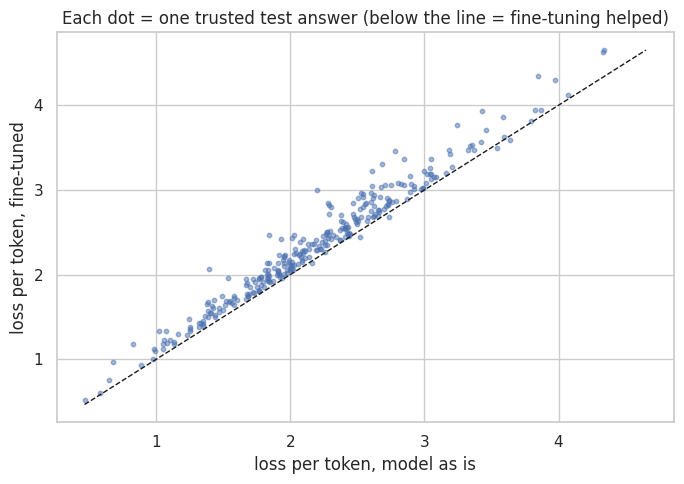

In [73]:
# How likely does each model find the trusted answer? (perplexity, lower = the model "expects" the right answer)
t0 = time.time()
ppl_ex = [itbot.encode_example(tok, itbot.build_messages(q), a, max_len=1536) for q, a in zip(questions(test_q), test_q.answer)]
keep = [i for i, e in enumerate(ppl_ex) if e is not None]
ppl_ex = [ppl_ex[i] for i in keep]
nll_ft = itbot.answer_nll(ft, tok, ppl_ex, 4)
with ft.disable_adapter():
    nll_base = itbot.answer_nll(ft, tok, ppl_ex, 4)
# the same on held-out refined answers: the style the model was trained to write
ppl_ref = [itbot.encode_example(tok, itbot.build_messages(q), a, max_len=1536) for q, a in zip(questions(r_val), r_val.refined)]
ppl_ref = [e for e in ppl_ref if e is not None]
nr_ft = itbot.answer_nll(ft, tok, ppl_ref, 4)
with ft.disable_adapter():
    nr_base = itbot.answer_nll(ft, tok, ppl_ref, 4)
print(f"perplexity of {len(ppl_ref)} held-out refined answers: pre-trained model as is {np.exp(nr_base.mean()):.1f} -> "
      f"fine-tuned {np.exp(nr_ft.mean()):.1f} (lower for the fine-tuned model on {(nr_ft < nr_base).mean():.0%})")
w = stats.wilcoxon(nll_base, nll_ft, alternative="greater")
print(f"perplexity of the trusted answers: pre-trained model as is {np.exp(nll_base.mean()):.1f} -> fine-tuned {np.exp(nll_ft.mean()):.1f}")
print(f"lower for the fine-tuned model on {(nll_ft < nll_base).mean():.0%} of the {len(keep)} test answers (Wilcoxon p = {w.pvalue:.2g})")
plt.figure(figsize=(7, 5))
plt.scatter(nll_base, nll_ft, s=10, alpha=0.5)
lim = [min(nll_base.min(), nll_ft.min()), max(nll_base.max(), nll_ft.max())]
plt.plot(lim, lim, "k--", lw=1)
plt.xlabel("loss per token, model as is")
plt.ylabel("loss per token, fine-tuned")
plt.title("Each dot = one trusted test answer (below the line = fine-tuning helped)")
save("final_perplexity")
TIMES["perplexity"] = time.time() - t0

- **On held-out refined answers**, the style the model was trained to write, perplexity falls from **4.1 to 2.8**, and it is lower for the fine-tuned model on 100% of the 200 answers.
- **On the raw community answers** it rises from 8.9 to 10.6. This is expected: the model was trained to write clear help-desk replies, not forum posts ("I had the same problem..."), so it now expects the raw forum text a little less. Perplexity on raw answers measures how well a model imitates the forum, which was not the goal; the judges and the answer metrics measure what users get.

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/243 [00:00<?, ?it/s]

,judge,match-up,fine-tuned + library better,95% range,other better
0,Qwen3-4B-Instruct-2507,fine-tuned + library vs pre-trained + library,0.653,0.58-0.73,0.347
1,Qwen3-4B-Instruct-2507,fine-tuned + library vs pre-trained as is,0.667,0.59-0.74,0.333
2,Qwen3-4B-Instruct-2507,fine-tuned + library vs search bot,0.667,0.59-0.74,0.333
3,phi-4,fine-tuned + library vs pre-trained + library,0.727,0.66-0.80,0.273
4,phi-4,fine-tuned + library vs pre-trained as is,0.673,0.60-0.75,0.327
5,phi-4,fine-tuned + library vs search bot,0.680,0.61-0.75,0.320


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

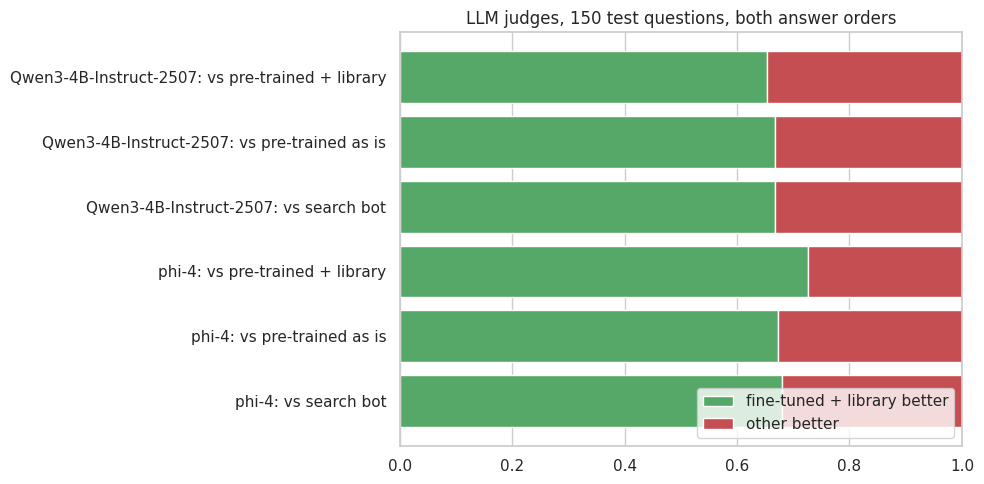

In [74]:
# Bigger models as judges: which answer solves the problem better? Each pair is judged in both orders.
# The main judge is Qwen3-4B-Instruct; on a GPU with 40+ GB, Phi-4 (14B, another model family) judges as well.
t0 = time.time()
del ft, base             # the adapter is saved, so the fine-tuned model is reloaded after the judges have finished
free_gpu()
jq = test_q.head(N["judge"])
pairs = {"fine-tuned + library vs pre-trained + library": ("3. fine-tuned + library", "2. pre-trained + library"),
         "fine-tuned + library vs pre-trained as is": ("3. fine-tuned + library", "2. pre-trained as is"),
         "fine-tuned + library vs search bot": ("3. fine-tuned + library", "1. search bot, tuned")}
judges = [JUDGE_MODEL] + ([SECOND_JUDGE] if GPU_GB > 40 and not QUICK else [])
JUDGE, rows = {}, []
for jname in judges:
    judge, jtok = itbot.load_llm(jname, DEVICE, dtype=torch.bfloat16 if "phi" in jname.lower() else None)
    if jtok.pad_token is None:
        jtok.pad_token = jtok.eos_token
    for label, (x, y) in pairs.items():
        items = [{"question": q, "reference": r, "x": a, "y": b} for q, r, a, b in
                 zip(questions(jq), jq.answer, ANSWERS[(x, "test")][: len(jq)], ANSWERS[(y, "test")][: len(jq)])]
        v = itbot.judge_pairs(judge, jtok, items, batch_size=4 if DEVICE == "cuda" else 1)
        JUDGE[(jname, label)] = v
        w = (v.x_better > v.y_better).mean()
        se = np.sqrt(w * (1 - w) / len(v))
        rows.append({"judge": jname.split("/")[-1], "match-up": label, "fine-tuned + library better": w,
                     "95% range": f"{max(0, w - 1.96 * se):.2f}-{min(1, w + 1.96 * se):.2f}",
                     "other better": (v.y_better > v.x_better).mean()})
    del judge
    free_gpu()
jt = pd.DataFrame(rows)
display(jt.round(3))
ft, _ = itbot.load_llm(BASE_MODEL, DEVICE, adapter="models/lora_adapter")
fig, ax = plt.subplots(figsize=(10, 1.4 + 0.6 * len(jt)))
lab = jt.judge + ": " + jt["match-up"].str.replace("fine-tuned + library vs ", "vs ")
ax.barh(lab, jt["fine-tuned + library better"], color="#55a868", label="fine-tuned + library better")
ax.barh(lab, jt["other better"], left=jt["fine-tuned + library better"], color="#c44e52", label="other better")
ax.set_xlim(0, 1)
ax.invert_yaxis()
ax.legend(loc="lower right")
ax.set_title(f"LLM judges, {len(jq)} test questions, both answer orders")
save("final_judge")
TIMES["judge"] = time.time() - t0

Each judge saw the question, the trusted community answer and two answers in both orders (to cancel the known bias towards the first answer), and chose the better one or a tie.

| Judge | Match-up | Fine-tuned + library better | 95% range |
|---|---|---|---|
| Qwen3-4B-Instruct | vs pre-trained + library | 65.3% | 58-73% |
| Qwen3-4B-Instruct | vs pre-trained as is | 66.7% | 59-74% |
| Qwen3-4B-Instruct | vs search bot | 66.7% | 59-74% |
| Phi-4 (14B, Microsoft) | vs pre-trained + library | **72.7%** | 66-80% |
| Phi-4 (14B, Microsoft) | vs pre-trained as is | 67.3% | 60-75% |
| Phi-4 (14B, Microsoft) | vs search bot | 68.0% | 61-75% |

Two judges from different model families agree, and the lower end of every interval is well above 50%, so the fine-tuned bot is preferred about two times out of three. Phi-4 is the more independent judge: Qwen3-4B-Instruct also wrote the refined training answers, so its scores could favour their style, yet Phi-4 rates the bot even higher.

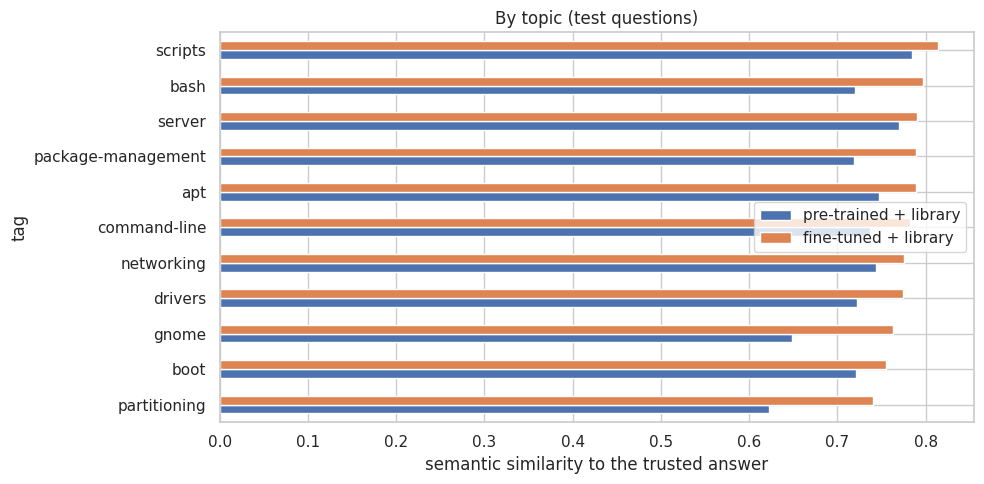

QUESTION: Dual boot Ubuntu and Windows 11 on my organization managed school laptop | tags: ['dual-boot', 'secure-boot']

FINAL BOT:
 To safely dual boot Ubuntu and Windows 11 without affecting your school’s management, follow these steps. Disable Secure Boot and BitLocker to allow both operating systems to boot properly. Use a live USB to test the setup before making changes.

1. Download a live Ubuntu ISO from https://ubuntu.com/download/desktop  
2. Create a bootable USB using Rufus or BalenaEtcher  
3. Restart your laptop and press F12 to select the USB device  
4. Choose "Try Ubuntu" to verify the system boots  
5. Open BIOS/UEFI settings and disable Secure Boot  
6. Save changes and ...

TRUSTED ANSWER:
 "*I want this to go unnoticed by my organization*"

**DON'T DO IT!**

Never make changes to hardware that you don't own without written permission from the owner.

In some places, unauthorized changes may result in disciplinary action: Firing, Suspension, Expulsion. Possibly crimi

In [75]:
# Where does the final bot do well or badly? Semantic similarity by topic, and the weakest answers
fin, base = RESULTS[("3. fine-tuned + library", "test")], RESULTS[("2. pre-trained + library", "test")]
by_tag = []
for t in topic_tags[:12]:
    m = test_q.tags.map(lambda ts: t in ts).values
    if m.sum() >= (5 if not QUICK else 1):
        by_tag.append({"tag": t, "questions": int(m.sum()), "fine-tuned + library": fin.semantic[m].mean(), "pre-trained + library": base.semantic[m].mean()})
by_tag = pd.DataFrame(by_tag).set_index("tag").sort_values("fine-tuned + library")
by_tag[["pre-trained + library", "fine-tuned + library"]].plot(kind="barh", figsize=(10, 5))
plt.xlabel("semantic similarity to the trusted answer")
plt.title("By topic (test questions)")
save("final_by_tag")
worst = np.argsort(fin.semantic.values)[:3]
for i in worst:
    print("=" * 100); print("QUESTION:", test_q.title[i], "| tags:", test_q.tags[i])
    print("\nFINAL BOT:\n", itbot.shorten(ANSWERS[("3. fine-tuned + library", "test")][i], 90))
    print("\nTRUSTED ANSWER:\n", itbot.shorten(test_q.answer[i], 90))

- The fine-tuned bot improves on **every topic**. The largest gains are on `partitioning` (semantic similarity 0.62 to 0.74) and `gnome` (0.65 to 0.76), topics where the pre-trained model was weakest; the smallest gains are on `server` and `boot`.
- **The weakest answers show three limits:**
  1. **Policy questions:** for dual-booting a school-managed laptop "unnoticed", the community said "don't do it", while the bot gave the steps. It does not recognise when a question should not be helped.
  2. **A neighbouring question:** for udev wildcards, the bot wrote a working udev rule but did not answer whether wildcards are allowed.
  3. **Long or dated procedures:** for NVIDIA drivers broken after an update, the community fix was `sudo dkms autoinstall`; the bot gave a long repository-based install with an old key method.

These are the cases for a human review and for future work (safety rules, more recent training data).

In [76]:
# Speed: one question at a time, like a user of the chat app
bot_eval = itbot.SupportBot(ft, tok, lib, searcher, k=K_LIB)
q = questions(test_q.head(3 if not QUICK else 1))
lat = []
for x in q:
    t0 = time.time()
    a, rows, sim = bot_eval.respond(x, max_new_tokens=GEN["max_new_tokens"])
    n_tok = len(tok(a, add_special_tokens=False)["input_ids"])
    lat.append({"seconds": time.time() - t0, "answer tokens": n_tok, "tokens per second": n_tok / (time.time() - t0)})
lat = pd.DataFrame(lat)
display(lat.round(2))
pd.DataFrame([{**{k: v / 60 for k, v in TIMES.items()}}]).T.rename(columns={0: "minutes"}).round(1)

,seconds,answer tokens,tokens per second
0,5.17,125,24.16
1,5.93,145,24.45
2,4.89,120,24.52


,minutes
model 1,0.2
model 1 tuning,9.0
model 2,2.1
model 2 tuning,12.3
model 3 first run,2.1
model 3 sweep,5.0
model 3 final training,9.2
model 3 evaluation,10.3
perplexity,0.5
judge,9.0


One answer at a time, as in the chat app, takes about **5 seconds** for 120 to 145 tokens (about 24 tokens per second) on the RTX 6000 Ada. A T4 is slower; I expect roughly 10 to 15 seconds per answer there (not measured in this run). The app streams the text as it is written, so the user sees the start of the answer within a second. For the evaluation, 48 answers were generated in parallel.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

1. **Command recall:** the most direct measure of a correct fix. If the bot names the right package or command, the user can solve the problem without opening a ticket.
2. **LLM judge win rate (two judges):** the closest measure to a support lead reading both answers and choosing the better one, including correctness, clarity and safety.
3. **Refusal rates:** declining off-topic questions protects the company's scope; not refusing real IT questions protects the user.
4. **Semantic similarity and BERTScore:** whether the answer is about the same solution as the trusted answer, even in other words.
5. **Seconds per answer:** whether users will wait for it and which hardware is needed.

ROUGE-L and perplexity are reported as supporting evidence, not as business targets.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

**ML Model 3 with the library (fine-tuned Qwen3-1.7B-Base + retrieval) is the final bot.**
- It is the best system on every automatic metric on the test questions and on the questions asked after the dump.
- Both judges prefer it in 65% to 73% of comparisons, against the pre-trained model with or without the library and against the search bot, with the lower ends of all 95% intervals above 58%.
- It declines 99-100% of off-topic questions and wrongly refuses none of the IT questions.
- The library adds a little on top of the fine-tuning (command recall 0.279 to 0.288) and, more importantly, gives the user links to the solved threads and guides behind each answer, so an answer can be checked.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

Two explanation tools were used, one for single answers and one for the model itself:

1. **Leave-one-out attribution of the library items.** For a given answer, each of the items shown to the model is removed in turn, and the notebook measures how much less likely the same answer becomes (the increase in loss per token). A large increase means the answer relied on that item. This is the "feature importance" of a retrieval-augmented bot: the features are the sources. It also shows how much the answer relies on the library as a whole (the "no library items" row).
2. **The size of the LoRA update per layer.** For each adapted projection the norm of B·A (times alpha / r) shows how much fine-tuning changed it. This shows where in the network the domain knowledge and the answer style were added.

QUESTION: What is the recommended way to install Postman?
ANSWER (start): Use the official Postman installer for Ubuntu 22.04 because it ensures you get the latest version directly from the source. This method avoids dependency issues and provides full functionality.

1. Open your terminal and run:  
```  
wget https://dl.pstmn.io/download/latest/linux64  
```  

2. Navigate into the directory containing the installer:  
```  
cd linux64
``` ...


,item,title,nll_increase
0,1,Can't get Postman installed and working on Ubuntu,-0.000
1,2,Where on earth is the Postman application on my 20.04 desktop?,0.004
2,3,Install and configure Postfix,0.010
3,none,(no library items at all),0.002


QUESTION: Nvidia Cuda Installation Package Conflicts
ANSWER (start): To resolve the conflict between CUDA and NVIDIA drivers, use the official NVIDIA repository instead of the default one. This ensures compatibility and avoids missing dependencies.

1. Remove the existing CUDA installation:  
```  
sudo apt remove --purge cuda  
```  

2. Add the official NVIDIA repository:  
```  
sudo apt-add-repository https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2004/x86_64  
``` ...


,item,title,nll_increase
0,1,How to solve “unmet dependencies while installing CUDA-9-0 on Ubuntu 18.04”,0.006
1,2,Ubuntu 14.04 : Installing cuda 7,-0.000
2,3,can't install nvidia-driver-toolkit on Ubuntu 20.04 LTS - needs uninstallable package,0.009
3,none,(no library items at all),0.010


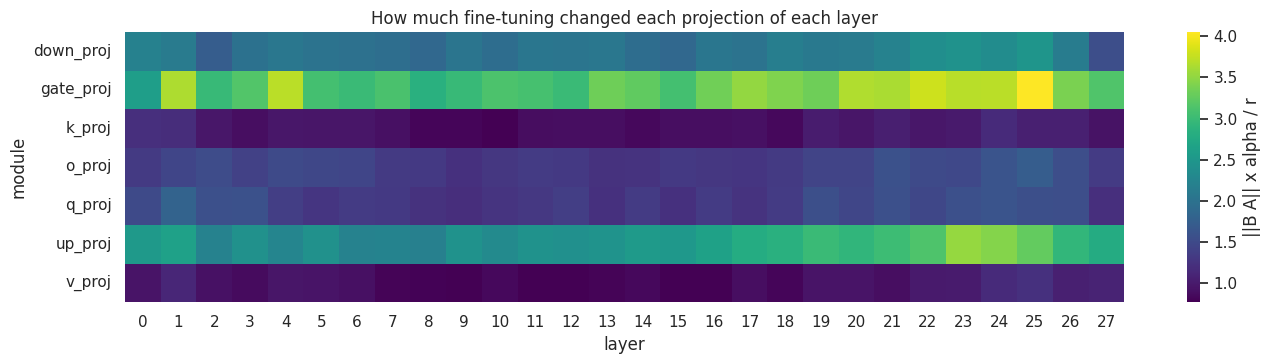

biggest change by module type: {'gate_proj': 3.306, 'up_proj': 2.662, 'down_proj': 2.067, 'q_proj': 1.408, 'o_proj': 1.403, 'k_proj': 0.953, 'v_proj': 0.916}


In [77]:
# Explainability 1: which library item did an answer rely on? (leave-one-out on the answer's likelihood)
for i in range(min(2, len(test_q))):
    qtext = questions(test_q)[i]
    rows = lib_rows(test_q.iloc[[i]], K_LIB)[0]
    answer = ANSWERS[("3. fine-tuned + library", "test")][i]
    att = itbot.context_attribution(ft, tok, qtext, rows, answer)
    print("=" * 100); print("QUESTION:", test_q.title[i]); print("ANSWER (start):", itbot.shorten(answer, 50))
    display(att.round(3))

# Explainability 2: which layers changed most during fine-tuning? Size of each LoRA update ||B A|| x alpha / r
rows = []
for name, mod in ft.named_modules():
    if hasattr(mod, "lora_A") and "default" in getattr(mod, "lora_A", {}):
        A, B = mod.lora_A["default"].weight.float(), mod.lora_B["default"].weight.float()
        delta = (B @ A).norm().item() * mod.scaling["default"]
        layer = int(re.search(r"layers\.(\d+)\.", name).group(1))
        rows.append({"layer": layer, "module": name.split(".")[-1], "update size": delta})
upd = pd.DataFrame(rows).pivot_table(index="module", columns="layer", values="update size")
plt.figure(figsize=(14, 3.8))
sns.heatmap(upd, cmap="viridis", cbar_kws={"label": "||B A|| x alpha / r"})
plt.title("How much fine-tuning changed each projection of each layer")
save("explain_lora_updates")
print("biggest change by module type:", upd.mean(1).sort_values(ascending=False).round(3).to_dict())

- **Library items have little influence on the answers.** Removing any one of the three items changes the likelihood of the bot's own answer by at most 0.01 per token, and removing all of them barely matters either. The fine-tuned model answers mostly from what it learned in training. The sources are still useful to the user as links, but making the model use them more is future work.
- **Fine-tuning changed the MLP layers most.** The largest LoRA updates are in the MLP projections (`gate_proj` 3.3, `up_proj` 2.7, `down_proj` 2.1) rather than the attention projections (`q_proj` and `o_proj` 1.4, `k_proj` and `v_proj` about 0.9), and they are strongest in the later layers (about 20 to 25). The MLP layers are where a transformer stores and produces content, so fine-tuning mostly changed what the model writes (the help-desk style and the fixes), not where it looks in the prompt.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [78]:
# Save the File
# 1. the LoRA adapter (saved after training) 2. the bot's library for deployment: every clean pair (all periods),
# the recent API pairs and the guide passages, with int8 embeddings 3. a model card with the settings and scores
t0 = time.time()
deploy = pd.concat([itbot.thread_items(pd.concat([qa, recent], ignore_index=True)), itbot.doc_items(docs)], ignore_index=True)
deploy = deploy.drop_duplicates("item_id").reset_index(drop=True)
if N["library_quick"]:                       # QUICK test: a small library is enough to check the code
    deploy = pd.concat([deploy[deploy.kind == "doc"], deploy[deploy.kind == "thread"].sample(N["library_quick"], random_state=SEED)], ignore_index=True)
known = dict(zip(lib.item_id, range(len(lib))))
lib_prep_best = prepped_best
new = [i for i, x in enumerate(deploy.item_id) if x not in known]
deploy["prepped"] = [lib_prep_best[known[x]] if x in known else None for x in deploy.item_id]
deploy.loc[new, "prepped"] = [itbot.classic_preprocess(t, **prep_best) for t in deploy.search_text.iloc[new]]
E_deploy = np.zeros((len(deploy), E_lib.shape[1]), dtype=np.float32)
new_set = set(new)
old_pos = [i for i in range(len(deploy)) if i not in new_set]
E_deploy[old_pos] = E_lib[[known[x] for x in deploy.item_id.iloc[old_pos]]]
if new:
    E_deploy[new] = dense.encode(deploy.search_text.iloc[new].tolist())
print(f"{len(new):,} new items embedded, {len(old_pos):,} reused from the evaluation library")
itbot.save_library(deploy.drop(columns=["search_text"]), E_deploy, "models/library")
card = {"base_model": BASE_MODEL, "adapter": "models/lora_adapter", "lora": {"r": R, "alpha": ALPHA, "learning_rate": LR, "epochs_planned": EPOCHS,
        "epochs_done": float(history.epoch.iloc[-1]), "training_examples": len(train_ex), "best_val_loss": float(history.val_loss.min())},
        "search": {"type": SEARCH_TYPE, "embedding_model": EMBED_MODEL,
                   "bm25": {"k1": float(best.k1), "b": float(best.b), "preprocessing": prep_best},
                   "semantic_weight": float(w_best) if w_best else None, "items_shown": int(K_LIB)},
        "library_items": int(len(deploy)), "system_prompt": itbot.SYSTEM_PROMPT, "refusal": itbot.REFUSAL,
        "test_scores": RESULTS[("3. fine-tuned + library", "test")][["rougeL", "bertscore", "semantic", "command_recall"]].mean().round(4).to_dict(),
        "created": time.strftime("%Y-%m-%d")}
json.dump(card, open("models/model_card.json", "w"), indent=1)
print(f"saved {len(deploy):,} library items in {time.time() - t0:.0f} s")
for p in sorted(Path("models").rglob("*")):
    if p.is_file():
        print(f"  {p}  {p.stat().st_size / 1e6:.1f} MB")

2,291 new items embedded, 138,779 reused from the evaluation library


saved 141,070 library items in 6 s
  models/library/embeddings_int8.npy  54.2 MB
  models/library/embeddings_scale.npy  0.6 MB
  models/library/library.parquet  55.1 MB
  models/lora_adapter/README.md  0.0 MB
  models/lora_adapter/adapter_config.json  0.0 MB
  models/lora_adapter/adapter_model.safetensors  34.9 MB
  models/model_card.json  0.0 MB


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [79]:
# Load the File and predict unseen data.
# A fresh start from the saved files only, as the chat app does it.
del ft, base
free_gpu()
card = json.load(open("models/model_card.json"))
model2, tok2 = itbot.load_llm(card["base_model"], DEVICE, adapter=card["adapter"])
lib2, emb2 = itbot.load_library("models/library")
bot = itbot.SupportBot(model2, tok2, lib2, itbot.build_search(card["search"], lib2, emb2, DEVICE), k=card["search"]["items_shown"])
for question in ["After upgrading to Ubuntu 24.04 my Wi-Fi adapter disappeared from the settings. How do I get it back?",
                 "How do I make a Python script run automatically every time the computer starts?",
                 "What is a good recipe for banana bread?"]:
    answer, rows, sim = bot.respond(question)
    print("=" * 100); print("USER:", question); print("\nBOT:", answer)
    if rows is not None:
        print("\nsources:", [f"{r.title[:60]} ({r.url})" for r in rows.itertuples()])

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

USER: After upgrading to Ubuntu 24.04 my Wi-Fi adapter disappeared from the settings. How do I get it back?

BOT: Your Wi-Fi adapter may have been removed during the upgrade due to driver issues. To restore it, reinstall the necessary drivers using the following steps.

1. Open a terminal and run:  
```sudo apt update```

2. Install the required packages:  
```sudo apt install linux-generic-lts-saucy```
```sudo apt install linux-generic-lts-trusty```

3. Reboot your system:  
```sudo reboot```

After rebooting, check if Wi-Fi appears in Settings > Network. If it does, your adapter should now be active.

sources: ['Wifi adapter suddenly disappeared in Ubuntu 22.04.02 LTS (https://askubuntu.com/q/1455967)', 'No WI-FI adapter found after restarting (https://askubuntu.com/q/1194300)', 'Wireless Adapter Vanished after Update in 19.10, Lenovo Xiao (https://askubuntu.com/q/1212095)']


USER: How do I make a Python script run automatically every time the computer starts?

BOT: To run your Python script at startup, create a systemd service that launches your script during boot. This ensures it runs every time the system starts.

1. Create a new service file:  
```  
sudo nano /etc/systemd/system/my-script.service  
```  

2. Add the following content:  
```  
[Unit]  
Description=My Script Service  
After=network.target  

[Service]  
ExecStart=/usr/bin/python3 /path/to/your/script.py  
Restart=always  

[Install]  
WantedBy=multi-user.target  
```  

3. Reload systemd and enable the service:  
```  
sudo systemctl daemon-reload  
sudo systemctl enable my-script.service  
```  

4. Verify it’s active:  
```  
sudo systemctl status my-script.service  
```  

The script will now run automatically at startup.

sources: ['Run a script every time a shell is spawned (https://askubuntu.com/q/560865)', 'Restart a python script every hour or so (https://askubuntu.com/q/1043979)

USER: What is a good recipe for banana bread?

BOT: Sorry, I can only help with Ubuntu and Linux questions, for example installing software, drivers, networking, the terminal or system errors.

sources: ['How to make macros that play sound, activated by a keyboard  (https://askubuntu.com/q/540575)', 'Repeat whole line matches with grep for multiple instances o (https://askubuntu.com/q/862793)', 'How can I use chewing(zhuyin) input method? (https://askubuntu.com/q/1032465)']


The model, its adapter and the library were loaded again from the saved files only, the way the chat app starts. It answered new questions that are not in the data, listed its sources, and declined the question about baking.

### Download the results (Colab)

In [80]:
# Download the trained adapter, the library, the figures and the result tables (Colab only)
import zipfile
with zipfile.ZipFile("itbot_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for folder in ("models", "outputs"):
        for p in Path(folder).rglob("*"):
            if p.is_file() and not (folder == "outputs" and p.suffix == ".parquet"):
                z.write(p)
print(f"itbot_results.zip: {Path('itbot_results.zip').stat().st_size / 1e6:.0f} MB")
if IN_COLAB:
    from google.colab import files
    files.download("itbot_results.zip")

itbot_results.zip: 132 MB


## ***The chat bot***

The bot is a Gradio chat app (`app/app.py` in the repo). The same file runs here on the Colab GPU, with a public link, or on a laptop with `python app/app.py`. It has two tabs:

- **Chat:** the fine-tuned bot with the library. It shows the sources it used and says when it is not sure.
- **Compare:** the same question answered by the pre-trained model as is and by the fine-tuned bot, side by side.

Run the next cell to get the public link for the live demo. The link works while this Colab session is running.

In [81]:
# Start the chat app (on Colab it prints a public gradio.live link)
if not Path("app/app.py").exists():
    itbot.download(f"{RAW_URL}/app/app.py", "app/app.py")
import importlib.util
spec = importlib.util.spec_from_file_location("chat_app", "app/app.py")
chat_app = importlib.util.module_from_spec(spec)
spec.loader.exec_module(chat_app)
demo = chat_app.build_demo(bot, card)
if IN_COLAB or os.environ.get("LAUNCH_APP"):
    demo.launch(share=IN_COLAB, quiet=True)

### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

**What the project achieved**
- **A domain dataset from three sources:** the Ask Ubuntu dump (137,049 clean question-answer pairs out of 414,451 questions), newer and off-topic questions from the Stack Exchange API, and 2,940 passages of the official Ubuntu guides. On top, 3,329 trusted answers were rewritten by a teacher model into clear help-desk replies that keep their commands.
- **A large, measurable effect of fine-tuning.** LoRA fine-tuning (1% of the weights, 9 minutes of training) turned the pre-trained Qwen3-1.7B-Base from a text generator that starts mid-word, repeats itself and answers anything into a support assistant:
  - command recall up 58% (0.177 to 0.279);
  - semantic similarity 0.700 to 0.776, BERTScore 0.787 to 0.829;
  - 100% of off-topic questions declined (from 1.3%), and no real IT question refused;
  - preferred by two independent LLM judges in about two of three comparisons, also against a tuned search bot;
  - the same gains on questions asked up to two and a half years after the training data.

**What I learned**
1. **Clear training targets let a small model learn fast.** Refined answers that keep the community's commands but read like a support reply were enough: 3,462 examples and 9 minutes of LoRA training changed the model's behaviour completely.
2. **A base model needs its own end token.** Qwen3-1.7B-Base never learned the chat token `<|im_end|>` in pre-training (its output weights for that token are tiny), so the training answers end with `<|endoftext|>`, which it already knows. This small detail decides whether a fine-tuned base model stops at the end of its answer.
3. **Several kinds of evaluation are needed.** Validation loss guides training, but word-overlap metrics, refusal rates and two LLM judges from different families together show whether the answers actually help, and reading the answers shows the remaining weak spots.
4. **Semantic search beats keyword search** for support questions (MRR@10 0.227 against 0.135), because users describe the same problem in different words.

**Limitations and next steps**
- The bot can give **outdated advice** from old threads (for example kernel packages from 2014 for a 24.04 Wi-Fi problem). Next step: more recent training data, and preferring recent library items.
- It **relies little on the retrieved threads** (leave-one-out changes of 0.01 per token or less). Next step: training examples where the answer can only be found in the library item.
- It does **not recognise policy and safety questions**. Next step: refusal examples for those cases.
- The LLM judges are a proxy; **a human review** of a sample of answers by IT support staff would confirm the results.

The bot is deployed as a Gradio chat app with sources and a side-by-side comparison with the pre-trained model, and the trained adapter, library and model card are in the GitHub repository.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***